In [13]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [14]:
import numpy as np
import os
import re
import pandas as pd
import matplotlib.pyplot as plt
from types import SimpleNamespace
import torch
import sys 
import tifffile 
from pathlib import Path
import torchio as tio
import ast
import napari
import re
from bioio import BioImage

sys.path.append('/Users/josephinelahmani/Desktop/vxmorph') 
from typing import Tuple
import importlib
import network
import network.models
import scripts.dataset
importlib.reload(network.models)
importlib.reload(network)
importlib.reload(scripts.dataset)
import scripts.utils 
importlib.reload(scripts.utils)
from scripts.utils import reshape_disp, reshape_img, rmse
from scripts.dataset import TractionDataset
from torch.utils.data import DataLoader
from scripts.train import epoch_, update_log
from tqdm import tqdm
import importlib
import network.losses
importlib.reload(network.losses)
import network.functional
importlib.reload(network.functional)
import scripts.train
importlib.reload(scripts.train)
import yaml
import optical_flow.algorithms
importlib.reload(optical_flow.algorithms)
from optical_flow.algorithms import tv_l1, fista_of, hs_of, warp
import scripts.register
importlib.reload(scripts.register)
from scripts.register import register
from scripts.image_preprocessing import get_ugt
import scipy.ndimage as ndi

from quantities_computation import strain_mask, deformation, stress_mask, compute_normals_from_mask_3d, compute_traction_3d
import json
import csv
import torch.nn.functional as F

## Data observation

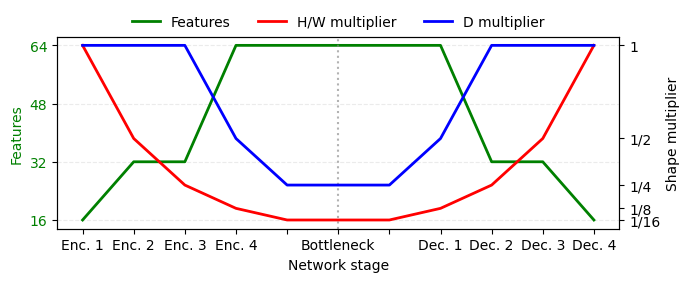

In [53]:
features = [16, 32, 32, 64, 64, 64]

multiplier_HW = [1, 1/2, 1/4, 1/8, 1/16, 1/16]
multiplier_D = [1, 1, 1, 1/2, 1/4, 1/4]
def mirror(values):
    return values + values[-2::-1]

features = mirror(features)
multiplier_HW = mirror(multiplier_HW)
multiplier_D = mirror(multiplier_D)

steps = np.arange(len(features))

fig, ax_left = plt.subplots(figsize=(7, 3))
ax_right = ax_left.twinx()

fig.patch.set_alpha(0)
ax_left.set_facecolor("none")
ax_right.set_facecolor("none")

line_features, = ax_left.plot(
    steps, features,
    color="green", linewidth=2,
    label="Features",
)
ax_left.set_ylabel("Features", color="green")
ax_left.tick_params(axis="y", labelcolor="green")
ax_left.set_yticks([16, 32, 48, 64])

line_hw, = ax_right.plot(
    steps, multiplier_HW,
    color="red", linewidth=2,
    label="H/W multiplier",
)
line_d, = ax_right.plot(
    steps, multiplier_D,
    color="blue", linewidth=2,
    label="D multiplier",
)

ax_right.set_ylabel("Shape multiplier")
ax_right.set_yticks([1/16, 1/8, 1/4, 1/2, 1])
ax_right.set_yticklabels(["1/16", "1/8", "1/4", "1/2", "1"])

ax_left.set_xticks(steps)
ax_left.set_xticklabels([
    "Enc. 1", "Enc. 2", "Enc. 3", "Enc. 4",
    "", "Bottleneck", "",
    "Dec. 1", "Dec. 2", "Dec. 3", "Dec. 4",
])
ax_left.set_xlabel("Network stage")

ax_left.axvline(5, color="gray", linestyle=":", alpha=0.6)
ax_left.grid(axis="y", linestyle="--", alpha=0.25)
ax_left.set_axisbelow(True)

lines = [line_features, line_hw, line_d]
ax_left.legend(
    lines,
    [line.get_label() for line in lines],
    loc="upper center",
    bbox_to_anchor=(0.5, 1.18),
    ncol=3,
    frameon=False,
)

fig.tight_layout()

fig.savefig(
    "features_and_shape.png",
    dpi=300,
    transparent=True,
    bbox_inches="tight",
)

plt.show()

In [65]:
img = np.load(Path('/Users/josephinelahmani/Desktop/nn_dis/data/fractals/fractal_74_13_funcs_img.npy'))
ugt = np.load(Path('/Users/josephinelahmani/Desktop/nn_dis/data/fractals/fractal_74_13_funcs_ugt.npy'))

output_dir = Path('/Users/josephinelahmani/Desktop/nn_dis/data/fractals/')

views = {
    "Face": {
        "angles": (0, 0, 0),
        "perspective": 0,      
    },
    "Dessus": {
        "angles": (90, 0, 0),
        "perspective": 0,
    },
    "Cote": {
        "angles": (0, 90, 0),
        "perspective": 0,
    },
    "Perspective": {
        "angles": (-20, 0, 110),
        "perspective": 45,     
    },
}

viewers = []

for i in range(2):

    for view_name, params in views.items():

        viewer = napari.Viewer(
            title=f"Frame {i} — {view_name}",
            ndisplay=3,
        )
        viewers.append(viewer)

        img_nap = viewer.add_image(
            img[i],
            name=f'Original_{i}',
            interpolation3d='nearest',
            scale=(1.0, 1.0, 1.0),
            colormap='inferno',
        )

        img_nap.bounding_box.visible = True
        img_nap.bounding_box.line_color = 'white'
        img_nap.bounding_box.point_color = 'white'
        img_nap.bounding_box.point_size = 1
        img_nap.bounding_box.opacity = 0.8
        img_nap.bounding_box.blending = 'translucent'

        viewer.camera.angles = params["angles"]
        viewer.camera.perspective = params["perspective"]
        viewer.camera.zoom = 10

napari.run()
    # screenshot_path = output_dir / f'figure_fractal_img_{i}.png'
    # viewer.screenshot(path=str(screenshot_path), canvas_only=True, scale=2)

    #viewer.close()
    

Context leak detected, CoreAnalytics returned false


/opt/anaconda3/envs/voxelmorph/lib/python3.12/site-packages/napari/_vispy/camera.py:58: UserWarning: Gimbal lock detected. Setting third angle to zero since it is not possible to uniquely determine all angles.
  angles = rotation.as_euler('yzx', degrees=True)


In [84]:
# import numpy as np
# import pyvista as pv
# from pathlib import Path

# # img = np.load(
# #     Path('/Users/josephinelahmani/Desktop/nn_dis/data/fractals/fractal_74_13_funcs_img.npy')
# # )

# img = np.load(Path('/Users/josephinelahmani/Desktop/data/3d_synthetic/E_300.0_nu_0.45_nb_zones_2_im_00_seed_01_img.npy'))

# output_dir = Path('/Users/josephinelahmani/Desktop/nn_dis/data/fractals/')
# output_dir.mkdir(parents=True, exist_ok=True)


# def numpy_to_pyvista_grid(volume):
#     """
#     Transforme un volume numpy 3D en ImageData PyVista.
#     """
#     volume = np.asarray(volume, dtype=np.float32)

#     grid = pv.ImageData()
#     grid.dimensions = volume.shape
#     grid.spacing = (1.0, 1.0, 1.0)
#     grid.origin = (0.0, 0.0, 0.0)

#     grid.point_data["values"] = volume.ravel(order="F")

#     return grid


# for i in range(2):
#     volume = img[i]
#     grid = numpy_to_pyvista_grid(volume)

#     plotter = pv.Plotter(
#         shape=(1, 4),
#         window_size=(1800, 400),
#         border=True,
#         off_screen=True, 
#     )

#     plotter.set_background("#151515")

#     volume_kwargs = dict(
#         scalars="values",
#         cmap="inferno",
#         opacity="sigmoid_6",
#         shade=True,
#         blending="composite",
#         show_scalar_bar=False,
#     )

#     plotter.subplot(0, 0)
#     plotter.add_volume(grid, **volume_kwargs)
#     plotter.add_mesh(grid.outline(), color="white", line_width=1)
#     plotter.view_xy()
#     plotter.camera.parallel_projection = True
#     plotter.add_text("XY", color="white", font_size=10)
#     plotter.camera.zoom(1.3)
    
#     plotter.subplot(0, 1)
#     plotter.add_volume(grid, **volume_kwargs)
#     plotter.add_mesh(grid.outline(), color="white", line_width=1)
#     plotter.view_xz()
#     plotter.camera.parallel_projection = True
#     plotter.add_text("XZ", color="white", font_size=10)
#     plotter.camera.zoom(1.3)
    
#     plotter.subplot(0, 2)
#     plotter.add_volume(grid, **volume_kwargs)
#     plotter.add_mesh(grid.outline(), color="white", line_width=1)
#     plotter.view_yz()
#     plotter.camera.parallel_projection = True
#     plotter.add_text("YZ", color="white", font_size=10)
#     plotter.camera.zoom(1.3)
    
#     plotter.subplot(0, 3)
#     plotter.add_volume(grid, **volume_kwargs)
#     plotter.add_mesh(grid.outline(), color="white", line_width=1)
#     plotter.view_isometric()
#     plotter.camera.parallel_projection = False
#     plotter.add_text("Isometric", color="white", font_size=10)
#     plotter.camera.zoom(1.0)
    
#     output_path = output_dir / f"fractal_{i}_4views.png"

#     plotter.show(
#         screenshot=str(output_path),
#         auto_close=True,
#     )

In [126]:
img = np.load(Path('/Users/josephinelahmani/Desktop/data/3d_synthetic/E_300.0_nu_0.45_nb_zones_2_im_00_seed_01_img.npy'))
#img = np.load(Path('/Users/josephinelahmani/Desktop/nn_dis/data/fractals/fractal_74_13_funcs_img.npy'))

viewer = napari.Viewer()
img_ = viewer.add_image(
    img[0],
    interpolation3d="nearest",
    scale=(2.0, 1.0, 1.0)
)
img_.bounding_box.visible = True
img_.bounding_box.line_color = "white"
img_.bounding_box.point_color = "white"
img_.bounding_box.point_size = 1
img_.bounding_box.opacity = 0.8
img_.bounding_box.blending = "translucent"

viewer.dims.ndisplay = 3
viewer.camera.angles = (-40, 0, 110)
viewer.camera.zoom = 4

output_dir = Path("/Users/josephinelahmani/Desktop/nn_dis/data/fractals/")
output_path = output_dir / "frac0.png"
viewer.screenshot(
    path=output_path,
    canvas_only=True,
    flash=False,
)
napari.run()

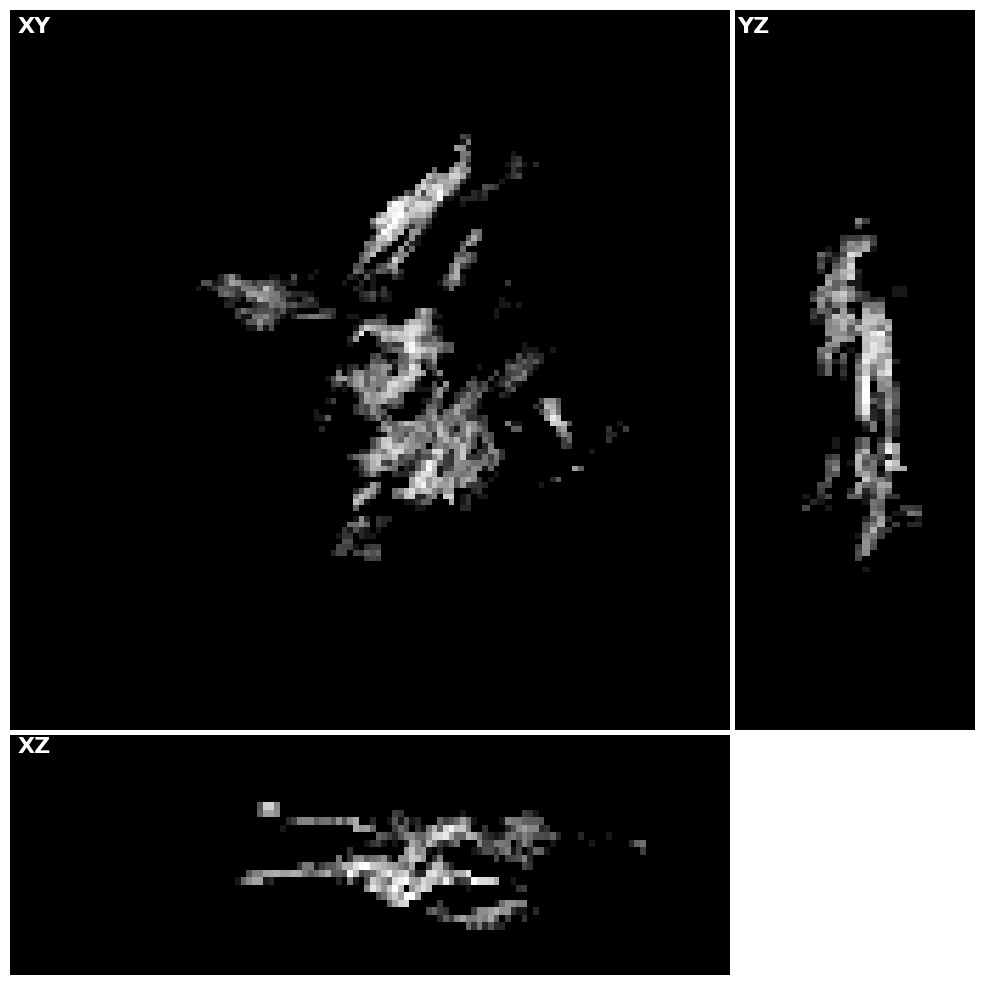

In [ ]:
img = np.load(
    Path("/Users/josephinelahmani/Desktop/nn_dis/data/fractals/fractal_74_13_funcs_img.npy")
)

#img = np.load(Path('/Users/josephinelahmani/Desktop/data/3d_synthetic/E_300.0_nu_0.45_nb_zones_2_im_00_seed_01_img.npy'))

volume = img[1] 
nz, ny, nx = volume.shape

iz, iy, ix = nz // 2, ny // 2, nx // 2

fig = plt.figure(figsize=(10, 10), layout="none")

gap = 0.005
main = 0.72
side = 0.24
left = bottom = 0.02

ax_xy = fig.add_axes([
    left, bottom + side + gap, main, main
])
ax_yz = fig.add_axes([
    left + main + gap, bottom + side + gap, side, main
])
ax_xz = fig.add_axes([
    left, bottom, main, side
])

ax_xy.imshow(volume[iz, :, :], cmap="gray", aspect="auto")
ax_yz.imshow(volume[:, :, ix].T, cmap="gray", aspect="auto")
ax_xz.imshow(volume[:, iy, :], cmap="gray", aspect="auto")

for ax, label in [(ax_xy, "XY"), (ax_yz, "YZ"), (ax_xz, "XZ")]:
    ax.set_axis_off()
    ax.text(
        0.01, 0.99,
        label,
        transform=ax.transAxes,
        color="white",
        fontsize=25,
        fontweight="bold",
        ha="left",
        va="top",
        #bbox=dict(facecolor="black", alpha=0.4, edgecolor="none", pad=3),
    )


output_path = Path(
    "/Users/josephinelahmani/Desktop/nn_dis/data/fractals/frac1_coupes.png"
)
fig.savefig(output_path, dpi=300, bbox_inches="tight", transparent=True, pad_inches=0)
plt.show()

In [79]:
img = np.load(Path('/Users/josephinelahmani/Desktop/data/3d_synthetic/E_300.0_nu_0.45_nb_zones_2_im_00_seed_01_img.npy'))
ugt_raw = np.load(Path('/Users/josephinelahmani/Desktop/data/3d_synthetic/E_500.0_nu_0.45_nb_zones_2_im_00_seed_05_ugt.npy'))
ugt_pixels = np.stack([ugt_raw[i, 0] for i in range(3)])  # / spacing[i] for i in range(3)])

# sy = 128 / ugt_pixels[1].shape[1]
# sx = 128 / ugt_pixels[2].shape[2]
# ugt_pixels[1] *= sy
# ugt_pixels[2] *= sx

ugt_pixels = ugt_pixels * (img[0] > 0.01)

nz, ny, nx = ugt_pixels.shape[1:]

step = 3

z, y, x = np.meshgrid(
    np.arange(0, nz, step),
    np.arange(0, ny, step),
    np.arange(0, nx, step),
    indexing="ij",
)
positions = np.stack([z, y, x], axis=-1).reshape(-1, 3)

displacements = (
    ugt_pixels[:, ::step, ::step, ::step]
    .transpose(1, 2, 3, 0)
    .reshape(-1, 3)
)

vectors = np.stack([positions, displacements], axis=1)

viewer = napari.Viewer(ndisplay=3)

img = viewer.add_image(img)
layer = viewer.add_vectors(
    vectors,
    name="ugt",
    ndim=3,
    vector_style="arrow",
    edge_color="yellow",
    edge_width=0.1,
    length=0.5,
    scale=(1.0, 1.0, 1.0),
)

layer.bounding_box.visible = True
layer.bounding_box.line_color = "white"

viewer.camera.angles = (40, 0, 115)
viewer.camera.zoom = 4

napari.run()

In [132]:
ugt = np.load(
    Path('/Users/josephinelahmani/Desktop/nn_dis/data/fractals/fractal_74_13_funcs_ugt.npy')
)

viewer = napari.Viewer()
img_ugt = viewer.add_image(
    ugt[2],
    name="Noise",
    interpolation3d="nearest",
    scale=(1.0, 1.0, 1.0),
    colormap="coolwarm",
)
img_ugt.bounding_box.visible = True
img_ugt.bounding_box.line_color = "white"
img_ugt.bounding_box.point_color = "white"
img_ugt.bounding_box.point_size = 1
img_ugt.bounding_box.opacity = 0.8
img_ugt.bounding_box.blending = "translucent"
img_ugt.colorbar.visible = True

viewer.dims.ndisplay = 3
viewer.camera.angles = (-40, 0, 110)
viewer.camera.zoom = 5

output_dir = Path("/Users/josephinelahmani/Desktop/nn_dis/data/fractals/")
output_path = output_dir / "rigid+grf.png"
viewer.screenshot(
    path=output_path,
    canvas_only=True,
    flash=False,
)
napari.run()

Context leak detected, CoreAnalytics returned false


## Augmentations

In [234]:
def get_transformed_img(
    img_path: Path,
    ugt_path,
    spatial_transform,
    intensity_transform=None,
    channel=None,
):
    device = "cpu"

    img_raw = np.load(img_path)
    ugt_raw = np.load(ugt_path)

    # Flow shape: (3, Z, H, W)
    u_gt = np.stack(
        [
            reshape_img(ugt_raw[0], 32),
            reshape_img(ugt_raw[1], 32),
            reshape_img(ugt_raw[2], 32),
        ]
    ).astype(np.float32)

    data = img_raw[:, channel] if channel is not None else img_raw
    img = np.clip(data / (data.max() + 1e-8), 0, 1)

    source = reshape_img(img[0], 32).astype(np.float32)
    target = reshape_img(img[1], 32).astype(np.float32)
    
    source = torch.from_numpy(source).to(device)
    target = torch.from_numpy(target).to(device)
    flow = torch.from_numpy(u_gt).to(device)

    image_stack = torch.stack([source, target], dim=0)  # (2, Z, H, W)

    original_img = image_stack.clone().cpu().numpy()
    original_flow = flow.clone().cpu().numpy()

    # ------------------------------------------------------------
    # 1. Apply spatial transforms to BOTH images and displacement field
    # ------------------------------------------------------------
    spatial_subject = tio.Subject(
        stack=tio.ScalarImage(tensor=image_stack),
        flow=tio.ScalarImage(tensor=flow),
    )

    spatial_subject = spatial_transform(spatial_subject)

    transformed_img = spatial_subject.stack.data.cpu().numpy().copy()
    transformed_flow = spatial_subject.flow.data.cpu().numpy().copy()

    # ------------------------------------------------------------
    # 2. Correct displacement-vector values after flip / affine
    # ------------------------------------------------------------
    total_linear = np.eye(3, dtype=np.float32)

    for applied_transform in spatial_subject.history:
        transform_name = applied_transform.__class__.__name__

        # RandomFlip becomes Flip in TorchIO history
        if transform_name == "Flip":
            axes = applied_transform.axes

            flip_linear = np.eye(3, dtype=np.float32)

            # LR direction / x component
            if 0 in axes or "LR" in axes:
                flip_linear[0, 0] = -1

            # Optional, for future AP flips
            if 1 in axes or "AP" in axes:
                flip_linear[1, 1] = -1

            # Optional, for future IS flips
            if 2 in axes or "IS" in axes:
                flip_linear[2, 2] = -1

            total_linear = flip_linear @ total_linear

        elif transform_name == "Affine":
            sitk_transform = applied_transform.get_affine_transform(
                spatial_subject.stack
            )

            p0 = np.asarray(
                sitk_transform.TransformPoint((0.0, 0.0, 0.0)),
                dtype=np.float32,
            )
            px = np.asarray(
                sitk_transform.TransformPoint((1.0, 0.0, 0.0)),
                dtype=np.float32,
            )
            py = np.asarray(
                sitk_transform.TransformPoint((0.0, 1.0, 0.0)),
                dtype=np.float32,
            )
            pz = np.asarray(
                sitk_transform.TransformPoint((0.0, 0.0, 1.0)),
                dtype=np.float32,
            )

            output_to_input_linear_lps = np.stack(
                [
                    px - p0,
                    py - p0,
                    pz - p0,
                ],
                axis=1,
            )

            input_to_output_linear_lps = np.linalg.inv(
                output_to_input_linear_lps
            )

            lps_to_ras = np.diag([-1, -1, 1]).astype(np.float32)

            affine_linear_ras = (
                lps_to_ras
                @ input_to_output_linear_lps
                @ lps_to_ras
            )

            total_linear = affine_linear_ras @ total_linear

    # Apply rotation / scale / flip to every flow vector
    transformed_flow = np.einsum(
        "ij,jzhw->izhw",
        total_linear,
        transformed_flow,
    )
    if intensity_transform is not None:
        intensity_subject = tio.Subject(
            stack=tio.ScalarImage(
                tensor=torch.from_numpy(transformed_img)
            )
        )

        intensity_subject = intensity_transform(intensity_subject)

        transformed_img = (
            intensity_subject.stack.data.cpu().numpy().copy()
        )
        
    mask_gt = transformed_img[0] > 0.001

    return (
        original_img,
        transformed_img,
        original_flow,
        transformed_flow,
        mask_gt
    )

In [235]:
path_img = Path('/Users/josephinelahmani/Desktop/nn_dis/data/fractals/fractal_85_12_funcs_img.npy') 
path_ugt = Path('/Users/josephinelahmani/Desktop/nn_dis/data/fractals/fractal_85_12_funcs_ugt.npy')

transforms = {
    "RandomFlip": tio.RandomFlip(axes=("LR",), flip_probability=1.0),
    "RandomAffine":tio.RandomAffine(scales=(0.9, 1.1), degrees=(-180, 180, 0, 0, 0, 0), translation=7),
    "RandomNoise": tio.RandomNoise(std=(0, 0.1)),
    "RandomBlur": tio.RandomBlur(std=(0, 1)), 
    "ComposeAll": tio.Compose(
        [
            tio.RandomFlip(axes=("LR",), flip_probability=1.0),
            tio.RandomFlip(axes=("AP",), flip_probability=0.3,),
            tio.RandomFlip(axes=("IS",),flip_probability=0.2,),
            tio.RandomAffine(scales=(0.9, 1.1), degrees=(-180, 180, 0, 0, 0, 0), translation=7),
            #tio.RandomNoise(std=(0, 0.01)),
            tio.RandomBlur(std=(0, 0.5)), 
        ]
    )
}

spatial_transform = tio.Compose(
    [
        tio.RandomFlip(axes=("LR",), flip_probability=1.0),
        tio.RandomFlip(axes=("AP",), flip_probability=0.3),
        tio.RandomFlip(axes=("IS",), flip_probability=0.2),
        tio.RandomAffine(
            scales=(0.9, 1.1),
            degrees=(-180, 180, 0, 0, 0, 0),
            translation=7,
        ),
    ]
)

intensity_transform = tio.Compose(
    [
        tio.RandomBlur(std=(0, 0.5)),
    ]
)

In [236]:
viewer_all = napari.Viewer()

img, transformed_img, u_gt, transformed_u_gt, mask_gt = get_transformed_img(path_img, path_ugt, spatial_transform, intensity_transform)

warped_img = warp(torch.from_numpy(img[1]).unsqueeze(0).unsqueeze(0), torch.from_numpy(u_gt).unsqueeze(0))
warped_img_transformed = warp(torch.from_numpy(transformed_img[1]).unsqueeze(0).unsqueeze(0), torch.from_numpy(transformed_u_gt).unsqueeze(0))

viewer_all.add_image(img,  scale=(4.0, 1.0, 1.0), interpolation3d='nearest')
viewer_all.add_image(transformed_img, scale=(4.0, 1.0, 1.0), interpolation3d='nearest')
viewer_all.add_image(warped_img, scale=(4.0, 1.0, 1.0), interpolation3d='nearest')
viewer_all.add_image(warped_img_transformed, scale=(4.0, 1.0, 1.0), interpolation3d='nearest')

viewer_all.add_image(mask_gt, scale=(4.0, 1.0, 1.0), interpolation3d='nearest')
napari.run()

## Masks

In [7]:
# mask = compute_mask(img)

# mask.shape

# plt.imshow(mask)

# Model

In [15]:
def warp_vxm(
    moving: torch.Tensor,
    displacement: torch.Tensor,
) -> torch.Tensor:
    shape = moving.shape[2:]
    ndim = len(shape)

    axes = [
        torch.arange(0, s, dtype=displacement.dtype, device=displacement.device)
        for s in shape
    ]

    meshgrid = torch.stack(torch.meshgrid(*axes, indexing="ij"), dim=0).contiguous()

    new_locs = meshgrid + displacement

    sizes = torch.tensor(
        shape, dtype=displacement.dtype, device=displacement.device
    )

    scales = 2.0 / (sizes - 1).clamp(min=1)
    broadcast_shape = (ndim,) + (1,) * len(shape)
    scales = scales.view(broadcast_shape)

    grid = new_locs * scales - 1.0

    grid = grid.flip(
        dims=(1,)
    )  # Convert from ij (z,y,x) to (x,y,z) convention for grid_sample
    grid = grid.permute(0, 2, 3, 4, 1)  # To have a (N, D, H, W, C) shape

    return F.grid_sample(
        moving, grid, mode = "bilinear", padding_mode="zeros", align_corners=True
    )
    
def add_flows_viewer(
    flow: np.ndarray,
    flow_name: str,
    ax: int,
    viewer: napari.Viewer,
    spacing: tuple[float, float, float],
) -> None:
    """
    Add a flow visualization on a given ax to a napari viewer.

    Args:
        flow (np.ndarray): The flow.
        flow_name (str): The name of the flow.
        ax (int): The ax index. Can only be 0, 1 or 2 in 3D.
        viewer (napari.Viewer): The existing viewer.
        spacing (tuple[float, float, float]): The spacing or scale of the image (z, y, x).

    Raises:
        ValueError: If ax is higher than the dimension.
    """
    if ax > flow.shape[0]:
        raise ValueError(f"ax can only be 0, 1 or 2 in 3D. Got {ax}")
    img = viewer.add_image(
        flow[ax, 0],
        name=f"{flow_name}, ax={ax}",
        scale=spacing,
        colormap="cividis",
        interpolation3d="nearest",
    )
    img.colorbar.visible = True


def get_viewer_flows(
    img: np.ndarray,
    flows: list[np.ndarray],
    flows_name: list[str],
    spacing: tuple[float, float, float],
    axes: list[int],
):
    """
    Create a napari viewer to observe an image and the different displacement
    fields on various axes (x, y and z).

    Args:
        img (np.ndarray): The image.
        flows (list[np.ndarray]): List of the displacement fields to display.
        flows_name (list[str]): Names of the displayed displacement fields.
        spacing (tuple[float, float, float]): Spacing or scale of the image (z, y, x).
        axes (list[int]): Axes to show the displacement fields on.
    """
    viewer = napari.Viewer()
    viewer.add_image(
        img,
        scale=spacing,
        interpolation3d="nearest",
    )

    for i, flow in enumerate(flows):
        for ax in axes:
            add_flows_viewer(
                flow, flows_name[i], ax, viewer, spacing
            )

    napari.run()

In [ ]:
def plot_loss(folder:str, loss_part:str, init_epoch:int=0):
    if loss_part == 'total':
        name = 'loss'
    else:
        name = f'loss_{loss_part}'

    train_logs = pd.read_csv(f'{folder}/logs_train.csv').iloc[init_epoch:]
    val_logs  = pd.read_csv(f'{folder}/logs_validation.csv').iloc[init_epoch:]

    epochs = range(init_epoch + 1, len(train_logs) + init_epoch + 1)
    
    plt.plot(epochs, train_logs[name], label='train loss', color='blue')
    plt.plot(epochs, val_logs[name], label='val loss', color='red')
    plt.title(f'{name}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.show()
    
    
def plot_losses(
    folder: str,
    loss_parts: list[str],
    weights: list[float],
    init_epoch: int = 0,
):
    train_logs = pd.read_csv(f"{folder}/logs_train.csv").iloc[init_epoch + 1:].reset_index(drop=True)
    val_logs = pd.read_csv(f"{folder}/logs_validation.csv").iloc[init_epoch:].reset_index(drop=True)

    n_epochs = min(len(train_logs), len(val_logs))
    train_logs = train_logs.iloc[:n_epochs]
    val_logs = val_logs.iloc[:n_epochs]

    epochs = range(init_epoch + 1, init_epoch + n_epochs + 1)

    n_losses = len(loss_parts)

    _, axes = plt.subplots(
        1,
        n_losses,
        figsize=(6 * n_losses, 5),
    )

    if n_losses == 1:
        axes = [axes]

    for i, loss_part in enumerate(loss_parts):
        name = "loss" if loss_part == "total" else f"loss_{loss_part}"

        if name == "loss":
            train_values = train_logs[name]
            val_values = val_logs[name]
            title = "Total loss"
        else:
            weight = weights[i - 1]
            
            train_values = weight * train_logs[name]
            val_values = weight * val_logs[name]
            title = f"{name} * {weight}"

        axes[i].plot(epochs, train_values, label="Train loss (next epoch)", color="blue")
        axes[i].plot(epochs, val_values, label="Validation loss", color="red")

        axes[i].set_title(title)
        axes[i].set_xlabel("Validation epoch")
        axes[i].set_ylabel("Loss")
        axes[i].legend()
        axes[i].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


def check_vxm(img_padded: np.ndarray, warped_image:np.ndarray, z_stack: int):
        
        diff_init = np.abs(img_padded[1, z_stack] - img_padded[0, z_stack])
        diff_warped = np.abs(warped_image[z_stack] - img_padded[0, z_stack])
        
        print('Average difference original image', np.mean(diff_init))
        print('Average difference warped image', np.mean(diff_warped))
        
        vmin_im, vmax_im = np.min(img_padded[0, z_stack]), np.max(img_padded[0, z_stack])
        
        vmin = np.min([np.min(diff_init), np.min(diff_warped)])
        vmax = np.max([np.max(diff_init), np.max(diff_warped)])
        
        fig, axes = plt.subplots(1, 5, figsize=(24, 6))
        
        im0 = axes[0].imshow(img_padded[0, z_stack], vmin=vmin_im, vmax=vmax_im)
        axes[0].set_title('I1')
        fig.colorbar(im0, ax=axes[0])
        im1 = axes[1].imshow(img_padded[1, z_stack], vmin=vmin_im, vmax=vmax_im)
        axes[1].set_title('I2')
        fig.colorbar(im1, ax=axes[1])
        im2 = axes[2].imshow(warped_image[z_stack], vmin=vmin_im, vmax=vmax_im)
        axes[2].set_title("I2(x+u)")
        fig.colorbar(im2, ax=axes[2])
        im3 = axes[3].imshow(diff_init, vmin=vmin, vmax=vmax)
        axes[3].set_title("I2 - I1 (absolute value)")
        fig.colorbar(im3, ax=axes[3])
        im4 = axes[4].imshow(diff_warped, vmin=vmin, vmax=vmax)
        axes[4].set_title("I2(x+u) - I1 (absolute value)")
        fig.colorbar(im4, ax=axes[4])
        plt.show()
        

def rmse_(pred, target):
    return np.sqrt(np.mean((pred-target)**2))

def compute_mse(pred, target, mask):
    diff_ = pred[:,0] - target
    diff = np.stack(
            [(diff_[i] ** 2) for i in range(diff_.shape[0])]
        )
    mse = (diff * mask).sum() / (3 * mask.sum() + 1e-8)
    return mse

# Test on one image

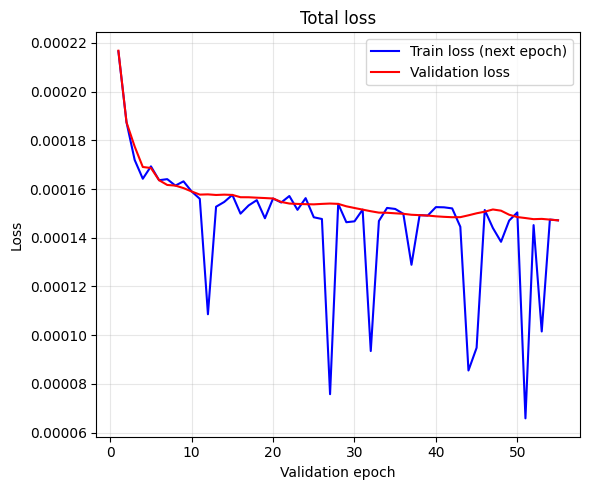

In [52]:
num_train = 2

results_folder_1 = f'/Users/josephinelahmani/helix_mount/nn_dis/results/train_{num_train}_test'

plot_losses(results_folder_1, ['total'], [], 0)

In [35]:
with open(
    "/Users/josephinelahmani/Desktop/nn_dis/configs/train_configs/train_config_2_bis.yaml", "r") as f:
    config = yaml.safe_load(f)

train_config = SimpleNamespace(**config["train_config"])

train_dataset = TractionDataset(
            Path(train_config.train_data),
            spatial_transforms=None,
            intensity_transforms=None,
            channel=train_config.channel,
            mask=train_config.mask,
            path_gt=Path(train_config.path_gt),
        )

val_dataset = TractionDataset(
            Path(train_config.val_data),
            spatial_transforms=None,
            intensity_transforms=None,
            channel=train_config.channel,
            mask=train_config.mask,
            path_gt=Path(train_config.path_gt),
        )

In [53]:
def masked_physical_mse(
    pred: torch.Tensor,
    target: torch.Tensor,
    mask: torch.Tensor,
    spacing: tuple[float, float, float] = (4.0, 1.0, 1.0),
    eps: float = 1e-8,
) -> torch.Tensor:

    if mask.ndim == 4:
        mask = mask.unsqueeze(1)  # (B, 1, D, H, W)

    mask = mask.to(device=pred.device, dtype=pred.dtype)

    error_z = (pred[:, 0] - target[:, 0]) * spacing[:, 0].view(-1, 1, 1, 1)
    error_y = (pred[:, 1] - target[:, 1]) * spacing[:, 1].view(-1, 1, 1, 1)
    error_x = (pred[:, 2] - target[:, 2]) * spacing[:, 2].view(-1, 1, 1, 1)

    squared_error = error_z.square() + error_y.square() + error_x.square()

    return (squared_error * mask).sum() / (3 * mask.sum() + 1e-8)
        
train_loader = DataLoader(
    train_dataset,
    batch_size=train_config.batch_size,
    num_workers=train_config.workers,
    shuffle=True,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=train_config.batch_size,
    num_workers=train_config.workers,
)

for idx, batch in enumerate(iter(train_loader)):
    ref = batch["ref"]
    moving= batch["moving"]
    mask_gt = batch["mask_gt"]
    u_gt = batch["u_gt"]
    spacing = batch["spacing"]

model = network.models.NetworkPairwiseAnisotropic(
    ndim=3,
    ref_channels=1,
    moving_channels=1,
    features=[16, 32, 32, 64, 64],
    flow_multiplier=10,
).to("cpu")

model.load_state_dict(
    torch.load(Path(results_folder_1) / "best.pt", map_location="cpu", weights_only=True)
)
model.eval()

with torch.no_grad():
    pred = model(ref, moving)

gt = u_gt
mask = mask_gt
masked_gt = np.transpose(gt, (1, 0, 2, 3, 4)) * mask
masked_pred = np.transpose(pred, (1, 0, 2, 3, 4)) * mask

print("pred:", pred.shape)
print("gt:", gt.shape)
print("mask:", mask.shape)
print("spacing:", spacing)

print("pred min/max:", masked_pred.min().item(), masked_pred.max().item())
print("gt min/max:", masked_gt.min().item(), masked_gt.max().item())
print("loss", masked_physical_mse(pred, gt, mask_gt, spacing))

/opt/anaconda3/envs/voxelmorph/lib/python3.12/site-packages/torch/utils/data/dataloader.py:431: UserWarning: Got pickle error when attempting to start a worker Process. This might be because the worker Process arguments are not picklable. Python 3.14+ changed the multiprocessing start method in non-Mac POSIX platforms to 'forkserver', which requires the worker Process arguments to be picklable. You can also try multiprocessing.set_start_method('fork').
  return _MultiProcessingDataLoaderIter(self)


PicklingError: Can't pickle <class 'scripts.dataset.TractionDataset'>: it's not the same object as scripts.dataset.TractionDataset

In [54]:
path_img_test = Path('/Users/josephinelahmani/helix_mount/data/fractals/test_1_im/train/fractal_85_9_funcs_img.npy')
path_ugt_test = Path('/Users/josephinelahmani/helix_mount/data/fractals/test_1_im/all_data/fractal_85_9_funcs_ugt.npy')

img_test, spacing_test, dis_vxm_test, warped_vxm_test = register(img_path=path_img_test, folder_path=results_folder_1, model_type='aniso', default_spacing=[4.0, 1.0, 1.0], features=[16, 32, 32, 64, 64])
dis_vxm_test = np.transpose(dis_vxm_test, (1, 0, 2, 3, 4))

ugt_test = np.load(path_ugt_test)

u_gt_test = np.stack(
    [
        reshape_img(ugt_test[0], 32),
        reshape_img(ugt_test[1], 32),
        reshape_img(ugt_test[2], 32),
    ]
)

mask_test = img_test[0] > 0.0005

dis_vxm_masked_test = np.stack(
        [dis_vxm_test[i] * mask_test for i in range(dis_vxm_test.shape[0])]
    )
u_gt_masked_test = np.stack(
        [u_gt_test[i] * mask_test for i in range(u_gt_test.shape[0])]
    )

warped_ugt = warp_vxm(torch.from_numpy(img_test).float()[1:2].unsqueeze(0), torch.from_numpy(u_gt_test).float().unsqueeze(0))

diff_im_test = img_test[1] - img_test[0]
diff_w_test = warped_vxm_test - img_test[0]
diff_u_vxm_test = np.sum(((dis_vxm_test[:,0] - u_gt_test) ** 2) * mask_test) #dis_vxm_masked_test - u_gt_masked_test[:, np.newaxis]
diff_w_vxm_ugt = warped_vxm_test - warped_ugt.detach().numpy()

diff_u_vxm_test_ = dis_vxm_test[:,0] - u_gt_test
# diff_u_vxm_test = np.stack(
#         [(diff_u_vxm_test_[i] ** 2) * spacing_test[i] for i in range(diff_u_vxm_test_.shape[0])]
#     )
diff_u_vxm_test = np.stack(
        [(diff_u_vxm_test_[i] ** 2) for i in range(diff_u_vxm_test_.shape[0])]
    )
diff_u = (diff_u_vxm_test * mask_test).sum() / (3 * mask_test.sum() + 1e-8)
    
print('Results')
print('diff_u_vxm_test', diff_u)

Results
diff_u_vxm_test 71.24041649499318


In [27]:
get_viewer_flows(img_test, flows=[u_gt_test[:, np.newaxis], dis_vxm_test], flows_name=["UGT", "VXM"], spacing=spacing_test, axes=[0, 1, 2])

In [51]:
get_viewer_flows(img_test, flows=[u_gt_masked_test[:, np.newaxis], dis_vxm_masked_test], flows_name=["UGT", "VXM"], spacing=spacing_test, axes=[0, 1, 2])

In [47]:
viewer = napari.Viewer()
viewer.add_image(img_test, scale=spacing_test, name="I1")
viewer.add_image(warped_vxm_test, scale=spacing_test, name="warped I2")
viewer.add_image(warped_ugt, scale=spacing_test, name="warped I2 ugt")
napari.run()

# Test rigid

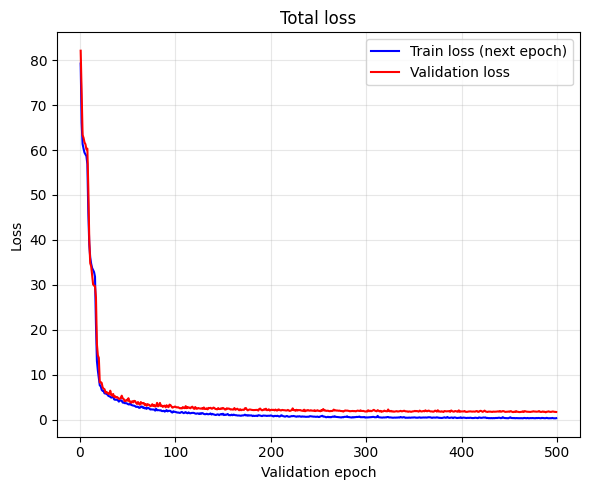

In [13]:
num_train = 14

results_folder_rigid = f'/Users/josephinelahmani/helix_mount/nn_dis/results/train_{num_train}'

with open(
    f"/Users/josephinelahmani/Desktop/nn_dis/configs/train_configs/train_config_{num_train}.yaml", "r") as f:
    config = yaml.safe_load(f)

train_params = SimpleNamespace(**config["train_config"])

plot_losses(results_folder_rigid, ['total'], [train_params.gt_param], 0)

In [485]:
# path_img_rigid = Path('/Users/josephinelahmani/helix_mount/data/fractals/rigid/test/fractal_12_9_funcs_img.npy')
# path_ugt_rigid = Path('/Users/josephinelahmani/helix_mount/data/fractals/rigid/all_data/fractal_12_9_funcs_ugt.npy')
# path_img_rigid = Path('/Users/josephinelahmani/helix_mount/data/fractals/rigid/train/fractal_0_10_funcs_img.npy')
# path_ugt_rigid = Path('/Users/josephinelahmani/helix_mount/data/fractals/rigid/all_data/fractal_0_10_funcs_ugt.npy')
path_img_rigid = Path('/Users/josephinelahmani/helix_mount/data/fractals/rigid/test/fractal_1_10_funcs_img.npy')
path_ugt_rigid = Path('/Users/josephinelahmani/helix_mount/data/fractals/rigid/all_data/fractal_1_10_funcs_ugt.npy')

img_rigid, spacing_rigid, dis_vxm_rigid, warped_vxm_rigid = register(img_path=path_img_rigid, folder_path=results_folder_rigid, model_type='aniso', default_spacing=[4.0, 1.0, 1.0])
dis_vxm_rigid = np.transpose(dis_vxm_rigid, (1, 0, 2, 3, 4))

ugt_rigid = np.load(path_ugt_rigid)

u_gt_rigid = np.stack(
    [
        reshape_img(ugt_rigid[0], 32),
        reshape_img(ugt_rigid[1], 32),
        reshape_img(ugt_rigid[2], 32),
    ]
)

mask_rigid = img_rigid[0] > 0.001

dis_vxm_masked_rigid = np.stack(
        [dis_vxm_rigid[i] * mask_rigid for i in range(dis_vxm_rigid.shape[0])]
    )
u_gt_masked_rigid = np.stack(
        [u_gt_rigid[i] * mask_rigid for i in range(u_gt_rigid.shape[0])]
    )

diff_u_rigid = compute_mse(dis_vxm_rigid, u_gt_rigid, mask_rigid)
print('Results')
print('diff_u_vxm_rigid', diff_u_rigid)

Results
diff_u_vxm_rigid 1.0184597854251718


In [8]:
viewer = napari.Viewer()
viewer.add_image(img_rigid, scale=spacing_rigid, name="I1")
viewer.add_image(warped_vxm_rigid, scale=spacing_rigid, name="warped I2")
viewer.add_image(warped_ugt, scale=spacing_rigid, name="warped I2 UGT")
napari.run()

In [486]:
get_viewer_flows(img_rigid, flows=[u_gt_masked_rigid[:, np.newaxis], dis_vxm_masked_rigid], flows_name=["UGT", "VXM"], spacing=spacing_rigid, axes=[0, 1, 2])

# Test rigid + GRF

In [ ]:
from pipeline_methods import compute_of_strain_traction
folder_synth_img = Path('/Users/josephinelahmani/Desktop/data/dataset_3d')
save_path = Path("/Users/josephinelahmani/Desktop/nn_dis/data/computed_flows")
results_folders = {#'train 1': '/Users/josephinelahmani/Desktop/nn_dis/results/train_1', 
                    'train 2': '/Users/josephinelahmani/Desktop/nn_dis/results/train_2', 
                    'train 3': '/Users/josephinelahmani/Desktop/nn_dis/results/train_3',
                    # 'train 4': '/Users/josephinelahmani/Desktop/nn_dis/results/train_4',
                    # 'train 5': '/Users/josephinelahmani/Desktop/nn_dis/results/train_5',
                    # 'train 6': '/Users/josephinelahmani/Desktop/nn_dis/results/train_6',
                    # 'train 7': '/Users/josephinelahmani/Desktop/nn_dis/results/train_7',
                    # 'train 8': '/Users/josephinelahmani/Desktop/nn_dis/results/train_8',
                    # 'train 9': '/Users/josephinelahmani/Desktop/nn_dis/results/train_9',
                    # 'train 10': '/Users/josephinelahmani/Desktop/nn_dis/results/train_10',
                    # 'train 11': '/Users/josephinelahmani/Desktop/nn_dis/results/train_11',
                    'train 14': '/Users/josephinelahmani/helix_mount/nn_dis/results/train_14',
                    'train 15': '/Users/josephinelahmani/helix_mount/nn_dis/results/train_15', }

results = compute_of_strain_traction(
    folder_img_ugt=folder_synth_img,
    of_functions=['fista', 'hs', 'tvl1', 'ilk'],
    results_folders=results_folders,
    path_of_results=save_path,
)

In [ ]:
print(f'{results['mean_rmse_disp']['fista']=:.4f}')
print(f'{results['mean_rmse_disp']['hs']=:.4f}')
print(f'{results['mean_rmse_disp']['ilk']=:.4f}')
print(f'{results['mean_rmse_disp']['tvl1']=:.4f}')
print(f'{results['mean_rmse_disp']['train 14']=:.4f}')
print(f'{results['mean_rmse_disp']['train 15']=:.4f}')
# print(f'{results['mean_rmse_disp']['train 1']=:.4f}')
# print(f'{results['mean_rmse_disp']['train 2']=:.4f}')
print(f'{results['mean_rmse_disp']['train 3']=:.4f}')
print(f'{results['mean_rmse_disp']['train 4']=:.4f}')
# print(f'{results['mean_rmse_disp']['train 5']=:.4f}')
# print(f'{results['mean_rmse_disp']['train 6']=:.4f}')
# print(f'{results['mean_rmse_disp']['train 7']=:.4f}')
# print(f'{results['mean_rmse_disp']['train 8']=:.4f}')
# print(f'{results['mean_rmse_disp']['train 9']=:.4f}')
# print(f'{results['mean_rmse_disp']['train 10']=:.4f}')
# print(f'{results['mean_rmse_disp']['train 11']=:.4f}')
# print(f'{results['mean_rmse_disp']['train 12']=:.4f}')
# print(f'{results['mean_rmse_disp']['train 13']=:.4f}')

In [ ]:
def save_scatter_comparison(
    results: dict,
    results_dir: str | Path,
    methods: list[tuple[str, str]],
    strain: bool = False,
):
    fig, axes = plt.subplots(
        1,
        2 if strain else 1,
        figsize=(12, 6) if strain else (6, 3), 
        squeeze=False
    )
    axes = axes[0]

    colors = plt.get_cmap("tab10")
    markers = ["o", "s", "^", "D", "v", "P", "X"]

    quantities = [
        ("mean_rmse_disp", "Mean displacement NRMSE"),
    ]
    if strain:
        quantities.append(
            ("mean_rmse_strain", "Mean strain NRMSE")
        )

    for _, (ax, (result_key, ylabel)) in enumerate(
        zip(axes, quantities)
    ):
        for i, (name, method_key) in enumerate(methods):
            x = results["mean_runtime"][method_key]
            y = results[result_key][method_key]

            ax.scatter(
                x,
                y,
                color=colors(i % 10),
                marker=markers[i % len(markers)],
                s=50,
                zorder=3,
            )

            ax.annotate(
                name,
                (x, y),
                xytext=(5, 5),
                textcoords="offset points",
                fontsize=13,
                fontweight="bold",
            )

        ax.set_xlabel("Mean runtime (s)")
        ax.set_ylabel(ylabel)
        ax.grid(True, alpha=0.3)
        ax.margins(x=0.2, y=0.2)

    fig.tight_layout()

    fig.savefig(
        results_dir / "scatter_nrmse_mean.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.close(fig)

In [78]:
save_scatter_comparison(
    results,
    Path('/Users/josephinelahmani/Desktop/nn_dis/results/plots'),
    methods=[
        ("Proposed", "train 14"),
        ("HS", "hs"),
        ("Hessian HS", "fista"),
        ("TV-L1", "tvl1"),
        ("ILK", "ilk"),
    ],
    strain=True
)

In [81]:
img, spacing, mask = results[4]['image'], results[4]['spacing'], results[4]['mask']

ugt = results[4]['flows']['gt']

# u_tvl4 = results[4]['flows']['tvl4']* mask
# u_ilk = results[4]['flows']['ilk']* mask
u_hs = results[4]['flows']['hs']* mask
u_model = results[4]['flows']['train 14'] * mask
u_fista = results[4]['flows']['fista'] * mask

get_viewer_flows(img, flows=[ugt, u_model, u_fista], flows_name=["GT", "Model", "FISTA"], spacing=spacing, axes=[0, 1, 2])

In [82]:
print('FISTA')
print(f'{results['mean_rmse_disp']['fista']=:.4f}')
print(f'{results['mean_rmse_strain']['fista']=:.4f}')
print(f'{results['mean_rmse_def']['fista']=:.4f}')
print(f'{results['mean_rmse_stress']['fista']=:.4f}')
print(f'{results['mean_rmse_traction']['fista']=:.4f}')
print(f'{results['mean_runtime']['fista']=:.4f}')

print('\nHS')
print(f'{results['mean_rmse_disp']['hs']=:.4f}')
print(f'{results['mean_rmse_strain']['hs']=:.4f}')
print(f'{results['mean_rmse_def']['hs']=:.4f}')
print(f'{results['mean_rmse_stress']['hs']=:.4f}')
print(f'{results['mean_rmse_traction']['hs']=:.4f}')
print(f'{results['mean_runtime']['hs']=:.4f}')

print('\nILK')
print(f'{results['mean_rmse_disp']['ilk']=:.4f}')
print(f'{results['mean_rmse_strain']['ilk']=:.4f}')
print(f'{results['mean_rmse_def']['ilk']=:.4f}')
print(f'{results['mean_rmse_stress']['ilk']=:.4f}')
print(f'{results['mean_rmse_traction']['ilk']=:.4f}')
print(f'{results['mean_runtime']['ilk']=:.4f}')

print('\nTVL1')
print(f'{results['mean_rmse_disp']['tvl1']=:.4f}')
print(f'{results['mean_rmse_strain']['tvl1']=:.4f}')
print(f'{results['mean_rmse_def']['tvl1']=:.4f}')
print(f'{results['mean_rmse_stress']['tvl1']=:.4f}')
print(f'{results['mean_rmse_traction']['tvl1']=:.4f}')
print(f'{results['mean_runtime']['tvl1']=:.4f}')

FISTA
results['mean_rmse_disp']['fista']=0.3134
results['mean_rmse_strain']['fista']=0.7347
results['mean_rmse_def']['fista']=0.4563
results['mean_rmse_stress']['fista']=1.8568
results['mean_rmse_traction']['fista']=1.5923
results['mean_runtime']['fista']=388.5638

HS
results['mean_rmse_disp']['hs']=0.3893
results['mean_rmse_strain']['hs']=1.0674
results['mean_rmse_def']['hs']=0.7100
results['mean_rmse_stress']['hs']=3.2516
results['mean_rmse_traction']['hs']=2.2681
results['mean_runtime']['hs']=76.2364

ILK
results['mean_rmse_disp']['ilk']=0.8117
results['mean_rmse_strain']['ilk']=1.4257
results['mean_rmse_def']['ilk']=0.6394
results['mean_rmse_stress']['ilk']=6.4907
results['mean_rmse_traction']['ilk']=6.4442
results['mean_runtime']['ilk']=3.0255

TVL1
results['mean_rmse_disp']['tvl1']=0.8193
results['mean_rmse_strain']['tvl1']=1.0860
results['mean_rmse_def']['tvl1']=0.7714
results['mean_rmse_stress']['tvl1']=2.8119
results['mean_rmse_traction']['tvl1']=2.7964
results['mean_runtime']

In [83]:
print('Model 14')
print(f'{results['mean_rmse_disp']['train 14']=:.4f}')
print(f'{results['mean_rmse_strain']['train 14']=:.4f}')
print(f'{results['mean_rmse_def']['train 14']=:.4f}')
print(f'{results['mean_rmse_stress']['train 14']=:.4f}')
print(f'{results['mean_rmse_traction']['train 14']=:.4f}')
print(f'{results['mean_runtime']['train 14']=:.4f}')

# print('Model 1')
# print(f'{results['mean_rmse_disp']['train 1']=:.4f}')
# print(f'{results['mean_rmse_strain']['train 1']=:.4f}')
# print(f'{results['mean_rmse_def']['train 1']=:.4f}')
# print(f'{results['mean_rmse_stress']['train 1']=:.4f}')
# print(f'{results['mean_rmse_traction']['train 1']=:.4f}')
# print(f'{results['mean_runtime']['train 1']=:.4f}')

Model 14
results['mean_rmse_disp']['train 14']=0.3996
results['mean_rmse_strain']['train 14']=0.9284
results['mean_rmse_def']['train 14']=0.7234
results['mean_rmse_stress']['train 14']=1.6782
results['mean_rmse_traction']['train 14']=1.4660
results['mean_runtime']['train 14']=1.5006


In [85]:
img, spacing, mask = results[0]['image'], results[0]['spacing'], results[0]['mask']

traction_gt = results[0]['traction']['gt']

traction_model = results[0]['traction']['train 14'] * mask
traction_fista = results[0]['traction']['fista'] * mask
traction_hs = results[0]['traction']['hs'] * mask

get_viewer_flows(img, flows=[traction_gt[:, np.newaxis], traction_model[:, np.newaxis], traction_fista[:, np.newaxis]], flows_name=["GT", "Model", "FISTA"], spacing=spacing, axes=[0, 1, 2])

In [18]:
img, spacing, mask = results[4]['image'], results[4]['spacing'], results[4]['mask']

def_gt = results[4]['deformation']['gt']

# u_tvl1 = results[1]['flows']['tvl1']* mask
# u_ilk = results[1]['flows']['ilk']* mask
# u_hs = results[1]['flows']['hs']* mask
def_model = results[4]['deformation']['train 13'] * mask
def_fista = results[4]['deformation']['fista'] * mask
def_hs = results[4]['deformation']['hs'] * mask

viewer_def = napari.Viewer()
img_gt = viewer_def.add_image(def_gt, scale=spacing, colormap="inferno")
img_gt.colorbar.visible = True
img_fista = viewer_def.add_image(def_fista, scale=spacing, colormap="inferno")
img_fista.colorbar.visible = True
img_hs = viewer_def.add_image(def_hs, scale=spacing, colormap="inferno")
img_hs.colorbar.visible = True
img_model = viewer_def.add_image(def_model, scale=spacing, colormap="inferno")
img_model.colorbar.visible = True
napari.run()

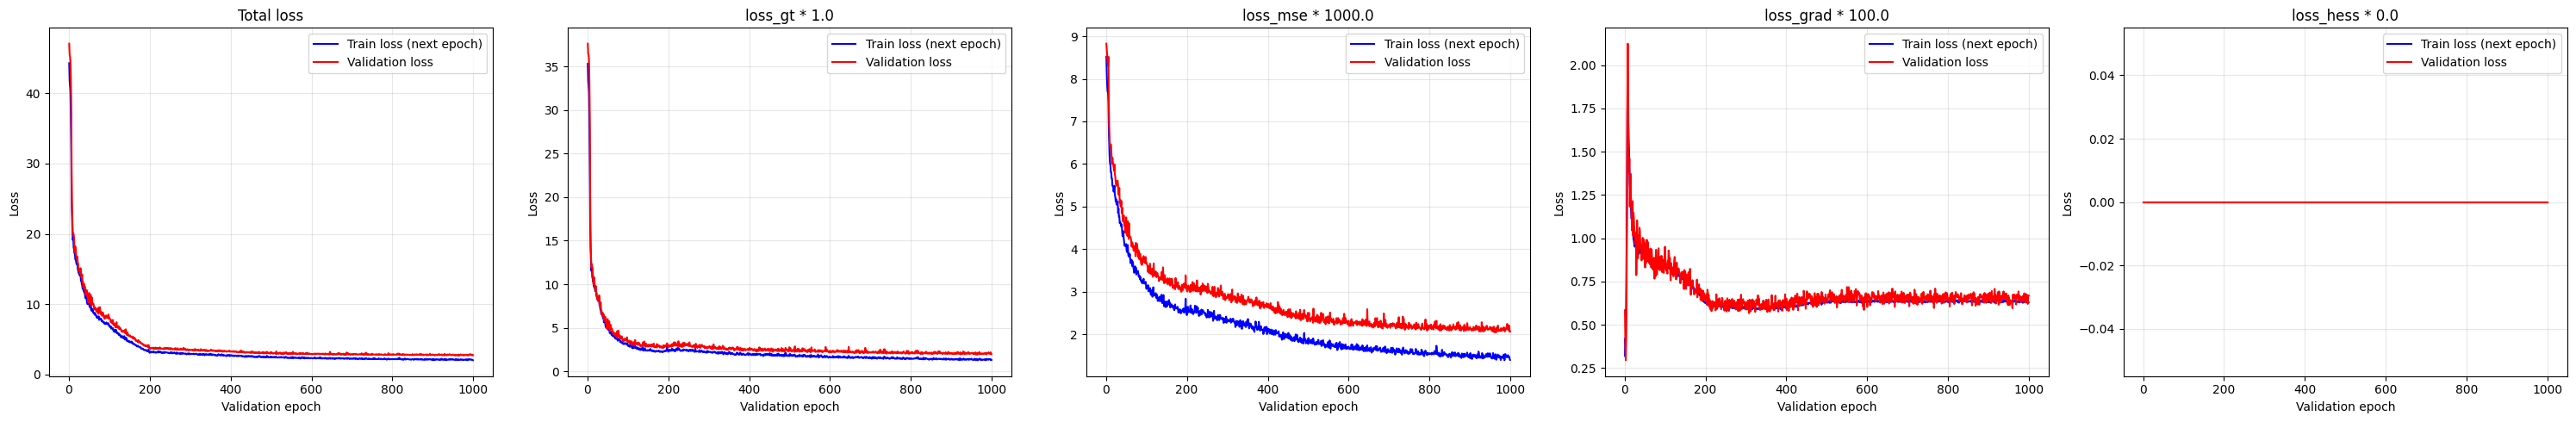

In [9]:
num_train = 11

results_folder_grf_sup_no_sup = f'/Users/josephinelahmani/helix_mount/nn_dis/results/train_{num_train}'

with open(
    f"/Users/josephinelahmani/Desktop/nn_dis/configs/train_configs/train_config_{num_train}.yaml", "r") as f:
    config = yaml.safe_load(f)

train_params = SimpleNamespace(**config["train_config"])

plot_losses(results_folder_grf_sup_no_sup, ['total', 'gt', 'mse', 'grad', 'hess'], [train_params.gt_param, train_params.warp_param, train_params.alpha_param, train_params.beta_param], 0)

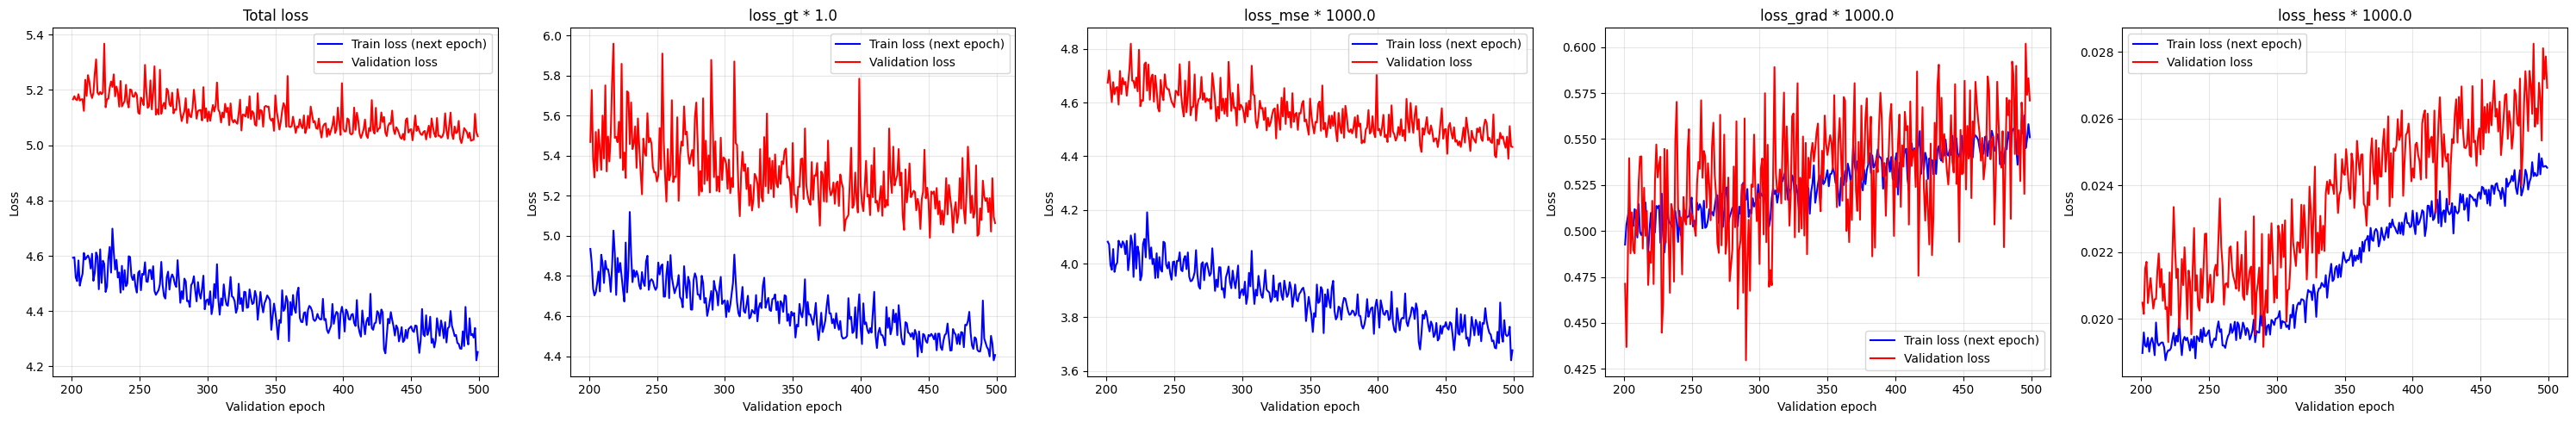

In [9]:
num_train = 14

results_folder_grf_sup_no_sup_50 = f'/Users/josephinelahmani/helix_mount/nn_dis/results/train_{num_train}_bis'

with open(
    f"/Users/josephinelahmani/Desktop/nn_dis/configs/train_configs/train_config_{num_train}_bis.yaml", "r") as f:
    config = yaml.safe_load(f)

train_params = SimpleNamespace(**config["train_config"])

plot_losses(results_folder_grf_sup_no_sup_50, ['total', 'gt', 'mse', 'grad', 'hess'], [train_params.gt_param, train_params.warp_param, train_params.alpha_param, train_params.beta_param], 200)

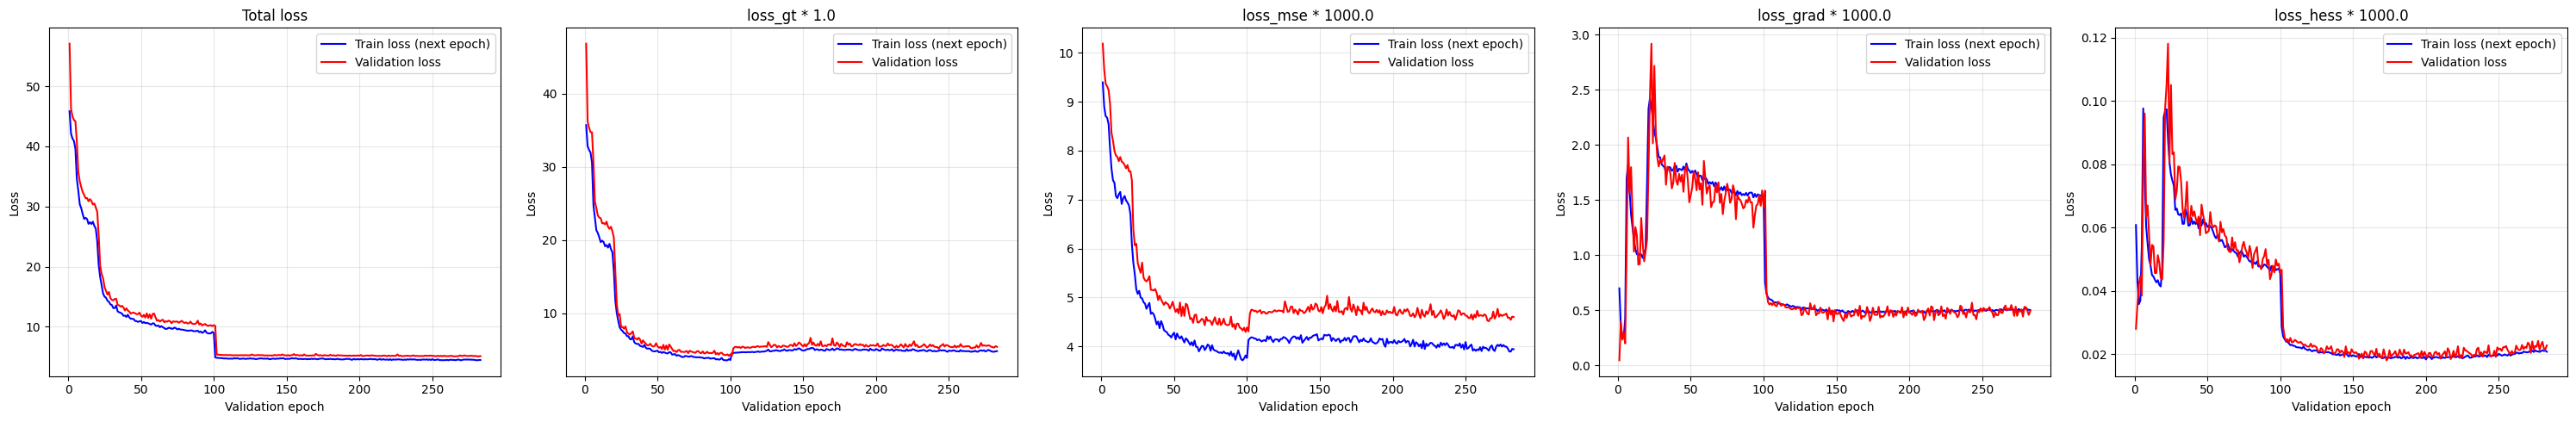

In [133]:
num_train = 14

results_folder_grf_sup_no_sup_1 = f'/Users/josephinelahmani/helix_mount/nn_dis/results/train_{num_train}_ter'

with open(
    f"/Users/josephinelahmani/Desktop/nn_dis/configs/train_configs/train_config_{num_train}_ter.yaml", "r") as f:
    config = yaml.safe_load(f)

train_params = SimpleNamespace(**config["train_config"])

plot_losses(results_folder_grf_sup_no_sup_1, ['total', 'gt', 'mse', 'grad', 'hess'], [train_params.gt_param, train_params.warp_param, train_params.alpha_param, train_params.beta_param], 0)

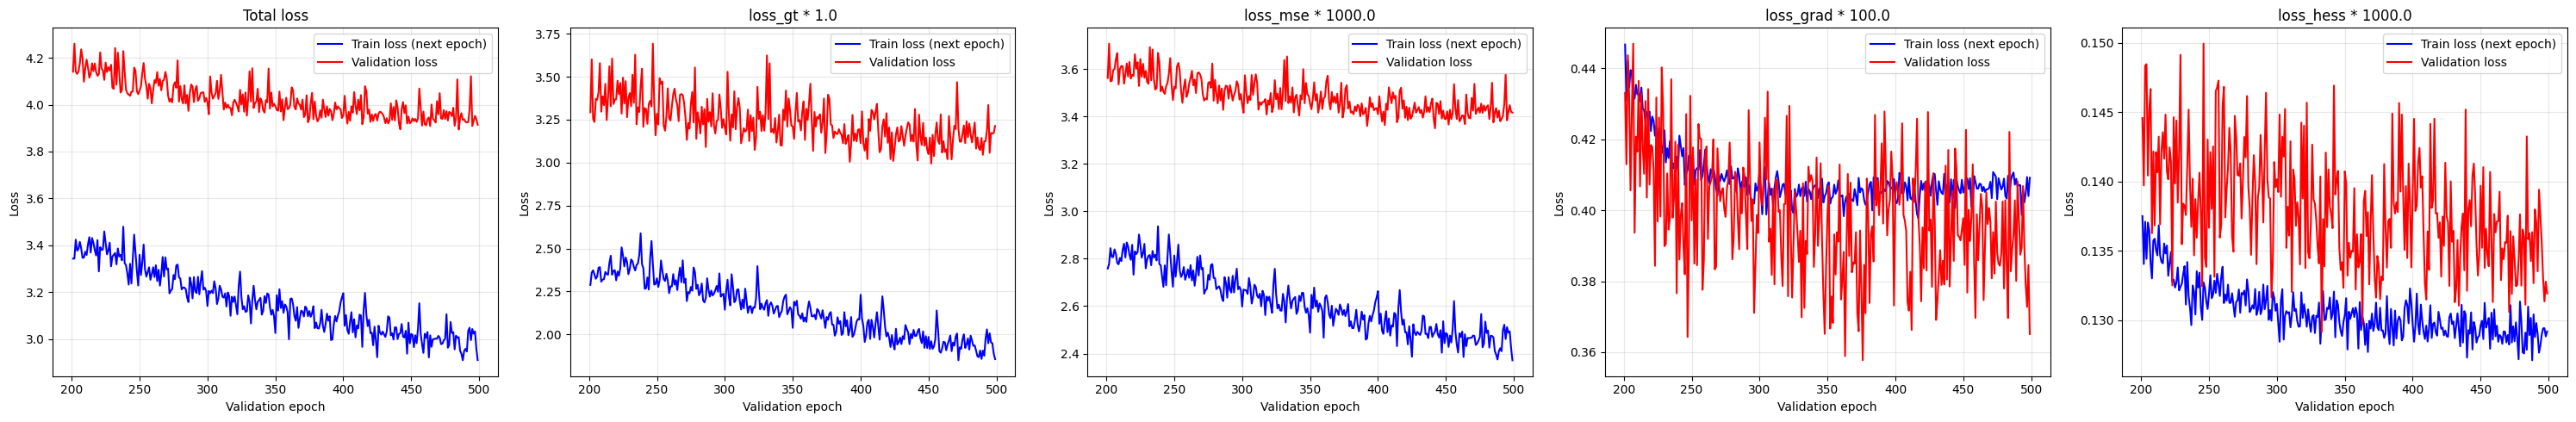

In [59]:
num_train = 14

results_folder_grf_sup_no_sup_100_weakergrad = f'/Users/josephinelahmani/helix_mount/nn_dis/results/train_{num_train}_4'

with open(
    f"/Users/josephinelahmani/Desktop/nn_dis/configs/train_configs/train_config_{num_train}_4.yaml", "r") as f:
    config = yaml.safe_load(f)

train_params = SimpleNamespace(**config["train_config"])

plot_losses(results_folder_grf_sup_no_sup_100_weakergrad, ['total', 'gt', 'mse', 'grad', 'hess'], [train_params.gt_param, train_params.warp_param, train_params.alpha_param, train_params.beta_param], 200)

In [8]:
def get_img_dis_model(img_path, folder_path, model_type='aniso', default_spacing=[1.0, 0.13, 0.13]):
    img, spacing, dis_model, warped_model = register(img_path=img_path, folder_path=folder_path, model_type=model_type, default_spacing=default_spacing)
    dis_model = np.transpose(dis_model, (1, 0, 2, 3, 4))
    mask = img[0] > 0.0001
    dis_model_masked = np.stack(
            [dis_model[i] * mask for i in range(dis_model.shape[0])]
        )
    
    return img, spacing, mask, dis_model, warped_model, dis_model_masked

In [15]:
path_img = Path('/Users/josephinelahmani/helix_mount/data/fractals/rigid_gaussian_new/test/fractal_56_15_funcs_img.npy')
path_ugt = Path('/Users/josephinelahmani/helix_mount/data/fractals/rigid_gaussian_new/all_data/fractal_56_15_funcs_ugt.npy')

results_folder_grf_sup_no_sup = '/Users/josephinelahmani/helix_mount/nn_dis/results/train_14_4'

# img, spacing, mask, dis_model_grf, warped_model_grf, dis_model_masked_grf = get_img_dis_model(path_img, results_folder_grf, default_spacing=(4.0, 1.0, 1.0))
# _, _, _, dis_model_grf_grad, warped_model_grf_grad, dis_model_masked_grf_grad = get_img_dis_model(path_img, results_folder_grf_grad, default_spacing=(4.0, 1.0, 1.0))
# _, _, _, dis_model_grf_mse, warped_model_grf_mse, dis_model_masked_grf_mse = get_img_dis_model(path_img, results_folder_grf_mse, default_spacing=(4.0, 1.0, 1.0))
# _, _, _, dis_model_grf_hess, warped_model_grf_hess, dis_model_masked_grf_hess = get_img_dis_model(path_img, results_folder_grf_hess, default_spacing=(4.0, 1.0, 1.0))
# _, _, _, dis_model_grf_mse_grad, warped_model_grf_mse_grad, dis_model_masked_grf_mse_grad = get_img_dis_model(path_img, results_folder_grf_mse_grad, default_spacing=(4.0, 1.0, 1.0))
# _, _, _, dis_model_grf_mse_grad_hess, warped_model_grf_mse_grad_hess, dis_model_masked_grf_mse_grad_hess = get_img_dis_model(path_img, results_folder_grf_mse_grad_hess, default_spacing=(4.0, 1.0, 1.0))
# _, _, _, dis_model_grf_no_sup, warped_model_grf_no_sup, dis_model_masked_grf_no_sup = get_img_dis_model(path_img, results_folder_grf_no_sup, default_spacing=(4.0, 1.0, 1.0))
img, spacing, mask, dis_model_grf_sup_no_sup, warped_model_grf_sup_no_sup, dis_model_masked_grf_sup_no_sup = get_img_dis_model(path_img, results_folder_grf_sup_no_sup, default_spacing=(4.0, 1.0, 1.0))


ugt_test = np.load(path_ugt)

u_gt_test = np.stack(
    [
        reshape_img(ugt_test[0], 32),
        reshape_img(ugt_test[1], 32),
        reshape_img(ugt_test[2], 32),
    ]
)

u_gt_masked_test = np.stack(
        [u_gt_test[i] * mask for i in range(u_gt_test.shape[0])]
    )

# diff_u_grf = compute_mse(dis_model_grf, u_gt_test, mask)
# diff_u_grf_grad = compute_mse(dis_model_grf_grad, u_gt_test, mask)
# diff_u_grf_mse = compute_mse(dis_model_grf_mse, u_gt_test, mask)
# diff_u_grf_hess = compute_mse(dis_model_grf_hess, u_gt_test, mask)
# diff_u_grf_mse_grad = compute_mse(dis_model_grf_mse_grad, u_gt_test, mask)
# diff_u_grf_mse_grad_hess = compute_mse(dis_model_grf_mse_grad_hess, u_gt_test, mask)
# diff_u_grf_no_sup = compute_mse(dis_model_grf_no_sup, u_gt_test, mask)
diff_u_grf_sup_no_sup = compute_mse(dis_model_grf_sup_no_sup, u_gt_test, mask)

print('Results')
# print('diff_u_grf', diff_u_grf)
# print('diff_u_grf_grad', diff_u_grf_grad)
# print('diff_u_grf_mse', diff_u_grf_mse)
# print('diff_u_grf_hess', diff_u_grf_hess)
# print('diff_u_grf_mse_grad', diff_u_grf_mse_grad)
# print('diff_u_mse_grad_hess', diff_u_grf_mse_grad_hess)
# print('diff_u_no_sup', diff_u_grf_no_sup)
print('diff_u_sup_no_sup', diff_u_grf_sup_no_sup)

Results
diff_u_sup_no_sup 1.4634467624781569


In [16]:
get_viewer_flows(img, flows=[u_gt_masked_test[:, np.newaxis], dis_model_masked_grf_sup_no_sup], flows_name=["UGT", "VXM"], spacing=spacing, axes=[0, 1, 2])

# Test data

## Microscopy

In [6]:
results_folder = '/Users/josephinelahmani/Desktop/nn_dis/results/train_14'

In [91]:
import time

In [7]:
crop = [(0, 2), (10,42), (300,750), (150,500)] # None
path_img_s = Path('/Users/josephinelahmani/Desktop/data/3D_img_sudheer/zstack_time_1_MMStack_Pos0.ome-1.tif')
channel = 2 # None
default_spacing = None #[1.0, 0.13, 0.13]

img_s, spacing_s, h_model_s, warped_vxm_s = register(img_path=path_img_s, folder_path=results_folder, model_type='aniso', channel=channel, default_spacing=default_spacing, crop=crop)
h_model_s = np.transpose(h_model_s, (1, 0, 2, 3, 4))

save_path = Path("/Users/josephinelahmani/Desktop/nn_dis/data/computed_flows")

h_fista_s = np.load(save_path / "flow_fista_img_sudheer.npy")
h_fista_s = np.stack([h_fista_s[i] / spacing_s[i] for i in range(h_fista_s.shape[0])])
h_hs_s = np.load(save_path / "flow_hs_img_sudheer.npy")

Attempted file (/Users/josephinelahmani/Desktop/data/3D_img_sudheer/zstack_time_1_MMStack_Pos0.ome-1.tif) load with reader: <class 'bioio_ome_tiff.reader.Reader'> failed with error: bioio-ome-tiff does not support the image: '/Users/josephinelahmani/Desktop/data/3D_img_sudheer/zstack_time_1_MMStack_Pos0.ome-1.tif'. Failed to parse XML for the provided file. Error: not well-formed (invalid token): line 1, column 6


In [8]:
E = 700
nu = 0.45
lambda_ = E * nu / ((1.0 + nu) * (1.0 - (2 * nu)))
mu = E / (2.0 * (1.0 + nu))

mask = img_s[0] > 0.01
mask_eroded_gt = ndi.binary_erosion(mask, iterations=3)
inner_boundary_gt = mask_eroded_gt & (~ndi.binary_erosion(mask_eroded_gt))
normals = compute_normals_from_mask_3d(mask_eroded_gt)
normals[:, ~inner_boundary_gt] = 0
    
def compute_meca_stuff(h, mask, normals, mu, lambda_):
    h_mask = h * mask
    strain_of = strain_mask(h_mask, [1, 1, 1], mask)

    def_of = deformation(strain_of)

    stress_of = stress_mask(strain_of, mu, lambda_)

    traction_of = compute_traction_3d(stress_of[:, :, 0], -normals)
    
    return strain_of, def_of, stress_of, traction_of

strain_of_hs, def_of_hs, stress_of_hs, traction_of_hs = compute_meca_stuff(h_hs_s, mask, normals, mu, lambda_)
strain_of_fista, def_of_fista, stress_of_fista, traction_of_fista = compute_meca_stuff(h_fista_s, mask, normals, mu, lambda_)
strain_of_vxm, def_of_vxm, stress_of_vxm, traction_of_vxm = compute_meca_stuff(h_model_s, mask, normals, mu, lambda_)

In [ ]:
from pathlib import Path

import numpy as np
import pyvista as pv


def show_flow(
    img,
    flows,
    tractions,
    name,
    arrow_factor=1.0,
    stride=4,
    zoom=1.0,
    z_size=1.0,
    model_names=None,
    traction_arrow_factor=1.0,
    output_dir=".",
):
    # img : (2, Z, Y, X)
    # flows et tractions : listes de tableaux (3, Z, Y, X)
    # Ordre des composantes supposé : (z, y, x)

    img = np.asarray(img)
    n = len(flows)

    if n == 0 or len(tractions) != n:
        raise ValueError("Fournir autant de flows que de tractions, au moins un.")

    if model_names is None:
        model_names = [f"Modèle {i + 1}" for i in range(n)]

    spacing = np.array([1.0, 1.0, z_size])
    nz, ny, nx = img[0].shape

    grid = pv.ImageData(
        dimensions=(nx, ny, nz),
        spacing=tuple(spacing),
    )

    # Surfaces des deux cellules.
    def cell_surface(image):
        volume = grid.copy()
        volume["mask"] = (image > 0.1).astype(float).ravel(order="C")
        return volume.contour([0.5], scalars="mask")

    cell0 = cell_surface(img[0])
    cell1 = cell_surface(img[1])

    # Points où afficher les flèches.
    mask = img[0] > 0.1
    indices = np.argwhere(mask[::stride, ::stride, ::stride]) * stride
    z, y, x = indices.T
    points = indices[:, ::-1] * spacing

    def get_vectors(field, displacement=False):
        # (z, y, x) -> (x, y, z)
        vectors = np.asarray(field)[:, z, y, x].T[:, ::-1].copy()

        # Seulement les déplacements sont convertis de voxels
        # vers les coordonnées physiques.
        if displacement:
            vectors = vectors * spacing

        return np.nan_to_num(
            vectors, nan=0.0, posinf=0.0, neginf=0.0
        )

    flow_vectors = [get_vectors(f, displacement=True) for f in flows]
    traction_vectors = [get_vectors(t) for t in tractions]

    def max_magnitude(fields):
        return max(
            (np.linalg.norm(v, axis=1).max() for v in fields if len(v)),
            default=0.0,
        )

    flow_max = max_magnitude(flow_vectors)
    traction_max = max_magnitude(traction_vectors)

    # Une seule normalisation des tractions pour tous les modèles.
    image_size = np.max(
        (np.array([nx, ny, nz]) - 1) * spacing
    )
    traction_scale = (
        0.15 * image_size / traction_max if traction_max > 0 else 0.0
    )

    plotter = pv.Plotter(
        shape=(n, 3),
        groups=[(slice(0, n), 0)],
        window_size=(1500, max(500, 350 * n)),
    )
    plotter.set_background("black", all_renderers=True)

    def add_cell(surface, color, opacity):
        if surface.n_points:
            plotter.add_mesh(
                surface,
                color=color,
                opacity=opacity,
                smooth_shading=True,
            )

    def set_view():
        plotter.view_isometric()
        # Cadrage sur l'image, pas sur les extrémités des flèches.
        plotter.reset_camera(bounds=grid.bounds)
        plotter.camera.zoom(zoom)

    # Gauche : superposition des cellules.
    plotter.subplot(0, 0)
    add_cell(cell0, "cyan", 0.45)
    add_cell(cell1, "magenta", 0.45)
    plotter.add_text(
        "img[0] : cyan\nimg[1] : magenta",
        font_size=12,
    )
    set_view()

    def add_arrows(vectors, factor, cmap, maximum):
        magnitude = np.linalg.norm(vectors, axis=1)
        valid = magnitude > 0

        if not valid.any():
            return

        cloud = pv.PolyData(points[valid])
        cloud["vectors"] = vectors[valid]
        cloud["magnitude"] = magnitude[valid]

        arrows = cloud.glyph(
            orient="vectors",
            scale="magnitude",
            factor=factor,
        )

        plotter.add_mesh(
            arrows,
            scalars="magnitude",
            cmap=cmap,
            clim=(0, maximum),
            show_scalar_bar=False,
        )

    for i, model_name in enumerate(model_names):
        # Milieu : cellule + déplacements.
        plotter.subplot(i, 1)
        add_cell(cell0, "lightgray", 0.25)
        add_arrows(
            flow_vectors[i],
            arrow_factor,
            "afmhot",
            flow_max,
        )
        plotter.add_text(
            f"{model_name} - Déplacement",
            font_size=11,
        )
        set_view()

        plotter.subplot(i, 2)
        add_cell(cell0, "lightgray", 0.25)
        add_arrows(
            traction_vectors[i],
            traction_scale * traction_arrow_factor,
            "viridis",
            traction_max,
        )
        plotter.add_text(
            f"{model_name} - Traction",
            font_size=11,
        )
        set_view()

    output_path = Path(output_dir) / f"{name}_flow_tractions.png"
    output_path.parent.mkdir(parents=True, exist_ok=True)

    plotter.show(screenshot=str(output_path))
    return output_path

In [ ]:
from pathlib import Path

import numpy as np
import pyvista as pv


def show_flow(
    img,
    flows,
    tractions,
    name,
    arrow_factor=1.0,
    stride=4,
    zoom=1.0,
    z_size=1.0,
    model_names=None,
    traction_arrow_factor=1.0,
    output_dir=".",
    traction_stride=2,
    cell_opacity=0.10,
    traction_percentile=95,
    traction_mask=None,
    show=True,
):
    """
    Comparaison 3D :
        - colonne gauche : superposition des deux cellules ;
        - première ligne : déplacements, une colonne par modèle ;
        - deuxième ligne : tractions surfaciques.

    Paramètres
    ----------
    img : ndarray, forme (2, Z, Y, X)
        Images des deux cellules.

    flows, tractions : listes de ndarray, forme (3, Z, Y, X)
        Composantes dans l'ordre (z, y, x).
        Les déplacements sont supposés exprimés en voxels.
        Les tractions ne sont pas multipliées par le spacing.

    arrow_factor : float
        Multiplicateur de longueur des déplacements.

    stride : int
        Pas d'échantillonnage des déplacements dans le volume.

    traction_stride : int
        Taille des blocs spatiaux utilisés pour sous-échantillonner
        la surface : un point de surface retenu par bloc.

    traction_arrow_factor : float
        Multiplicateur de longueur des flèches de traction.

    traction_percentile : float
        Percentile commun servant de référence pour les longueurs des
        tractions. Les longueurs sont plafonnées à cette référence.
        Les couleurs utilisent toujours les normes originales.
        Utiliser 100 pour des longueurs strictement proportionnelles.

    traction_mask : ndarray bool, forme (Z, Y, X), optionnel
        Support surfacique des tractions.
        Si absent, utilise l'union des tractions non nulles et finies.

    cell_opacity : float
        Opacité de la cellule dans les panneaux de champs.

    show : bool
        Afficher la fenêtre interactive ou seulement enregistrer l'image.

    Retour
    ------
    pathlib.Path
        Chemin de l'image enregistrée.
    """
    img = np.asarray(img)
    flows = [np.asarray(f, dtype=float) for f in flows]
    tractions = [np.asarray(t, dtype=float) for t in tractions]

    n = len(flows)

    # ------------------------------------------------------------------
    # Validation
    # ------------------------------------------------------------------
    if img.ndim != 4 or img.shape[0] != 2:
        raise ValueError("img doit avoir la forme (2, Z, Y, X).")

    if n == 0 or len(tractions) != n:
        raise ValueError(
            "Fournir autant de flows que de tractions, au moins un."
        )

    if model_names is None:
        model_names = [f"Modèle {i + 1}" for i in range(n)]
    else:
        model_names = list(model_names)

    if len(model_names) != n:
        raise ValueError("model_names doit contenir un nom par modèle.")

    for label, value in (
        ("stride", stride),
        ("traction_stride", traction_stride),
    ):
        if not isinstance(value, (int, np.integer)) or value < 1:
            raise ValueError(f"{label} doit être un entier >= 1.")

    if not 0 <= cell_opacity <= 1:
        raise ValueError("cell_opacity doit être entre 0 et 1.")

    if not 0 < traction_percentile <= 100:
        raise ValueError("traction_percentile doit être dans ]0, 100].")

    if not np.isfinite(z_size) or z_size <= 0:
        raise ValueError("z_size doit être strictement positif et fini.")

    if not np.isfinite(zoom) or zoom <= 0:
        raise ValueError("zoom doit être strictement positif et fini.")

    for label, value in (
        ("arrow_factor", arrow_factor),
        ("traction_arrow_factor", traction_arrow_factor),
    ):
        if not np.isfinite(value) or value < 0:
            raise ValueError(f"{label} doit être positif ou nul et fini.")

    nz, ny, nx = img.shape[1:]
    expected_shape = (3, nz, ny, nx)

    for field in flows + tractions:
        if field.shape != expected_shape:
            raise ValueError(
                f"Chaque champ doit avoir la forme {expected_shape}, "
                f"reçu : {field.shape}."
            )

    if traction_mask is not None:
        traction_mask = np.asarray(traction_mask, dtype=bool)
        if traction_mask.shape != (nz, ny, nx):
            raise ValueError(
                "traction_mask doit avoir la forme (Z, Y, X)."
            )

    spacing = np.array([1.0, 1.0, z_size])

    grid = pv.ImageData(
        dimensions=(nx, ny, nz),
        spacing=tuple(spacing),
    )

    def cell_surface(image):
        volume = grid.copy()
        volume.point_data["mask"] = (
            (image > 0.1).astype(float).ravel(order="C")
        )
        return volume.contour([0.5], scalars="mask")

    cell0 = cell_surface(img[0])
    cell1 = cell_surface(img[1])
    cell_mask = img[0] > 0.1

    def extract_vectors(fields, indices, displacement=False):
        z, y, x = indices.T
        points = indices[:, ::-1].astype(float) * spacing

        vectors = []
        for field in fields:
            # (z, y, x) -> (x, y, z).
            values = field[:, z, y, x].T[:, ::-1].copy()

            # Ignorer tout vecteur contenant une composante non finie.
            values[~np.all(np.isfinite(values), axis=1)] = 0.0

            if displacement:
                values *= spacing

            vectors.append(values)

        return points, vectors

    # Déplacements : grille régulière dans le volume.
    flow_indices = (
        np.argwhere(cell_mask[::stride, ::stride, ::stride]) * stride
    )

    flow_points, flow_vectors = extract_vectors(
        flows,
        flow_indices,
        displacement=True,
    )

    if traction_mask is not None:
        support = traction_mask.copy()
    else:
        support = np.zeros((nz, ny, nx), dtype=bool)

        for field in tractions:
            finite = np.all(np.isfinite(field), axis=0)
            nonzero = np.any(field != 0, axis=0)
            support |= finite & nonzero

    traction_indices = np.argwhere(support)

    if len(traction_indices):
        blocks = traction_indices // traction_stride

        _, selected = np.unique(
            blocks,
            axis=0,
            return_index=True,
        )

        traction_indices = traction_indices[np.sort(selected)]

    traction_points, traction_vectors = extract_vectors(
        tractions,
        traction_indices,
        displacement=False,
    )

    def positive_magnitudes(fields):
        magnitudes = np.concatenate(
            [np.linalg.norm(v, axis=1) for v in fields]
        )
        return magnitudes[
            np.isfinite(magnitudes) & (magnitudes > 0)
        ]

    flow_norms = positive_magnitudes(flow_vectors)
    traction_norms = positive_magnitudes(traction_vectors)

    flow_max = float(flow_norms.max()) if flow_norms.size else 1.0
    traction_max = (
        float(traction_norms.max()) if traction_norms.size else 1.0
    )

    traction_reference = (
        float(np.percentile(traction_norms, traction_percentile))
        if traction_norms.size
        else 1.0
    )

    image_size = float(
        np.max((np.array([nx, ny, nz]) - 1) * spacing)
    )

    # La traction de référence occupe 15 % de la taille de l'image.
    traction_length = (
        0.15 * image_size * traction_arrow_factor
    )

    plotter = pv.Plotter(
        shape=(2, n + 1),
        groups=[(slice(0, 2), 0)],
        window_size=(450 * (n + 1), 900),
        off_screen=not show,
    )
    plotter.set_background("black", all_renderers=True)

    def add_cell(surface, color="lightgray", opacity=None):
        if opacity is None:
            opacity = cell_opacity

        if surface.n_points:
            plotter.add_mesh(
                surface,
                color=color,
                opacity=opacity,
                smooth_shading=True,
            )

    def set_view():
        plotter.view_isometric()
        plotter.reset_camera(bounds=grid.bounds)
        plotter.camera.zoom(zoom)

    arrow_geometry = pv.Arrow(
        tip_length=0.30,
        tip_radius=0.10,
        shaft_radius=0.035,
    )

    def add_arrows(
        points,
        vectors,
        lengths,
        cmap,
        maximum,
        scalar_bar_title,
        show_scalar_bar,
    ):
        magnitude = np.linalg.norm(vectors, axis=1)
        valid = (
            np.isfinite(magnitude)
            & (magnitude > 0)
            & np.isfinite(lengths)
            & (lengths > 0)
        )

        if not valid.any():
            return

        cloud = pv.PolyData(points[valid])
        cloud["direction"] = (
            vectors[valid] / magnitude[valid, None]
        )
        cloud["length"] = lengths[valid]
        cloud["magnitude"] = magnitude[valid]

        arrows = cloud.glyph(
            orient="direction",
            scale="length",
            factor=1.0,
            geom=arrow_geometry,
        )

        plotter.add_mesh(
            arrows,
            scalars="magnitude",
            cmap=cmap,
            clim=(0, maximum),
            lighting=False,
            show_scalar_bar=show_scalar_bar,
            scalar_bar_args={
                "title": scalar_bar_title,
                "vertical": True,
                "position_x": 0.87,
                "position_y": 0.15,
                "width": 0.07,
                "height": 0.60,
                "title_font_size": 11,
                "label_font_size": 10,
                "color": "white",
            },
        )

    # Placer chaque barre sur le dernier panneau ayant des vecteurs.
    def last_nonzero_model(fields):
        return max(
            (
                i
                for i, vectors in enumerate(fields)
                if np.any(np.linalg.norm(vectors, axis=1) > 0)
            ),
            default=-1,
        )

    flow_bar_model = last_nonzero_model(flow_vectors)
    traction_bar_model = last_nonzero_model(traction_vectors)

    # Colonne gauche : superposition des cellules.
    plotter.subplot(0, 0)
    add_cell(cell0, color="magenta", opacity=0.40)
    add_cell(cell1, color="cyan", opacity=0.40)

    plotter.add_text("Positions des cellules", font_size=13)
    plotter.add_legend(
        [
            ["Reference (t)", "magenta"],
            ["Mobile (t+1)", "cyan"],
        ],
        bcolor="black",
        size=(0.70, 0.12),
    )
    set_view()

    for j, model_name in enumerate(model_names):
        # Première ligne : déplacements.
        plotter.subplot(0, j + 1)
        add_cell(cell0)

        flow_magnitude = np.linalg.norm(
            flow_vectors[j], axis=1
        )

        add_arrows(
            points=flow_points,
            vectors=flow_vectors[j],
            lengths=flow_magnitude * arrow_factor,
            cmap="afmhot",
            maximum=flow_max,
            scalar_bar_title="Deplacement",
            show_scalar_bar=(j == flow_bar_model),
        )

        plotter.add_text(
            f"{model_name}\nDeplacement",
            font_size=12,
        )
        set_view()

        plotter.subplot(1, j + 1)
        add_cell(cell0)

        traction_magnitude = np.linalg.norm(
            traction_vectors[j], axis=1
        )

        traction_lengths = (
            np.minimum(
                traction_magnitude / traction_reference,
                1.0,
            )
            * traction_length
        )

        add_arrows(
            points=traction_points,
            vectors=traction_vectors[j],
            lengths=traction_lengths,
            cmap="viridis",
            maximum=traction_max,
            scalar_bar_title="Traction",
            show_scalar_bar=(j == traction_bar_model),
        )

        plotter.add_text(
            f"{model_name}\nTraction",
            font_size=12,
        )
        set_view()

    output_path = Path(output_dir) / f"{name}_flow_tractions.png"
    output_path.parent.mkdir(parents=True, exist_ok=True)

    if show:
        plotter.show(screenshot=str(output_path))
    else:
        try:
            plotter.show(auto_close=False)
            plotter.screenshot(str(output_path))
        finally:
            plotter.close()

    return output_path

/var/folders/q7/63xbgp7j3lx7627dsblbwqjw0000gn/T/ipykernel_25148/3299051223.py:450: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install trame-pyvista
  plotter.show(screenshot=str(output_path))


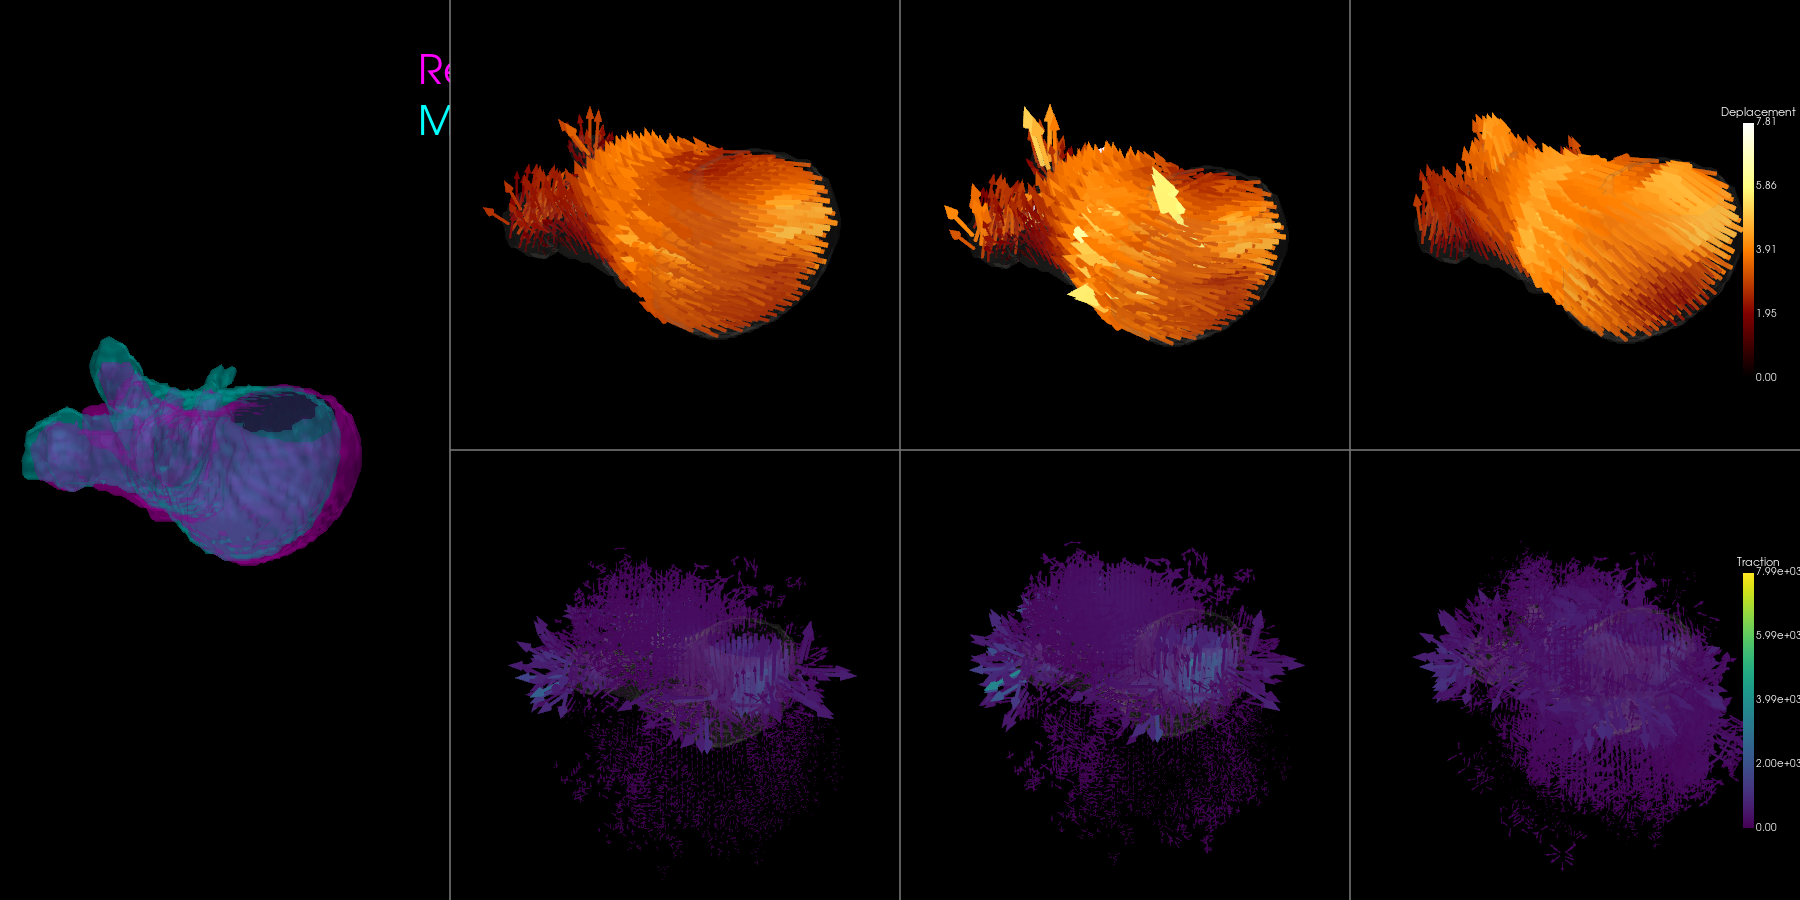

PosixPath('/Users/josephinelahmani/Desktop/nn_dis/results/plots/comparaison_modeles_flow_tractions.png')

In [12]:
show_flow(
    img=img_s,
    flows=[h_fista_s[:,0], h_hs_s[:,0], h_model_s[:,0]],
    tractions=[traction_of_fista, traction_of_hs, traction_of_vxm],
    model_names=["FISTA", "HS", "VXM"],
    name="comparaison_modeles",
    arrow_factor=3.0, 
    stride=2, 
    zoom=1.2, 
    traction_arrow_factor=0.7,
    z_size=spacing_s[0]/spacing_s[1],
    output_dir="/Users/josephinelahmani/Desktop/nn_dis/results/plots",
)

In [114]:
import pyvista as pv

def show_flow(img, flow, name, arrow_factor, stride, zoom, z_size):
    mask = img[0] > 0.1

    u = flow * mask[None, ...]

    nz, ny, nx = img[0].shape

    spacing_xyz = np.array([1.0, 1.0, z_size])

    grid = pv.ImageData(
        dimensions=(nx, ny, nz),
        spacing=tuple(spacing_xyz),
        origin=(0.0, 0.0, 0.0),
    )

    grid.point_data["intensity"] = img[0].ravel(order="C")

    grid.point_data["foreground"] = np.where(mask, img[0], 0).ravel(order="C")

    ijk_zyx = np.argwhere(mask[::stride, ::stride, ::stride]) * stride

    z, y, x = ijk_zyx.T

    points_xyz = ijk_zyx[:, ::-1] * spacing_xyz

    vectors = u[:, z, y, x].T

    component_order = "zyx" 

    if component_order == "zyx":
        vectors_xyz = vectors[:, ::-1]
    elif component_order == "xyz":
        vectors_xyz = vectors
    else:
        raise ValueError("component_order must be 'zyx' or 'xyz'")

    vectors_xyz = vectors_xyz * spacing_xyz

    magnitude = np.linalg.norm(vectors_xyz, axis=1)

    nonzero = magnitude > 0
    cloud = pv.PolyData(points_xyz[nonzero])
    cloud["displacement"] = vectors_xyz[nonzero]
    cloud["magnitude"] = magnitude[nonzero]

    arrow_geometry = pv.Arrow(
        shaft_radius=0.02,
        tip_radius=0.06,
        tip_length=0.20,
    )

    arrows = cloud.glyph(
        geom=arrow_geometry,
        orient="displacement",
        scale="magnitude",
        factor=arrow_factor,
    )

    plotter = pv.Plotter()
    plotter.set_background('black')

    plotter.add_volume(
        grid,
        scalars="foreground",
        cmap="gray",
        clim=(0, float(img[0].max())),
        shade=False,
        show_scalar_bar=False,
    )

    if cloud.n_points:
        plotter.add_mesh(
            arrows,
            scalars="magnitude",
            cmap="afmhot",
            show_scalar_bar=False,
        )

    plotter.view_isometric()
    plotter.camera.zoom(zoom)
    output_path = Path(
            f"/Users/josephinelahmani/Desktop/nn_dis/results/plots/{name}_flow.png"
        )
    plotter.show(screenshot=str(output_path), auto_close=True)

/var/folders/q7/63xbgp7j3lx7627dsblbwqjw0000gn/T/ipykernel_16235/1905797579.py:86: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install trame-pyvista
  plotter.show(screenshot=str(output_path), auto_close=True)


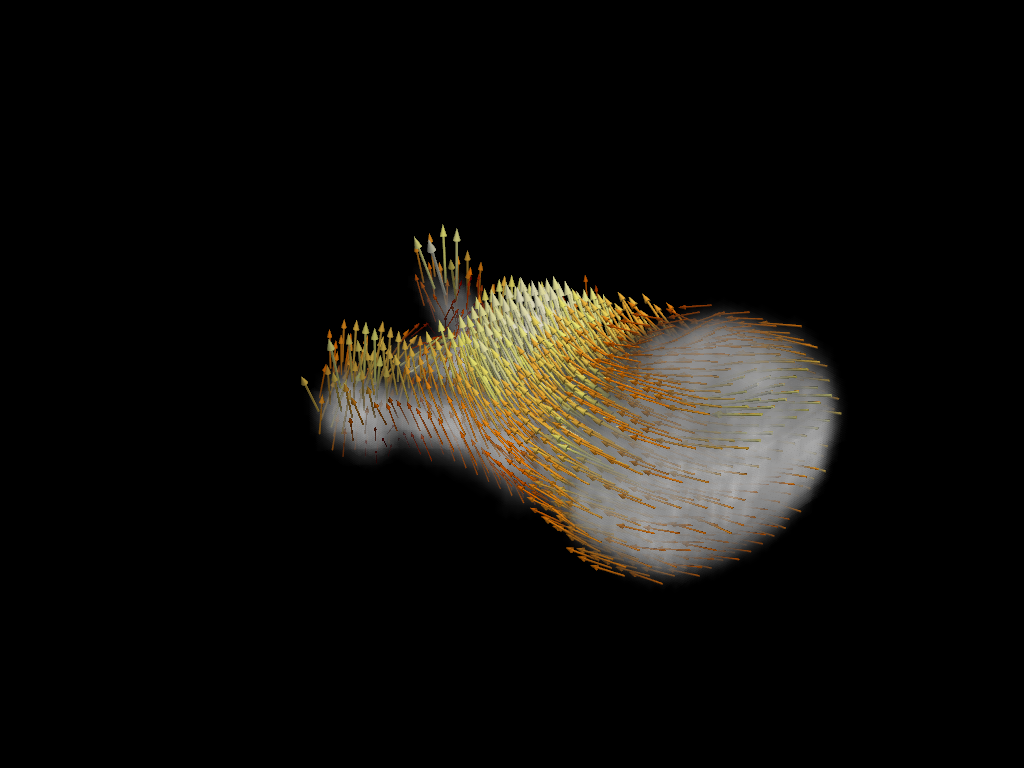

In [122]:
show_flow(img_s, h_fista_s[:,0], 'fista', arrow_factor=3.0, stride=2, zoom=2.0, z_size=spacing_s[0]/spacing_s[1])

/var/folders/q7/63xbgp7j3lx7627dsblbwqjw0000gn/T/ipykernel_16235/1905797579.py:86: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install trame-pyvista
  plotter.show(screenshot=str(output_path), auto_close=True)


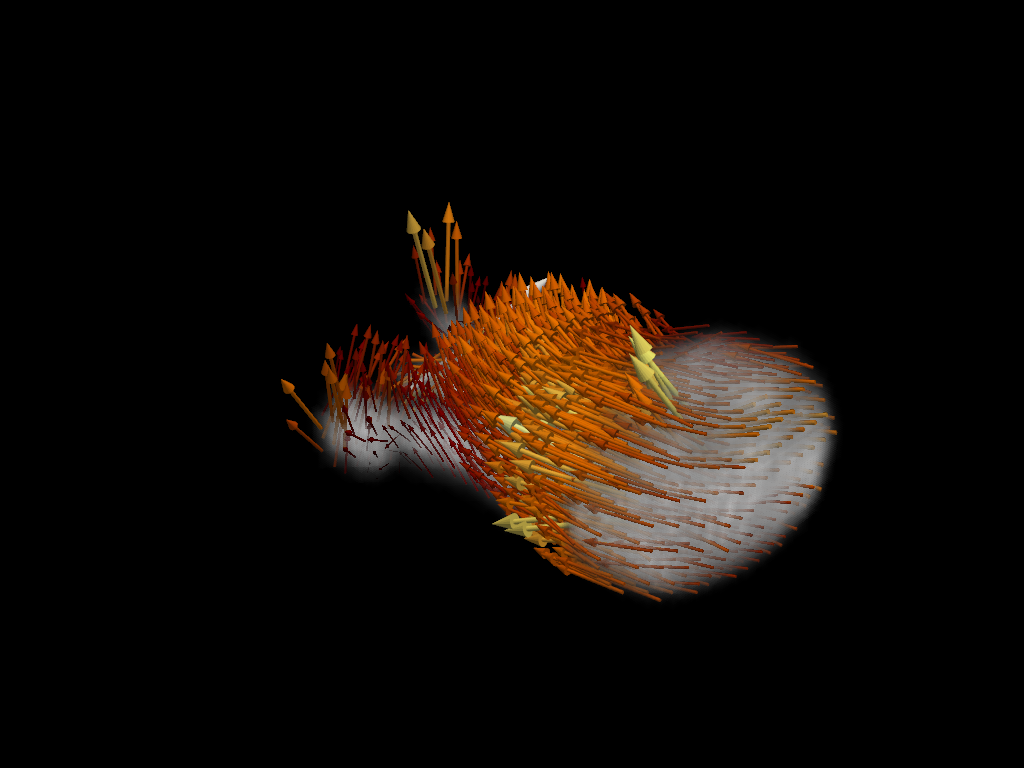

In [120]:
show_flow(img_s, h_hs_s[:,0], 'fista', arrow_factor=3.0, stride=2, zoom=2.0, z_size=spacing_s[0]/spacing_s[1])

/var/folders/q7/63xbgp7j3lx7627dsblbwqjw0000gn/T/ipykernel_16235/1905797579.py:86: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install trame-pyvista
  plotter.show(screenshot=str(output_path), auto_close=True)


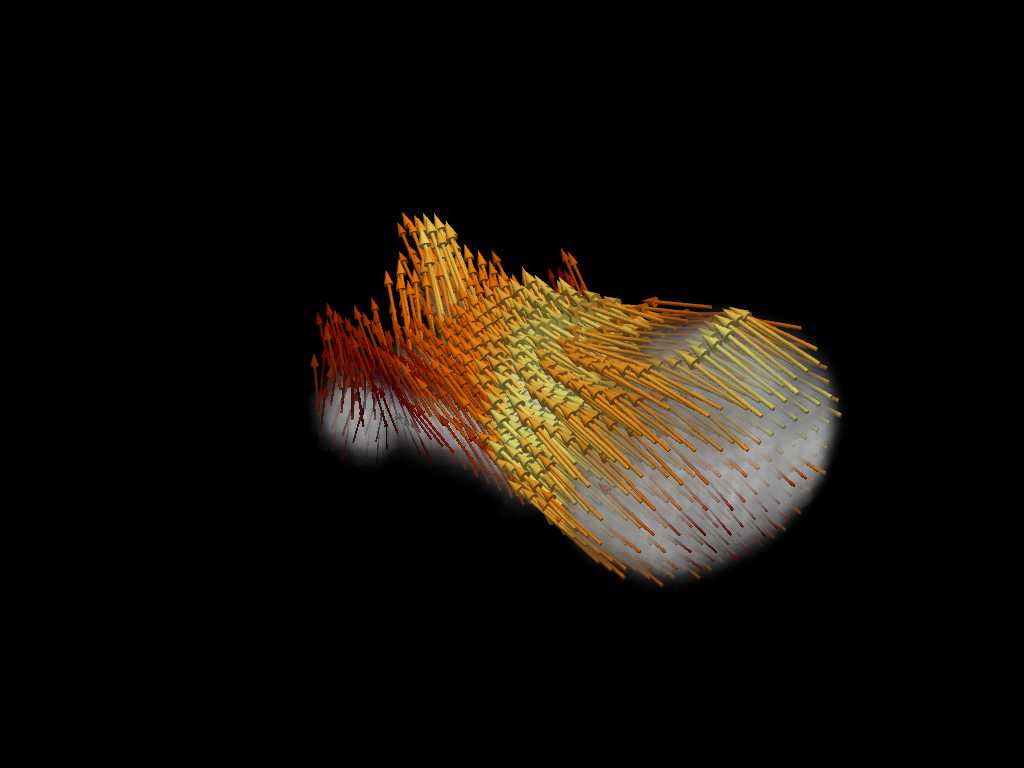

In [121]:
show_flow(img_s, h_model_s[:,0], 'fista', arrow_factor=3.0, stride=2, zoom=2.0, z_size=spacing_s[0]/spacing_s[1])

In [111]:
viewer = napari.Viewer()
viewer.add_image(h_fista_s, scale=spacing_s, name="Def HS")
viewer.add_image(h_hs_s, scale=spacing_s, name="Def FISTA")
viewer.add_image(h_model_s, scale=spacing_s, name="Def model")
napari.run()

In [106]:
viewer = napari.Viewer()
viewer.add_image(def_of_hs, scale=spacing_s, name="Def HS")
viewer.add_image(def_of_fista, scale=spacing_s, name="Def FISTA")
viewer.add_image(def_of_vxm, scale=spacing_s, name="Def model")
napari.run()

In [109]:
import time 

with open(
    "/Users/josephinelahmani/Desktop/nn_dis/configs/optical_flow.yaml", "r"
) as f:
    config = yaml.safe_load(f)

hs_params = SimpleNamespace(**config["optical_flow"]["hs"])
fista_params = SimpleNamespace(**config["optical_flow"]["fista"])

start_time_hs = time.time()
h_hs_s = hs_of(img_s, hs_params, global_flow=True)
time_hs = time.time() - start_time_hs
np.save(save_path / "flow_hs_img_sudheer", h_hs_s[:, 1:])

start_time_fista = time.time()
h_fista_s = fista_of(img_s, fista_params, spacing=spacing_s, global_flow=True)
time_fista = time.time() - start_time_fista
np.save(save_path / "flow_fista_img_sudheer", h_fista_s[:, 1:])

times = {
    "hs": time_hs,
    "fista": time_fista,
}

output_file = save_path / "time_methods_img_sudheer.csv"
with output_file.open("w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["method", "time_seconds"])

    for method, time_ in times.items():
        writer.writerow([method, time_])

In [35]:
viewer = napari.Viewer()
viewer.add_image(img_s[0], scale=spacing_s, name="I1")
viewer.add_image(img_s[1], scale=spacing_s, name="I2")
viewer.add_image(warped_vxm_s, scale=spacing_s, name="warped I2")
viewer.add_image(warped_fista_s, scale=spacing_s, name="warped I2 fista")
viewer.add_image(warped_hs_s, scale=spacing_s, name="warped I2 hs")
napari.run()

In [255]:
diff_im = img_s[1] - img_s[0]
diff_w = warped_vxm_s - img_s[0]
diff_w_fista = warped_fista_s - img_s[0]
diff_w_hs = warped_hs_s - img_s[0]

print('Norms')
print('I2 - I1:', np.linalg.norm(diff_im))
print('warped - I1:', np.linalg.norm(diff_w))
print('warped_fista - I1:', np.linalg.norm(diff_w_fista))
print('warped_hs - I1:', np.linalg.norm(diff_w_hs))

print('RMSE')
print('I2 - I1:', rmse_(diff_im))
print('warped - I1:', rmse_(diff_w))
print('warped_fista - I1:', rmse_(diff_w_fista))
print('warped_hs - I1:', rmse_(diff_w_hs))

Norms
I2 - I1: 31.652721
warped - I1: 31.474588
warped_fista - I1: 9.050713
warped_hs - I1: 9.216828
RMSE
I2 - I1: 0.0437146
warped - I1: 0.043468595
warped_fista - I1: 0.012499653
warped_hs - I1: 0.012729068


In [42]:
get_viewer_flows(img_s, flows=[dis_vxm_s, h_hs_s], flows_name=["VXM", "HS"], spacing=spacing_s, axes=[0, 1, 2])

## Synthetic

In [329]:
results_folder_grf = '/Users/josephinelahmani/Desktop/nn_dis/train_13'

In [ ]:
def get_meca_model(u, spacing, mask, mu, lambda_, normals):
    strain_u = strain_mask(u=u, spacing=spacing, maskcell=mask)
    def_u = deformation(strain_u)
    stress_u = stress_mask(strain_u, mu, lambda_)
    traction_u = compute_traction_3d(stress_u[:, :, 0], normals)
    
    return strain_u, def_u, stress_u, traction_u

In [90]:
import time
folder_synth_img = Path('/Users/josephinelahmani/Desktop/data/3d_synth_of')
save_path = Path("/Users/josephinelahmani/Desktop/nn_dis/data/computed_flows")

diff_u_grf = []
diff_u_grf_grad = []
diff_u_grf_mse = []
diff_u_grf_hess = []
diff_u_grf_mse_grad = []
diff_u_grf_mse_grad_hess = []
diff_u_fista = []
diff_u_hs = []
diff_u_ilk = []
diff_u_tvl1 = []
diff_u_grf_no_sup = []
diff_u_grf_sup_no_sup = []

rmse_strain_model=[]
rmse_def_model=[]
rmse_stress_model=[]
rmse_traction_model=[]

rmse_strain_fista=[]
rmse_def_fista=[]
rmse_stress_fista=[]
rmse_traction_fista=[]

rmse_strain_hs=[]
rmse_def_hs=[]
rmse_stress_hs=[]
rmse_traction_hs=[]

rmse_strain_ilk=[]
rmse_def_ilk=[]
rmse_stress_ilk=[]
rmse_traction_ilk=[]

rmse_strain_tvl1=[]
rmse_def_tvl1=[]
rmse_stress_tvl1=[]
rmse_traction_tvl1=[]

for path_img in folder_synth_img.iterdir():
    filename = path_img.name
    if not filename.endswith(("img.npy", "img.tiff", "img.tif")):
        continue
    
    time_grf = []
    start_time = time.time()
    img, spacing, mask, dis_model_grf_sup_no_sup, warped_model_grf_sup_no_sup, dis_model_masked_grf_sup_no_sup = get_img_dis_model(path_img, results_folder_grf_sup_no_sup)
    time_img = time.time() - start_time
    time_grf.append(time_img)
    
    _, _, _, dis_model_grf_grad, warped_model_grf_grad, dis_model_masked_grf_grad = get_img_dis_model(path_img, results_folder_grf_grad)
    _, _, _, dis_model_grf_mse, warped_model_grf_mse, dis_model_masked_grf_mse = get_img_dis_model(path_img, results_folder_grf_mse)
    _, _, _, dis_model_grf_hess, warped_model_grf_hess, dis_model_masked_grf_hess = get_img_dis_model(path_img, results_folder_grf_hess)
    _, _, _, dis_model_grf_mse_grad, warped_model_grf_mse_grad, dis_model_masked_grf_mse_grad = get_img_dis_model(path_img, results_folder_grf_mse_grad)
    _, _, _, dis_model_grf_mse_grad_hess, warped_model_grf_mse_grad_hess, dis_model_masked_grf_mse_grad_hess = get_img_dis_model(path_img, results_folder_grf_mse_grad_hess)
    _, _, _, dis_model_grf_no_sup, warped_model_grf_no_sup, dis_model_masked_grf_no_sup = get_img_dis_model(path_img, results_folder_grf_no_sup)
    _, _, _, dis_model_grf, warped_model_grf, dis_model_masked_grf = get_img_dis_model(path_img, results_folder_grf)

    ugt_name = filename.replace("_img.npy", "_ugt.npy")
    path_ugt = folder_synth_img / ugt_name
    
    ugt_raw = np.load(path_ugt)

    ugt_pixels = np.stack(
            [ugt_raw[i] / spacing[i] for i in range(ugt_raw.shape[0])]
        )

    ugt = np.stack(
        [
            reshape_img(ugt_pixels[0, 0], 32),
            reshape_img(ugt_pixels[1, 0], 32),
            reshape_img(ugt_pixels[2, 0], 32),
        ]
    )
    
    dis_fista = np.load(save_path / f"flow_fista_{filename}")
    dis_fista = np.stack(
            [dis_fista[i] / spacing[i] for i in range(dis_fista.shape[0])]
        )
    dis_fista_masked = np.stack(
            [dis_fista[i] * mask for i in range(dis_fista.shape[0])]
        )
    dis_hs = np.load(save_path / f"flow_hs_{filename}")
    dis_hs_masked = np.stack(
            [dis_hs[i] * mask for i in range(dis_hs.shape[0])]
        )
    dis_ilk = np.load(save_path / f"flow_ilk_{filename}")
    dis_ilk_masked = np.stack(
            [dis_ilk[i] * mask for i in range(dis_ilk.shape[0])]
        )
    dis_tvl1 = np.load(save_path / f"flow_tvl1_{filename}")
    dis_tvl1_masked = np.stack(
            [dis_tvl1[i] * mask for i in range(dis_tvl1.shape[0])]
        )   
    
    match = re.search(r'E_([\d.]+)_nu_([\d.]+)', filename)

    if match:
        E = float(match.group(1))
        nu = float(match.group(2))
        
    lambda_ = E * nu / ((1.0 + nu) * (1.0 - (nu**2)))
    mu = E / (2.0 * (1.0 + nu))
    
    mask_eroded_gt = ndi.binary_erosion(mask, iterations=3)
    inner_boundary_gt = mask_eroded_gt & (~ndi.binary_erosion(mask_eroded_gt))
    normals = compute_normals_from_mask_3d(mask_eroded_gt)
    normals[:, ~inner_boundary_gt] = 0
    
    strain_gt, def_gt, stress_gt, traction_gt = get_meca_model(ugt[:, np.newaxis], [1, 1, 1], mask, mu, lambda_, normals)
    strain_model, def_model, stress_model, traction_model = get_meca_model(dis_model_grf_sup_no_sup, [1, 1, 1], mask, mu, lambda_, normals)
    strain_fista, def_fista, stress_fista, traction_fista = get_meca_model(dis_fista, [1, 1, 1], mask, mu, lambda_, normals)
    strain_hs, def_hs, stress_hs, traction_hs = get_meca_model(dis_hs, [1, 1, 1], mask, mu, lambda_, normals)
    strain_ilk, def_ilk, stress_ilk, traction_ilk = get_meca_model(dis_ilk, [1, 1, 1], mask, mu, lambda_, normals)
    strain_tvl1, def_tvl1, stress_tvl1, traction_tvl1 = get_meca_model(dis_tvl1, [1, 1, 1], mask, mu, lambda_, normals)
    
    diff_u_grf.append(rmse_(dis_model_masked_grf[:, 0], ugt))
    diff_u_grf_grad.append(rmse_(dis_model_masked_grf_grad[:, 0], ugt))
    diff_u_grf_mse.append(rmse_(dis_model_masked_grf_mse[:, 0], ugt))
    diff_u_grf_hess.append(rmse_(dis_model_masked_grf_hess[:, 0], ugt))
    diff_u_grf_mse_grad.append(rmse_(dis_model_masked_grf_mse_grad[:, 0], ugt))
    diff_u_grf_mse_grad_hess.append(rmse_(dis_model_masked_grf_mse_grad_hess[:, 0], ugt))
    diff_u_grf_no_sup.append(rmse_(dis_model_masked_grf_no_sup[:, 0], ugt))
    diff_u_grf_sup_no_sup.append(rmse_(dis_model_masked_grf_sup_no_sup[:, 0], ugt))
    diff_u_fista.append(rmse_(dis_fista_masked[:, 0], ugt))
    diff_u_hs.append(rmse_(dis_hs_masked[:, 0], ugt))
    diff_u_ilk.append(rmse_(dis_ilk_masked[:, 0], ugt))
    diff_u_tvl1.append(rmse_(dis_tvl1_masked[:, 0], ugt))
    
    rmse_strain_model.append(rmse(strain_model, strain_gt))
    rmse_def_model.append(rmse(def_model, def_gt))
    rmse_stress_model.append(rmse(stress_model, stress_gt))
    rmse_traction_model.append(rmse(traction_model, traction_gt))

    rmse_strain_fista.append(rmse(strain_fista, strain_gt))
    rmse_def_fista.append(rmse(def_fista, def_gt))
    rmse_stress_fista.append(rmse(stress_fista, stress_gt))
    rmse_traction_fista.append(rmse(traction_fista, traction_gt))

    rmse_strain_hs.append(rmse(strain_hs, strain_gt))
    rmse_def_hs.append(rmse(def_hs, def_gt))
    rmse_stress_hs.append(rmse(stress_hs, stress_gt))
    rmse_traction_hs.append(rmse(traction_hs, traction_gt))

    rmse_strain_ilk.append(rmse(strain_ilk, strain_gt))
    rmse_def_ilk.append(rmse(def_ilk, def_gt))
    rmse_stress_ilk.append(rmse(stress_ilk, stress_gt))
    rmse_traction_ilk.append(rmse(traction_ilk, traction_gt))
    
    rmse_strain_tvl1.append(rmse(strain_tvl1, strain_gt))
    rmse_def_tvl1.append(rmse(def_tvl1, def_gt))
    rmse_stress_tvl1.append(rmse(stress_tvl1, stress_gt))
    rmse_traction_tvl1.append(rmse(traction_tvl1, traction_gt))

# print("sup", np.mean(diff_u_grf))
# print("sup + grad", np.mean(diff_u_grf_grad))
# print("sup + mse", np.mean(diff_u_grf_mse))
# print("sup + hess", np.mean(diff_u_grf_hess))
# print("sup + mse + grad", np.mean(diff_u_grf_mse_grad))
# print("sup + mse + grad + hess", np.mean(diff_u_grf_mse_grad_hess))
# print("mse + grad + hess", np.mean(diff_u_grf_no_sup))
# print("sup -> mse + grad + hess", np.mean(diff_u_grf_sup_no_sup))
# print("fista", np.mean(diff_u_fista))
# print("hs", np.mean(diff_u_hs))
# print("ilk", np.mean(diff_u_ilk))
# print("tvl1", np.mean(diff_u_tvl1))
# print("time grf", np.mean(time_grf))


print('FISTA')
print(f'rmse_u_fista={np.mean(diff_u_fista)}')
print(f'rmse_strain_fista={np.mean(rmse_strain_fista)}')
print(f'rmse_def_fista={np.mean(rmse_def_fista)}')
print(f'rmse_stress_fista={np.mean(rmse_stress_fista)}')
print(f'rmse_traction_fista={np.mean(rmse_traction_fista)}')

print('\nHS')
print(f'rmse_u_hs={np.mean(diff_u_hs)}')
print(f'rmse_strain_hs={np.mean(rmse_strain_hs)}')
print(f'rmse_def_hs={np.mean(rmse_def_hs)}')
print(f'rmse_stress_hs={np.mean(rmse_stress_hs)}')
print(f'rmse_traction_hs={np.mean(rmse_traction_hs)}')

print('\nILK')
print(f'rmse_u_ilk={np.mean(diff_u_ilk)}')
print(f'rmse_strain_ilk={np.mean(rmse_strain_ilk)}')
print(f'rmse_def_ilk={np.mean(rmse_def_ilk)}')
print(f'rmse_stress_ilk={np.mean(rmse_stress_ilk)}')
print(f'rmse_traction_ilk={np.mean(rmse_traction_ilk)}')

print('\nTVL1')
print(f'rmse_u_tvl1={np.mean(diff_u_tvl1)}')
print(f'rmse_strain_tvl1={np.mean(rmse_strain_tvl1)}')
print(f'rmse_def_tvl1={np.mean(rmse_def_tvl1)}')
print(f'rmse_stress_tvl1={np.mean(rmse_stress_tvl1)}')
print(f'rmse_traction_tvl1={np.mean(rmse_traction_tvl1)}')

print('\nModel')
print(f'rmse_u_model={np.mean(diff_u_grf_sup_no_sup)}')
print(f'rmse_strain_model={np.mean(rmse_strain_model)}')
print(f'rmse_def_model={np.mean(rmse_def_model)}')
print(f'rmse_stress_model={np.mean(rmse_stress_model)}')
print(f'rmse_traction_model={np.mean(rmse_traction_model)}')

FISTA
rmse_u_fista=0.27221492453241614
rmse_strain_fista=0.051222012308989553
rmse_def_fista=0.12752100079958176
rmse_stress_fista=13.444759959002493
rmse_traction_fista=4.412143994861175

HS
rmse_u_hs=0.313529173049109
rmse_strain_hs=0.05540575351360216
rmse_def_hs=0.154946482403915
rmse_stress_hs=14.625264020679156
rmse_traction_hs=4.971027466166889

ILK
rmse_u_ilk=0.31264287679869746
rmse_strain_ilk=0.05707415384182931
rmse_def_ilk=0.1370676182047305
rmse_stress_ilk=15.839446110335546
rmse_traction_ilk=5.321914366230202

TVL1
rmse_u_tvl1=0.32367941623617935
rmse_strain_tvl1=0.05695513212222314
rmse_def_tvl1=0.15262589341603852
rmse_stress_tvl1=15.414203816111613
rmse_traction_tvl1=5.619274268855269

Model
rmse_u_model=0.3918200135231018
rmse_strain_model=0.05580969844239742
rmse_def_model=0.15938445679729762
rmse_stress_model=14.574603508788691
rmse_traction_model=5.012356730715402


In [91]:
get_viewer_flows(img, flows=[ugt[:, np.newaxis], dis_model_masked_grf_sup_no_sup, dis_fista_masked], flows_name=["UGT", "GT", "FISTA"], spacing=spacing, axes=[0, 1, 2])

Context leak detected, CoreAnalytics returned false


In [67]:
def get_meca_model(u, spacing, mask, mu, lambda_, normals):
    strain_u = strain_mask(u=u, spacing=spacing, maskcell=mask)
    def_u = deformation(strain_u)
    stress_u = stress_mask(strain_u, mu, lambda_)
    traction_u = compute_traction_3d(stress_u[:, :, 0], normals)
    
    return strain_u, def_u, stress_u, traction_u


In [77]:
save_path = Path("/Users/josephinelahmani/Desktop/nn_dis/data/computed_flows")

path_img = Path('/Users/josephinelahmani/Desktop/data/3d_synth_of/E_300.0_nu_0.4_nb_zones_3_im_00_seed_01_img.npy')
path_ugt = Path('/Users/josephinelahmani/Desktop/data/3d_synth_of/E_300.0_nu_0.4_nb_zones_3_im_00_seed_01_ugt.npy')

filename = 'E_300.0_nu_0.4_nb_zones_3_im_00_seed_01_img.npy'

E = 300.0
nu = 0.4

lambda_ = E * nu / ((1.0 + nu) * (1.0 - (nu**2)))
mu = E / (2.0 * (1.0 + nu))

img, spacing, mask, dis_model_grf_sup_no_sup, warped_model_grf_sup_no_sup, dis_model_masked_grf_sup_no_sup = get_img_dis_model(path_img, results_folder_grf_sup_no_sup)

dis_fista = np.load(save_path / f"flow_fista_{filename}")
dis_fista = np.stack(
        [dis_fista[i] / spacing[i] for i in range(dis_fista.shape[0])]
    )

dis_hs = np.load(save_path / f"flow_hs_{filename}")

dis_ilk = np.load(save_path / f"flow_ilk_{filename}")

dis_tvl1 = np.load(save_path / f"flow_tvl1_{filename}")
    
ugt_raw = np.load(path_ugt)

ugt_pixels = np.stack(
        [ugt_raw[i] / spacing[i] for i in range(ugt_raw.shape[0])]
    )

ugt = np.stack(
    [
        reshape_img(ugt_pixels[0, 0], 32),
        reshape_img(ugt_pixels[1, 0], 32),
        reshape_img(ugt_pixels[2, 0], 32),
    ]
)

mask_eroded_gt = ndi.binary_erosion(mask, iterations=3)
inner_boundary_gt = mask_eroded_gt & (~ndi.binary_erosion(mask_eroded_gt))
normals = compute_normals_from_mask_3d(mask_eroded_gt)
normals[:, ~inner_boundary_gt] = 0
    


In [78]:
strain_gt, def_gt, stress_gt, traction_gt = get_meca_model(ugt[:, np.newaxis], [1, 1, 1], mask, mu, lambda_, normals)
strain_model, def_model, stress_model, traction_model = get_meca_model(dis_model_grf_sup_no_sup, [1, 1, 1], mask, mu, lambda_, normals)
strain_fista, def_fista, stress_fista, traction_fista = get_meca_model(dis_fista, [1, 1, 1], mask, mu, lambda_, normals)
strain_hs, def_hs, stress_hs, traction_hs = get_meca_model(dis_hs, [1, 1, 1], mask, mu, lambda_, normals)
strain_ilk, def_ilk, stress_ilk, traction_ilk = get_meca_model(dis_ilk, [1, 1, 1], mask, mu, lambda_, normals)

In [79]:
rmse_strain_model = rmse(strain_model, strain_gt)
rmse_def_model = rmse(def_model, def_gt)
rmse_stress_model = rmse(stress_model, stress_gt)
rmse_traction_model = rmse(traction_model, traction_gt)

rmse_strain_fista = rmse(strain_fista, strain_gt)
rmse_def_fista = rmse(def_fista, def_gt)
rmse_stress_fista = rmse(stress_fista, stress_gt)
rmse_traction_fista = rmse(traction_fista, traction_gt)

rmse_strain_hs = rmse(strain_hs, strain_gt)
rmse_def_hs = rmse(def_hs, def_gt)
rmse_stress_hs = rmse(stress_hs, stress_gt)
rmse_traction_hs = rmse(traction_hs, traction_gt)

rmse_strain_ilk = rmse(strain_ilk, strain_gt)
rmse_def_ilk = rmse(def_ilk, def_gt)
rmse_stress_ilk = rmse(stress_ilk, stress_gt)
rmse_traction_ilk = rmse(traction_ilk, traction_gt)

print('FISTA')
print(f'{rmse_strain_fista=}')
print(f'{rmse_def_fista=}')
print(f'{rmse_stress_fista=}')
print(f'{rmse_traction_fista=}')

print('HS')
print(f'{rmse_strain_hs=}')
print(f'{rmse_def_hs=}')
print(f'{rmse_stress_hs=}')
print(f'{rmse_traction_hs=}')

print('ILK')
print(f'{rmse_strain_ilk=}')
print(f'{rmse_def_ilk=}')
print(f'{rmse_stress_ilk=}')
print(f'{rmse_traction_ilk=}')

print('\nModel')
print(f'{rmse_strain_model=}')
print(f'{rmse_def_model=}')
print(f'{rmse_stress_model=}')
print(f'{rmse_traction_model=}')

FISTA
rmse_strain_fista=np.float64(0.13648883178437196)
rmse_def_fista=np.float64(0.3871461856098029)
rmse_stress_fista=np.float64(29.38931407384252)
rmse_traction_fista=np.float64(8.239611134310024)
HS
rmse_strain_hs=np.float64(0.16196181060451975)
rmse_def_hs=np.float64(0.4693422731176153)
rmse_stress_hs=np.float64(34.89133859279398)
rmse_traction_hs=np.float64(11.52507870585898)
ILK
rmse_strain_ilk=np.float64(0.16678948278060296)
rmse_def_ilk=np.float64(0.4263211769227448)
rmse_stress_ilk=np.float64(36.934499534985115)
rmse_traction_ilk=np.float64(12.233801855850407)

Model
rmse_strain_model=np.float64(0.16268321869484603)
rmse_def_model=np.float64(0.4800204249498851)
rmse_stress_model=np.float64(34.95372693687969)
rmse_traction_model=np.float64(11.534016600508354)


In [175]:
save_path = Path("/Users/josephinelahmani/Desktop/nn_dis/data")

name_img = 'E_1000_nu_0.4_nb_zones_1_test_x_img.npy'

path_img_synth =  Path('/Users/josephinelahmani/Desktop/data/3d_synthetic/E_500.0_nu_0.4_nb_zones_3_im_00_seed_01_img.npy') #Path('/Users/josephinelahmani/Desktop/nn_dis/data/E_1000_nu_0.4_nb_zones_1_test_x_img.npy') #
path_ugt = Path('/Users/josephinelahmani/Desktop/data/3d_synthetic/E_500.0_nu_0.4_nb_zones_3_im_00_seed_01_ugt.npy') #Path('/Users/josephinelahmani/Desktop/nn_dis/data/E_1000_nu_0.4_nb_zones_1_test_x_ugt.npy') #
results_folder = results_folder_grf

img_synth, spacing_synth, dis_vxm_synth_grf, warped_vxm_synth_grf = register(img_path=path_img_synth, folder_path=results_folder_grf, model_type='aniso', default_spacing=[1.0, 0.13, 0.13])
dis_vxm_synth_grf = np.transpose(dis_vxm_synth_grf, (1, 0, 2, 3, 4))

img_synth, spacing_synth, dis_vxm_synth_grf_grad, warped_vxm_synth_grf_grad = register(img_path=path_img_synth, folder_path=results_folder_grf_grad, model_type='aniso', default_spacing=[1.0, 0.13, 0.13])
dis_vxm_synth_grf_grad = np.transpose(dis_vxm_synth_grf_grad, (1, 0, 2, 3, 4))

img_synth, spacing_synth, dis_vxm_synth_grf_mse, warped_vxm_synth_grf_mse = register(img_path=path_img_synth, folder_path=results_folder_grf_mse, model_type='aniso', default_spacing=[1.0, 0.13, 0.13])
dis_vxm_synth_grf_mse = np.transpose(dis_vxm_synth_grf_mse, (1, 0, 2, 3, 4))

mask_synth = img_synth[0] > 0.1
dis_vxm_masked_synth_grf = np.stack(
        [dis_vxm_synth_grf[i] * mask_synth for i in range(dis_vxm_synth_grf.shape[0])]
    )

dis_vxm_masked_synth_grf_grad = np.stack(
        [dis_vxm_synth_grf_grad[i] * mask_synth for i in range(dis_vxm_synth_grf_grad.shape[0])]
    )

dis_vxm_masked_synth_grf_mse = np.stack(
        [dis_vxm_synth_grf_mse[i] * mask_synth for i in range(dis_vxm_synth_grf_mse.shape[0])]
    )

ugt_raw = np.load(path_ugt)

ugt_pixels = np.stack(
        [ugt_raw[i] / spacing_synth[i] for i in range(ugt_raw.shape[0])]
    )

ugt = np.stack(
    [
        reshape_img(ugt_pixels[0, 0], 32),
        reshape_img(ugt_pixels[1, 0], 32),
        reshape_img(ugt_pixels[2, 0], 32),
    ]
)

dis_fista_synth = np.load(save_path / f"flow_fista_{name_img}")
dis_fista_masked_synth = np.load(save_path / f"flow_fista_masked_{name_img}")
dis_hs_synth = np.load(save_path / f"flow_hs_{name_img}")
dis_hs_masked_synth = np.load(save_path / f"flow_hs_masked_{name_img}")

# warped_fista_synth = warp(img_synth[1], h_fista_synth[:, 0])
# warped_hs_synth = warp(img_synth[1], h_hs_synth[:, 0])

In [130]:
get_viewer_flows(img_synth, flows=[ugt[:, np.newaxis], dis_vxm_masked_synth_grf, dis_vxm_masked_synth_grf_grad, dis_vxm_masked_synth_grf_mse], flows_name=["UGT", "GT", "GT + grad", "GT + mse"], spacing=spacing_synth, axes=[0, 1, 2])

In [521]:
from optical_flow.algorithms import ilk
with open(
    "/Users/josephinelahmani/Desktop/nn_dis/configs/optical_flow.yaml", "r") as f:
    config = yaml.safe_load(f)

ilk_params = SimpleNamespace(**config["optical_flow"]["ilk"])
fista_params = SimpleNamespace(**config["optical_flow"]["fista"])
hs_params = SimpleNamespace(**config["optical_flow"]["hs"])

h_ilk = ilk(img_synth, ilk_params, False)
h_hs = hs_of(img_synth, hs_params, False)
#h_fista = fista_of(img_synth, fista_params, global_flow=False, spacing=spacing_synth)

diff_u_ilk = compute_mse(h_ilk, ugt, mask_synth)
print(diff_u_ilk)

4.167776711458285


In [535]:
diff_0_hs = compute_mse(np.zeros_like(h_hs), ugt, mask_synth)
print("mse 0", diff_0_hs)

mse 0 4.8805653409014536


Traceback (most recent call last):
  File "/opt/anaconda3/envs/voxelmorph/lib/python3.12/site-packages/napari/_qt/qt_main_window.py", line 638, in closeEvent
    quit_app_()
  File "/opt/anaconda3/envs/voxelmorph/lib/python3.12/site-packages/napari/_qt/qt_event_loop.py", line 291, in quit_app
    v.close()
  File "/opt/anaconda3/envs/voxelmorph/lib/python3.12/site-packages/napari/viewer.py", line 276, in close
    self.window.close()
  File "/opt/anaconda3/envs/voxelmorph/lib/python3.12/site-packages/napari/_qt/qt_main_window.py", line 1866, in close
    self._qt_viewer.close()
RuntimeError: wrapped C/C++ object of type QtViewer has been deleted


In [532]:
diff_u_hs = compute_mse(h_hs, ugt, mask_synth)
diff_u = compute_mse(dis_vxm_synth_rigid, ugt, mask_synth)
diff_u_ilk = compute_mse(h_ilk, ugt, mask_synth)
print("mse nn", diff_u)
print("mse hs", diff_u_hs)
print("mse ilk", diff_u_ilk)

mse nn 10.14392578379529
mse hs 4.592012901779846
mse ilk 4.167776711458285


In [525]:
dis_hs_masked_synth_rigid = np.stack(
        [h_hs[i] * mask_synth for i in range(h_hs.shape[0])]
    )
dis_ilk_masked_synth_rigid = np.stack(
        [h_ilk[i] * mask_synth for i in range(h_ilk.shape[0])]
    )

In [48]:
get_viewer_flows(img_synth, flows=[ugt[:, np.newaxis], dis_vxm_masked_synth_rigid, dis_hs_masked_synth_rigid], flows_name=["UGT", "VXM", "HS"], spacing=spacing_synth, axes=[0, 1, 2])

NameError: name 'dis_hs_masked_synth_rigid' is not defined

In [19]:
save_path = Path("/Users/josephinelahmani/Desktop/nn_dis/data")

name_img = 'E_1000_nu_0.4_nb_zones_1_test_z_img.npy'

path_img_synth = Path('/Users/josephinelahmani/Desktop/nn_dis/data/E_1000_nu_0.4_nb_zones_1_test_z_img.npy')
path_ugt = Path('/Users/josephinelahmani/Desktop/nn_dis/data/E_1000_nu_0.4_nb_zones_1_test_z_ugt.npy')

img_synth, spacing_synth, dis_vxm_synth_rigid, warped_vxm_synth_rigid = register(img_path=path_img_synth, folder_path=results_folder_rigid_grf, model_type='aniso', default_spacing=[1.0, 0.13, 0.13])
dis_vxm_synth_rigid = np.transpose(dis_vxm_synth_rigid, (1, 0, 2, 3, 4))

mask_synth = img_synth[0] > 0.1

h_fista_synth = np.load(save_path / f"flow_fista_{name_img}")
h_fista_masked_synth = np.load(save_path / f"flow_fista_masked_{name_img}")
h_hs_synth = np.load(save_path / f"flow_hs_{name_img}")
h_hs_masked_synth = np.load(save_path / f"flow_hs_masked_{name_img}")

warped_fista_synth = warp(img_synth[1], h_fista_synth[:, 0])
warped_hs_synth = warp(img_synth[1], h_hs_synth[:, 0])

ugt_raw = np.load(path_ugt)

ugt_pixels = np.stack(
        [ugt_raw[i] / spacing_synth[i] for i in range(ugt_raw.shape[0])]
    )

ugt = np.stack(
    [
        reshape_img(ugt_pixels[0, 0], 32),
        reshape_img(ugt_pixels[1, 0], 32),
        reshape_img(ugt_pixels[2, 0], 32),
    ]
)

diff_u_vxm_synth_rigid_ = dis_vxm_synth_rigid[:,0] - ugt
diff_u_vxm_synth_rigid = np.stack(
        [(diff_u_vxm_synth_rigid_[i] ** 2) for i in range(diff_u_vxm_synth_rigid_.shape[0])]
    )
diff_u = (diff_u_vxm_synth_rigid * mask_synth).sum() / (3 * mask_synth.sum() + 1e-8)
    

NameError: name 'results_folder_rigid_grf' is not defined

In [ ]:
# diff_u_vxm_rigid = np.sum(((dis_vxm_masked_synth_rigid[:,0] - ugt) ** 2) * mask_synth) / np.sum(((ugt) ** 2) * mask_synth)
#dis_vxm_masked_synth_rigid - ugt[:, np.newaxis]
diff_u_vxm_rigid_grf_smoothed = np.sum(((dis_vxm_masked_synth_rigid_grf[:,0] - ugt) ** 2) * mask_synth) / np.sum(((ugt) ** 2) * mask_synth) #dis_vxm_masked_test - u_gt_masked_test[:, np.newaxis]
#dis_vxm_masked_synth_rigid_grf_smoothed - ugt[:, np.newaxis]
diff_u_vxm_rigid_grf = np.sum(((dis_vxm_masked_synth_rigid_grf[:,0] - ugt) ** 2) * mask_synth) / np.sum(((ugt) ** 2) * mask_synth) 
#dis_vxm_masked_synth_rigid_grf - ugt[:, np.newaxis]
diff_u_hs = np.sum(((h_hs_masked_synth[:,0] - ugt) ** 2) * mask_synth) / np.sum(((ugt) ** 2) * mask_synth)
#h_hs_masked_synth - ugt[:, np.newaxis]
diff_u_fista = np.sum(((h_fista_masked_synth[:,0] - ugt) ** 2) * mask_synth) / np.sum(((ugt) ** 2) * mask_synth)
#h_fista_masked_synth - ugt[:, np.newaxis]


print('\nFlows results')
# print('Norms')
# print('dis_rigid_model - ugt:', np.linalg.norm(diff_u_vxm_rigid))
# print('dis_rigid_grf_smoothed_model - ugt:', np.linalg.norm(diff_u_vxm_rigid_grf_smoothed))
# print('dis_rigid_grf_model - ugt:', np.linalg.norm(diff_u_vxm_rigid_grf))
# print('dis_hs - ugt:', np.linalg.norm(diff_u_hs))
# print('dis_fista - ugt:', np.linalg.norm(diff_u_fista))

print('\nRMSE')
# print('dis_rigid_model - ugt:', rmse_(diff_u_vxm_rigid))
# print('dis_rigid_grf_smoothed_model - ugt:', rmse_(diff_u_vxm_rigid_grf_smoothed))
# print('dis_rigid_grf_model - ugt:', rmse_(diff_u_vxm_rigid_grf))
print("dis_hs - ugt", rmse_(diff_u_hs))
print("dis_fista - ugt", rmse_(diff_u_fista))

NameError: name 'dis_vxm_masked_synth_rigid_grf' is not defined

In [349]:
viewer = napari.Viewer()
viewer.add_image(img_synth[0], scale=spacing_synth, name="I1", interpolation3d="nearest")
viewer.add_image(img_synth[1], scale=spacing_synth, name="I2", interpolation3d="nearest")
viewer.add_image(warped_vxm_synth, scale=spacing_synth, name="warped I2", interpolation3d="nearest")
viewer.add_image(warped_vxm_of_synth, scale=spacing_synth, name="warped I2 OF", interpolation3d="nearest")
viewer.add_image(warped_fista_synth, scale=spacing_synth, name="warped_fista I2", interpolation3d="nearest")
viewer.add_image(warped_hs_synth, scale=spacing_synth, name="warped_hs I2", interpolation3d="nearest")
napari.run()

In [117]:
get_viewer_flows(img_synth, flows=[ugt[:, np.newaxis], dis_vxm_masked_synth_rigid, h_hs_masked_synth], flows_name=["UGT", "VXM", "HS"], spacing=spacing_synth, axes=[0, 1, 2])

In [ ]:
diff_im_synth = img_synth[1] - img_synth[0]
diff_w_synth = warped_vxm_synth - img_synth[0]
diff_w_of_synth = warped_vxm_of_synth - img_synth[0]
diff_w_hs_synth = warped_hs_synth - img_synth[0]
diff_w_fista_synth = warped_fista_synth - img_synth[0]

diff_u_vxm = dis_vxm_masked_synth - ugt[:, np.newaxis]
diff_u_hs = h_hs_masked_synth - ugt[:, np.newaxis]
diff_u_fista = h_fista_masked_synth - ugt[:, np.newaxis]

# print('Warping results')
# print('Norms')
# print('I2 - I1:', np.linalg.norm(diff_im_synth))
# print('warped - I1:', np.linalg.norm(diff_w_synth))
# print('warped_with_of - I1:', np.linalg.norm(diff_w_of_synth))
# print('warped_hs - I1:', np.linalg.norm(diff_w_hs_synth))
# print('warped_fista - I1:', np.linalg.norm(diff_w_fista_synth))

# print('\nRMSE')
# print('I2 - I1:', rmse_(diff_im))
# print('warped - I1:', rmse_(diff_w_synth))
# print('warped_with_of - I1:', rmse_(diff_w_of_synth))
# print('warped_hs - I1:', rmse_(diff_w_hs_synth))
# print('warped_fista - I1:', rmse_(diff_w_fista_synth))

print('\nFlows results')
print('Norms')
print('dis_vxm - ugt:', np.linalg.norm(diff_u_vxm))
print('dis_hs - ugt:', np.linalg.norm(diff_u_hs))
print('dis_fista - ugt:', np.linalg.norm(diff_u_fista))

print('\nRMSE')
print("dis_vxm - ugt", rmse_(diff_u_vxm))
print("dis_hs - ugt", rmse_(diff_u_hs))
print("dis_fista - ugt", rmse_(diff_u_fista))

Warping results
Norms
I2 - I1: 9.496513
warped - I1: 27.128561
warped_with_of - I1: 27.128567
warped_hs - I1: 5.521374
warped_fista - I1: 6.6211815

RMSE
I2 - I1: 0.0437146
warped - I1: 0.03746639
warped_with_of - I1: 0.037466396
warped_hs - I1: 0.0076253926
warped_fista - I1: 0.0091443015

Flows results
Norms
dis_vxm - ugt: 543.5251
dis_hs - ugt: 473.70438521732973
dis_fista - ugt: 493.51214034647097

RMSE
dis_vxm - ugt 0.4333852
dis_hs - ugt 0.3777129012699415
dis_fista - ugt 0.39350681175704844


In [17]:
path_img_val = Path('/Users/josephinelahmani/helix_mount/data/fractals/rigid/test/fractal_1_10_funcs_img.npy')
path_ugt_val = Path('/Users/josephinelahmani/helix_mount/data/fractals/rigid/all_data/fractal_1_10_funcs_ugt.npy')

img_val, spacing_val, dis_vxm_val, warped_vxm_val = register(img_path=path_img_val, folder_path=results_folder, model_type='aniso', nb_warps=1, default_spacing=[4.0, 1.0, 1.0])
dis_vxm_val = np.transpose(dis_vxm_val, (1, 0, 2, 3, 4))

ugt_val = np.load(path_ugt_val)

u_gt_val = np.stack(
    [
        reshape_img(ugt_val[0]),
        reshape_img(ugt_val[1]),
        reshape_img(ugt_val[2]),
    ]
)

mask_val = img_val[0] > 0.01
dis_vxm_masked_val = np.stack(
        [dis_vxm_val[i] * mask_val for i in range(dis_vxm_val.shape[0])]
    )
u_gt_masked_val = np.stack(
        [u_gt_val[i] * mask_val for i in range(u_gt_val.shape[0])]
    )

diff_im_val = img_val[1] - img_val[0]
diff_w_val = warped_vxm_val - img_val[0]
diff_u_vxm_val = dis_vxm_masked_val - u_gt_val[:, np.newaxis]

def rmse_(diff):
    return np.sqrt(np.mean(diff**2))

print('Results')
print('Norms')
print('diff_w', np.linalg.norm(diff_w_val))
print('dis_vxm - ugt:', np.linalg.norm(diff_u_vxm_val))

print('\nRMSE')
print("dis_vxm - ugt", rmse_(diff_u_vxm_val))
print('diff_w', rmse_(diff_w_val))

Results
Norms
diff_w 7.3734446
dis_vxm - ugt: 12528.486

RMSE
dis_vxm - ugt 9.989714
diff_w 0.010183229


In [96]:
path_img_val = Path('/Users/josephinelahmani/helix_mount/data/fractals/rigid/all_data/fractal_1_10_funcs_img.npy')
path_ugt_val = Path('/Users/josephinelahmani/helix_mount/data/fractals/rigid/all_data/fractal_1_10_funcs_ugt.npy')
ugt_val = np.load(path_ugt_val)

u_gt_val = np.stack(
    [
        reshape_img(ugt_val[0]),
        reshape_img(ugt_val[1]),
        reshape_img(ugt_val[2]),
    ]
)

mask_val = img_val[0] > 0.01
u_gt_masked_val = np.stack(
        [u_gt_val[i] * mask_val for i in range(u_gt_val.shape[0])]
    )

img_val, spacing_val, dis_vxm_val, warped_vxm_val = register(img_path=path_img_val, folder_path=results_folder, model_type='aniso', nb_warps=1, default_spacing=[4.0, 1.0, 1.0])

with open(
    "/Users/josephinelahmani/Desktop/nn_dis/configs/optical_flow.yaml", "r"
) as f:
    config = yaml.safe_load(f)

hs_params = SimpleNamespace(**config["optical_flow"]["hs"])

h_hs_val = hs_of(img_val, hs_params, global_flow=False)

h_hs_masked_val = np.stack([h_hs_val[i] * mask_val for i in range(h_hs_val.shape[0])])

In [29]:
viewer = napari.Viewer()
viewer.add_image(img_val[0], scale=spacing_val, name="I1")
viewer.add_image(img_val[1], scale=spacing_val, name="I2")
viewer.add_image(warped_vxm_val, scale=spacing_val, name="warped I2")
napari.run()

In [26]:
get_viewer_flows(img_val, flows=[u_gt_masked_val[:, np.newaxis], dis_vxm_masked_val], flows_name=["UGT", "HS"], spacing=spacing_val, axes=[0, 1, 2])

In [5]:
# viewer = napari.Viewer()
# viewer.add_image(img_padded, scale=new_spacing)

Min: -5.7958
Max: 3.8522
Mean abs: 0.7774


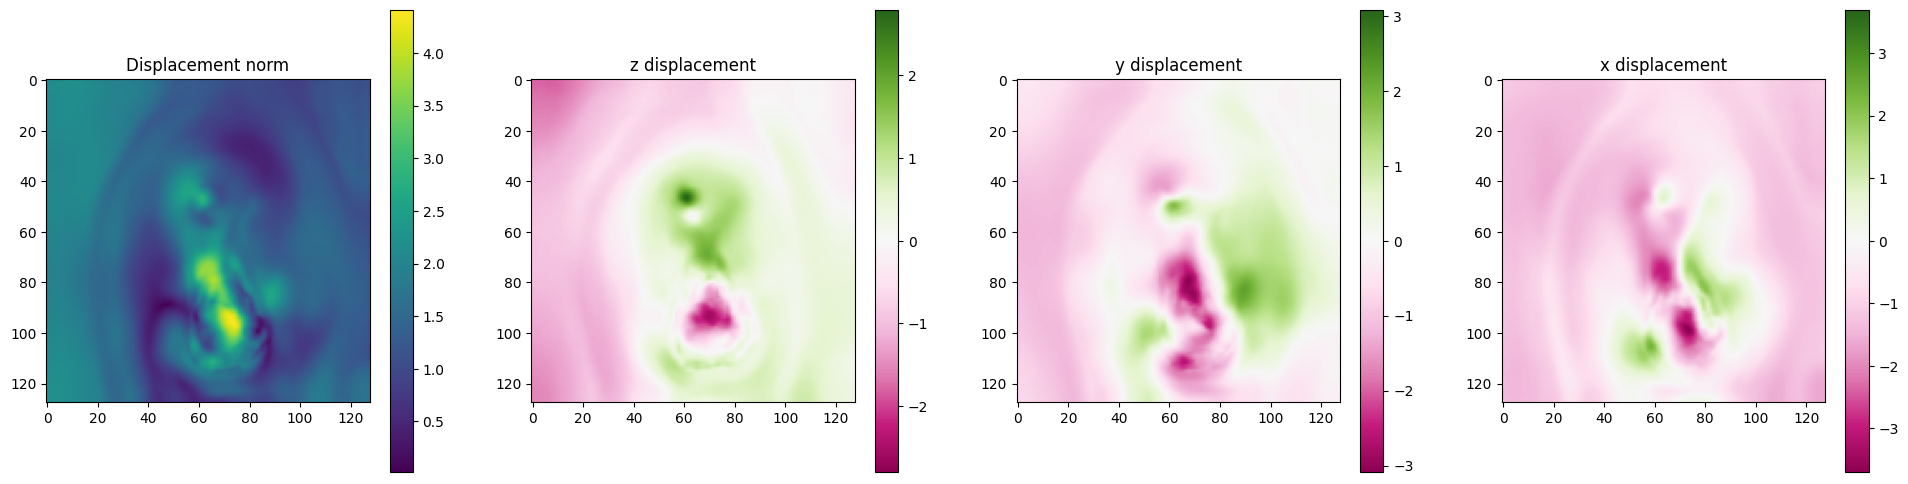

In [14]:
### Visualize displacement results

print(f"Min: {dis.min():.4f}")
print(f"Max: {dis.max():.4f}")
print(f"Mean abs: {np.abs(dis).mean():.4f}")

dis_z_max = np.max(np.abs(dis[0, 0, z_stack]))
dis_y_max = np.max(np.abs(dis[0, 1, z_stack]))
dis_x_max = np.max(np.abs(dis[0, 2, z_stack]))

fig, axes = plt.subplots(1, 4, figsize=(24, 6))

im0 = axes[0].imshow(np.linalg.norm(dis[0, :, z_stack], axis=0))
fig.colorbar(im0, ax = axes[0])
axes[0].set_title('Displacement norm')
im1 = axes[1].imshow(dis[0, 0, z_stack], cmap = 'PiYG', vmin = -dis_z_max, vmax = dis_z_max)
fig.colorbar(im1, ax = axes[1])
axes[1].set_title('z displacement')
im2 = axes[2].imshow(dis[0, 1, z_stack], cmap = 'PiYG', vmin = -dis_y_max, vmax = dis_y_max)
fig.colorbar(im2, ax = axes[2])
axes[2].set_title('y displacement')
im3 = axes[3].imshow(dis[0, 2, z_stack], cmap = 'PiYG', vmin = -dis_x_max, vmax = dis_x_max)
fig.colorbar(im3, ax = axes[3])
axes[3].set_title('x displacement')
plt.show()

# Model comparisons

In [8]:
def rmse_(diff):
    return float(np.sqrt(np.mean(diff ** 2)))

def save_flow_vxm(folder_img: Path, results_folder: Path, name:str, save_path:Path = None, channel:int = None, crop: Tuple[Tuple[int, int], Tuple[int, int], Tuple[int, int]] = None, default_spacing: Tuple[float]=None):
    save_path.mkdir(exist_ok=True)
    
    metrics_rows = []

    for path_img in folder_img.iterdir():
        ext = os.path.splitext(path_img)[1].lower()
        if ext in [".npy", ".tiff", ".tif"]:
            img_padded, spacing, dis, warped_im = register(img_path=path_img, folder_path=results_folder, channel=channel, crop=crop, default_spacing=default_spacing)
            
            dis_vxm = dis.transpose(1, 0, 2, 3, 4)
            mask_padded = img_padded[0] > 0.1
            dis_vxm_final = np.stack([dis_vxm[i] * mask_padded * spacing[i] for i in range(dis.shape[1])])
            
            diff_im = img_padded[1] - img_padded[0]
            diff_warped = warped_im - img_padded[0]

            norm_I2_I1 = np.linalg.norm(diff_im)
            norm_warped_I1 = np.linalg.norm(diff_warped)

            rmse_I2_I1 = rmse_(diff_im)
            rmse_warped_I1 = rmse_(diff_warped)
            
            metrics_rows.append({
                        "model": name,
                        "image": path_img.name,
                        "norm_I2_minus_I1": float(norm_I2_I1),
                        "rmse_I2_minus_I1": float(rmse_I2_I1),
                        "norm_warped_minus_I1": float(norm_warped_I1),
                        "rmse_warped_minus_I1": float(rmse_warped_I1),
                    })

            if save_path is not None :
                np.save(save_path / f"flow_vxm_{path_img.name}_{name}", dis_vxm_final)
                np.save(save_path / f"warped_im_vxm_{path_img.name}_{name}", warped_im)
                np.save(save_path / f"init_im_{path_img.name}_{name}", img_padded)
            
        mean_row = {
            "model": name,
            "image": "MEAN",
            "norm_I2_minus_I1": float(np.mean([
                row["norm_I2_minus_I1"] for row in metrics_rows
            ])),
            "rmse_I2_minus_I1": float(np.mean([
                row["rmse_I2_minus_I1"] for row in metrics_rows
            ])),
            "norm_warped_minus_I1": float(np.mean([
                row["norm_warped_minus_I1"] for row in metrics_rows
            ])),
            "rmse_warped_I1": float(np.mean([
                row["rmse_warped_minus_I1"] for row in metrics_rows
            ])),
        }
    
    mean_row["rmse_warped_minus_I1"] = mean_row.pop("rmse_warped_I1")
    metrics_rows.append(mean_row)

    csv_path = results_folder / f"metrics_vxm_{name}.csv"

    fieldnames = [
        "model",
        "image",
        "norm_I2_minus_I1",
        "rmse_I2_minus_I1",
        "norm_warped_minus_I1",
        "rmse_warped_minus_I1",
    ]

    with open(csv_path, mode="w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(metrics_rows)
        
    return metrics_rows
            

models_to_compare = {
    # 'train_1': 'a_0.2_b_0.01',
    # 'train_2': 'a_0.3_b_0.1',
    # 'train_3': 'a_0.25_b_0.05',
    # 'train_5': 'a_b_0.2', 
    # 'train_6_': 'a_b_0.1',
    # 'train_7': 'a_0.2_b_0', 
    # 'train_8': 'a_0.1_b_0', 
    'train_9': 'a_0.1_b_0 both types',
    'train_10': 'a_b_0.1 both types',
    'train_11': 'a_0.1_b_0.01 both types',
}

channel = None
crop = None
default_spacing = [1.0, 0.13, 0.13]
base_img_folder = Path('/Users/josephinelahmani/helix_mount/data/synthetic/test')
base_results_folder = Path('/Users/josephinelahmani/helix_mount/nn_dis/results')
save_path = Path('/Users/josephinelahmani/helix_mount/data/synthetic/computed_vxm')

for model_folder, name in models_to_compare.items():
    results_folder = base_results_folder / model_folder
    save_flow_vxm(base_img_folder, results_folder, name, save_path, channel, crop, default_spacing)

In [52]:
for model_folder, name in models_to_compare.items():
    csv_path = f'{base_results_folder}/{model_folder}/metrics_vxm_{name}.csv'
    with open(csv_path, newline="") as f:
        reader = csv.DictReader(f)
        for row in reader:
            if row["image"] == "MEAN":
                norm_warped = float(row["norm_warped_minus_I1"])
                rmse_warped = float(row["rmse_warped_minus_I1"])

                print(
                    f"{name:20s} | "
                    f"Norm warped - I1: {norm_warped:.6f} | "
                    f"RMSE warped - I1: {rmse_warped:.6f}"
                )
                break

a_0.1_b_0 both types | Norm warped - I1: 8.278997 | RMSE warped - I1: 0.011434
a_b_0.1 both types   | Norm warped - I1: 8.830185 | RMSE warped - I1: 0.012195
a_0.1_b_0.01 both types | Norm warped - I1: 8.336033 | RMSE warped - I1: 0.011513


# Method comparison

## Synthetic images

In [23]:
path_img = Path("/Users/josephinelahmani/Desktop/nn_dis/tests/E_1000_nu_0.4_nb_zones_1_test_z_img.npy")

In [6]:
def warp_vxm_versop(moving, displacement, mode: str = "bilinear"):
    if not torch.is_tensor(moving):
        moving = torch.as_tensor(moving, dtype=torch.float32)
    if moving.ndim == 3:      # D,H,W
        moving = moving.unsqueeze(0).unsqueeze(0)
    elif moving.ndim == 4:    # C,D,H,W
        moving = moving.unsqueeze(0)

    if not torch.is_tensor(displacement):
        displacement = torch.as_tensor(displacement, dtype=moving.dtype, device=moving.device)
    else:
        displacement = displacement.to(dtype=moving.dtype, device=moving.device)

    if displacement.ndim == 4:   # 3,D,H,W
        displacement = displacement.unsqueeze(0)
        
    shape = moving.shape[2:]
    ndim = len(shape)

    axes = [
        torch.arange(0, s, dtype=displacement.dtype, device=displacement.device)
        for s in shape
    ]

    meshgrid = torch.stack(torch.meshgrid(*axes, indexing="ij"), dim=0).contiguous()

    new_locs = meshgrid + displacement

    sizes = torch.tensor(
        shape, dtype=displacement.dtype, device=displacement.device
    )

    scales = 2.0 / (sizes - 1).clamp(min=1)
    broadcast_shape = (ndim,) + (1,) * len(shape)
    scales = scales.view(broadcast_shape)

    grid = new_locs * scales - 1.0

    grid = grid.flip(
        dims=(1,)
    )  # Convert from ij (z,y,x) to (x,y,z) convention for grid_sample
    grid = grid.permute(0, 2, 3, 4, 1)  # To have a (N, D, H, W, C) shape

    return torch.nn.functional.grid_sample(
        moving, grid, mode=mode, padding_mode="reflection", align_corners=True
    )

In [8]:
viewer = napari.Viewer()
viewer.add_image(img, scale=[1.0, 0.13, 0.13])

<Image layer 'img' at 0x31ffb0380>

In [24]:
def add_flows_viewer(flow, flow_name, ax, viewer, spacing):
    img = viewer.add_image(
        flow[ax, 0],
        name=f"{flow_name}, ax={ax}",
        scale=spacing,
        colormap="cividis",
        interpolation3d="nearest",
    )
    img.colorbar.visible = True


def get_viewer(img, flows, flows_name, spacing, axes):
    viewer = napari.Viewer()
    viewer.add_image(
        img,
        scale=spacing,
        interpolation3d="nearest",
    )

    for i, flow in enumerate(flows):
        for ax in axes:
            add_flows_viewer(flow, flows_name[i], ax, viewer, spacing)

    napari.run()

In [ ]:
img, spacing, dis_vxm, warped_vxm = register(img_path=path_img, folder_path=results_folder, model_type='aniso', nb_warps=1, default_spacing=[1.0, 0.13, 0.13])
dis_vxm = np.transpose(dis_vxm, (1, 0, 2, 3, 4))
mask = img[0] != 0
dis_vxm_final = np.stack(
        [dis_vxm[i] * mask / spacing[i] for i in range(dis_vxm.shape[0])]
    )

In [26]:
get_viewer(img, [dis_vxm, dis_vxm_final], ["VXM", "VXM masked"], spacing, axes=[0])

In [ ]:
from optical_flow.algorithms import warp

# warped_gt = warp_vxm_versop(img[1], u_gt)
# warped_vxm_ = warp_vxm_versop(img[1], dis_vxm)

warped_gt = warp(img[1], u_gt)
#warped_vxm_ = warp(img[1], dis_vxm[:,0])
#warped_fista = warp(img[1], h_fista[:,0], spacing=spacing)
warped_hs = warp(img[1], h_hs[:, 0])

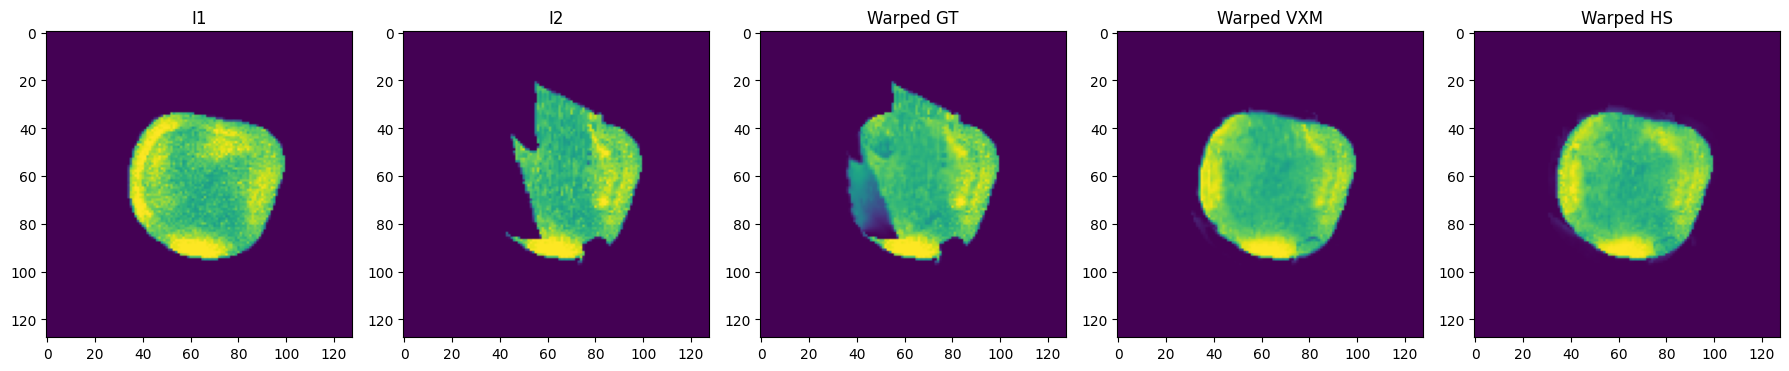

In [11]:
z = 12

fig, axes = plt.subplots(1, 5, figsize=(18, 10))

axes[0].imshow(img[0, z])
axes[0].set_title("I1")
axes[1].imshow(img[1, z])
axes[1].set_title("I2")
axes[2].imshow(warped_gt[z])
axes[2].set_title("Warped GT")
# axes[3].imshow(warped_fista[z])
# axes[3].set_title("Warped FISTA")
axes[3].imshow(warped_vxm[z])
axes[3].set_title("Warped VXM")
axes[4].imshow(warped_hs[z])
axes[4].set_title("Warped HS")

plt.tight_layout()
plt.show()

NameError: name 'h_fista_final' is not defined

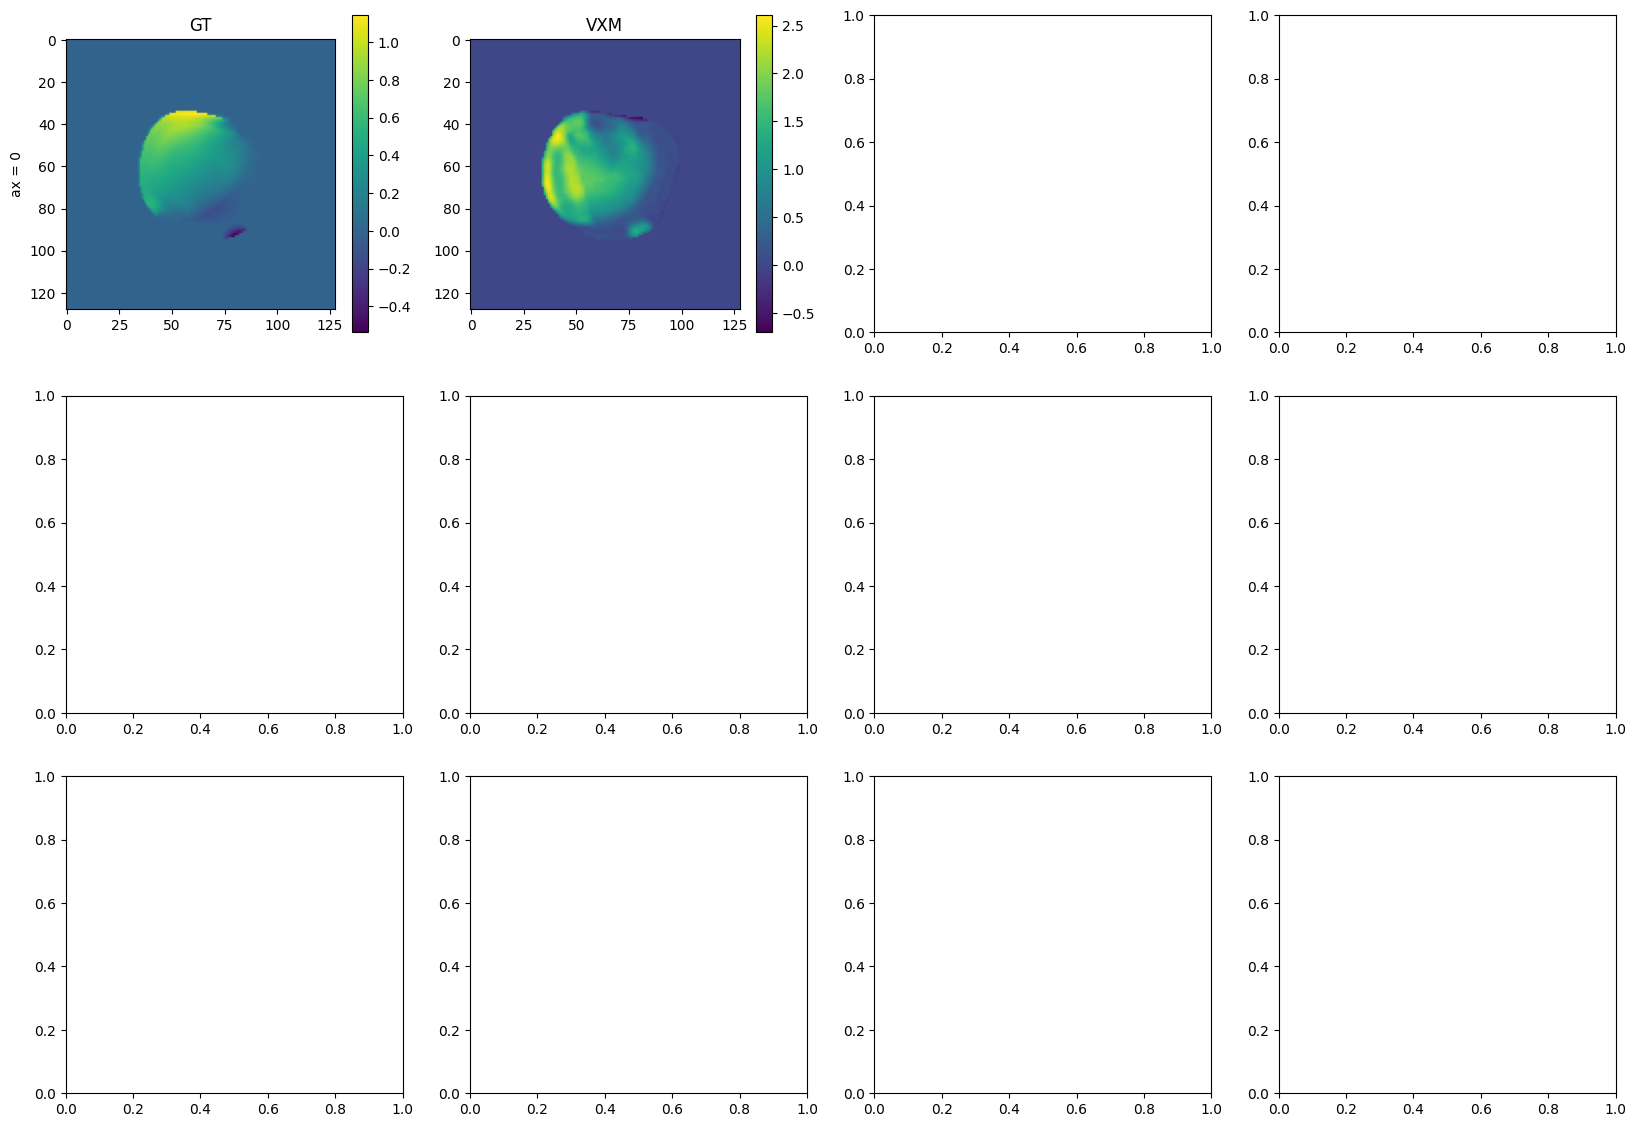

In [12]:
z = 12

fig, axes = plt.subplots(3, 4, figsize=(20, 14))

im00 = axes[0, 0].imshow(u_gt[0, z])
fig.colorbar(im00, ax=axes[0, 0])
axes[0, 0].set_title("GT")
axes[0, 0].set_ylabel("ax = 0")
im01 = axes[0, 1].imshow(dis_vxm_final[0, 0, z])
fig.colorbar(im01, ax=axes[0, 1])
axes[0, 1].set_title("VXM")
im02 = axes[0, 2].imshow(h_fista_final[0, 0, z])
fig.colorbar(im02, ax=axes[0, 2])
axes[0, 2].set_title("FISTA")
im03 = axes[0, 3].imshow(h_hs_final[0, 0, z])
fig.colorbar(im03, ax=axes[0, 3])
axes[0, 3].set_title("HS")

im10 = axes[1, 0].imshow(u_gt[1, z])
fig.colorbar(im10, ax=axes[1, 0])
axes[1, 0].set_ylabel("ax = 1")
im11 = axes[1, 1].imshow(dis_vxm_final[1, 0, z])
fig.colorbar(im11, ax=axes[1, 1])
im12 = axes[1, 2].imshow(h_fista_final[1, 0, z])
fig.colorbar(im12, ax=axes[1, 2])
im13 = axes[1, 3].imshow(h_hs_final[1, 0, z])
fig.colorbar(im13, ax=axes[1, 3])

im20 = axes[2, 0].imshow(u_gt[2, z])
fig.colorbar(im20, ax=axes[2, 0])
axes[2, 0].set_ylabel("ax = 2")
im21 = axes[2, 1].imshow(dis_vxm_final[2, 0, z])
fig.colorbar(im21, ax=axes[2, 1])
im22 = axes[2, 2].imshow(h_fista_final[2, 0, z])
fig.colorbar(im22, ax=axes[2, 2])
im23 = axes[2, 3].imshow(h_hs_final[2, 0, z])
fig.colorbar(im23, ax=axes[2, 3])

plt.tight_layout()
plt.show()

In [49]:
path_results_of = Path('/Users/josephinelahmani/helix_mount/data/synthetic/computed_flows')

for algo in ['fista', 'hs', 'tvl1']: 
    csv_path = f'{path_results_of}/metrics_{algo}.csv'
    with open(csv_path, newline="") as f:
        reader = csv.DictReader(f)
        for row in reader:
            if row["image"] == "MEAN":
                norm_warped = float(row["norm_warped_minus_I1"])
                rmse_warped = float(row["rmse_warped_minus_I1"])

                print(
                    f"{algo:20s} | "
                    f"Norm warped - I1: {norm_warped:.6f} | "
                    f"RMSE warped - I1: {rmse_warped:.6f}"
                )
                break

fista                | Norm warped - I1: 17.720869 | RMSE warped - I1: 0.024474
hs                   | Norm warped - I1: 15.030830 | RMSE warped - I1: 0.020759
tvl1                 | Norm warped - I1: 28.607501 | RMSE warped - I1: 0.039509


In [50]:
def get_new_spacing(
    original_shape,
    old_spacing=(1.0, 0.13, 0.13),
    target_d=32,
    target_h=128,
    target_w=128,
):
    old_d, old_h, old_w = original_shape
    spacing_d, spacing_h, spacing_w = old_spacing

    # D is padded in reshape_img, not resampled
    new_spacing_d = spacing_d

    # H/W are resampled
    new_spacing_h = spacing_h * old_h / target_h
    new_spacing_w = spacing_w * old_w / target_w

    return (new_spacing_d, new_spacing_h, new_spacing_w)

In [27]:
folder_img = Path('/Users/josephinelahmani/helix_mount/data/synthetic/test')
ugt_base_folder = Path('/Users/josephinelahmani/helix_mount/data/synthetic/all_data')
path_results_of = Path('/Users/josephinelahmani/helix_mount/data/synthetic/computed_flows')
path_results_vxm = Path('/Users/josephinelahmani/helix_mount/data/synthetic/computed_vxm')

rmse_vxm, rmse_fista, rmse_hs, rmse_tvl1 = [], [], [], []

for path_img in folder_img.iterdir():
    name_img = path_img.name
    ugt_name = name_img.replace('_img.npy', '_ugt.npy')
    ugt_path = ugt_base_folder / ugt_name
    ugt_init = np.load(ugt_path)
    u_gt = np.stack([reshape_img(ugt_init[0, 0]), reshape_img(ugt_init[2, 0]), reshape_img(ugt_init[1, 0])])
         
    dis_vxm, warped_vxm = np.load(f'{path_results_vxm}/flow_vxm_{name_img}_a_0.1_b_0 both types.npy'), np.load(f'{path_results_vxm}/warped_im_vxm_{name_img}_a_0.1_B_0 both types.npy')
    dis_fista, warped_fista = np.load(f'{path_results_of}/flow_fista_{name_img}'), np.load(f'{path_results_of}/warped_fista_{name_img}')
    dis_hs, warped_hs = np.load(f'{path_results_of}/flow_hs_{name_img}'), np.load(f'{path_results_of}/warped_hs_{name_img}')
    dis_tvl1, warped_tvl1 = np.load(f'{path_results_of}/flow_tvl1_{name_img}'), np.load(f'{path_results_of}/warped_tvl1_{name_img}')
    
    rmse_vxm.append(rmse(u_gt, dis_vxm[:,0]))
    rmse_fista.append(rmse(u_gt, dis_fista[:,0]))
    rmse_hs.append(rmse(u_gt, dis_hs[:,0]))
    rmse_tvl1.append(rmse(u_gt, dis_tvl1[:,0]))

In [28]:
print('RMSE')
print('vxm:', np.mean(rmse_vxm))
print('fista:', np.mean(rmse_fista))
print('hs:', np.mean(rmse_hs))
print('tvl1:', np.mean(rmse_tvl1))

RMSE
vxm: 0.12713799
fista: 0.15012826596177548
hs: 0.12460620598526874
tvl1: 0.12308354330875439


In [65]:
name_img = 'E_1000.0_nu_0.4_nb_zones_9_im_01_seed_05_img.npy'

ugt_name = name_img.replace('_img.npy', '_ugt.npy')
ugt_path = ugt_base_folder / ugt_name
ugt_init = np.load(ugt_path)
u_gt = np.stack([reshape_img(ugt_init[0, 0]), reshape_img(ugt_init[2, 0]), reshape_img(ugt_init[1, 0])])

folder_img = Path('/Users/josephinelahmani/helix_mount/data/synthetic/test')
path_img = folder_img / name_img

img, spacing, dis_vxm, warped_vxm = register(img_path=path_img, folder_path=results_folder, model_type='aniso', nb_warps=5) #np.load(f'{path_results_vxm}/flow_vxm_{name_img}_a_0.1_b_0 both types.npy'), np.load(f'{path_results_vxm}/warped_im_vxm_{name_img}_a_0.1_B_0 both types.npy')
dis_fista, warped_fista = np.load(f'{path_results_of}/flow_fista_{name_img}'), np.load(f'{path_results_of}/warped_fista_{name_img}')
dis_hs, warped_hs = np.load(f'{path_results_of}/flow_hs_{name_img}'), np.load(f'{path_results_of}/warped_hs_{name_img}')
dis_tvl1, warped_tvl1 = np.load(f'{path_results_of}/flow_tvl1_{name_img}'), np.load(f'{path_results_of}/warped_tvl1_{name_img}')

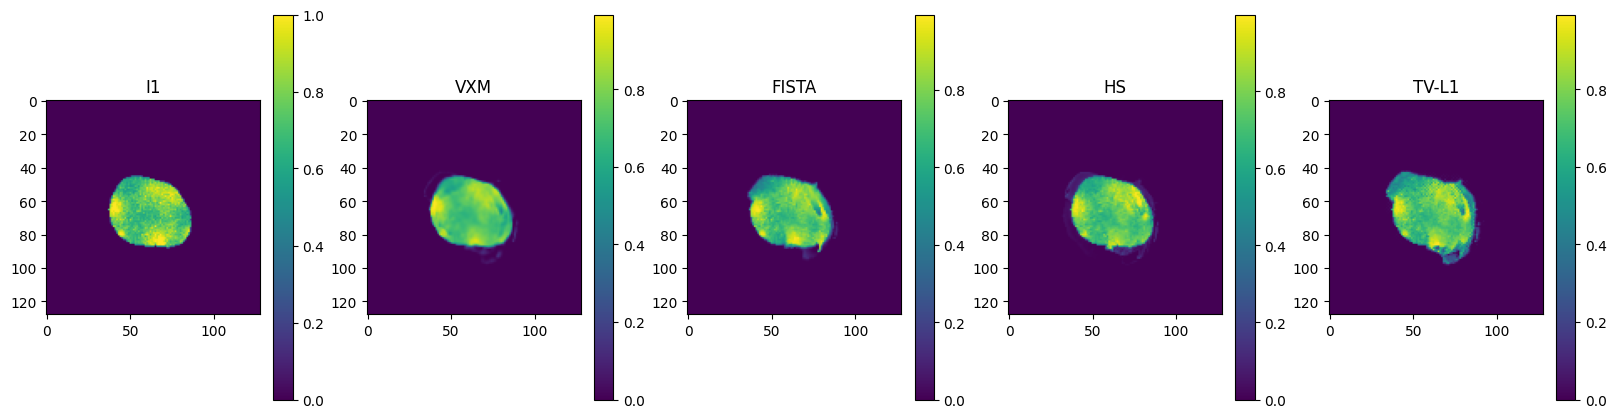

In [63]:
img_padded = np.load(f'{path_results_of}/init_im_{name_img}')

z = 19
ax = 0

fig, axes = plt.subplots(1, 5, figsize=(20, 5))
im0 = axes[0].imshow(img_padded[0, z])
fig.colorbar(im0, ax=axes[0])
axes[0].set_title('I1')
im1 = axes[1].imshow(warped_vxm[z])
fig.colorbar(im1, ax=axes[1])
axes[1].set_title('VXM')
im2 = axes[2].imshow(warped_fista[z])
fig.colorbar(im2, ax=axes[2])
axes[2].set_title('FISTA')
im3 = axes[3].imshow(warped_hs[z])
fig.colorbar(im3, ax=axes[3])
axes[3].set_title('HS')
im4 = axes[4].imshow(warped_tvl1[z])
fig.colorbar(im4, ax=axes[4])
axes[4].set_title('TV-L1')
plt.show()

In [68]:
dis_vxm = np.transpose(dis_vxm, (1, 0, 2, 3, 4))

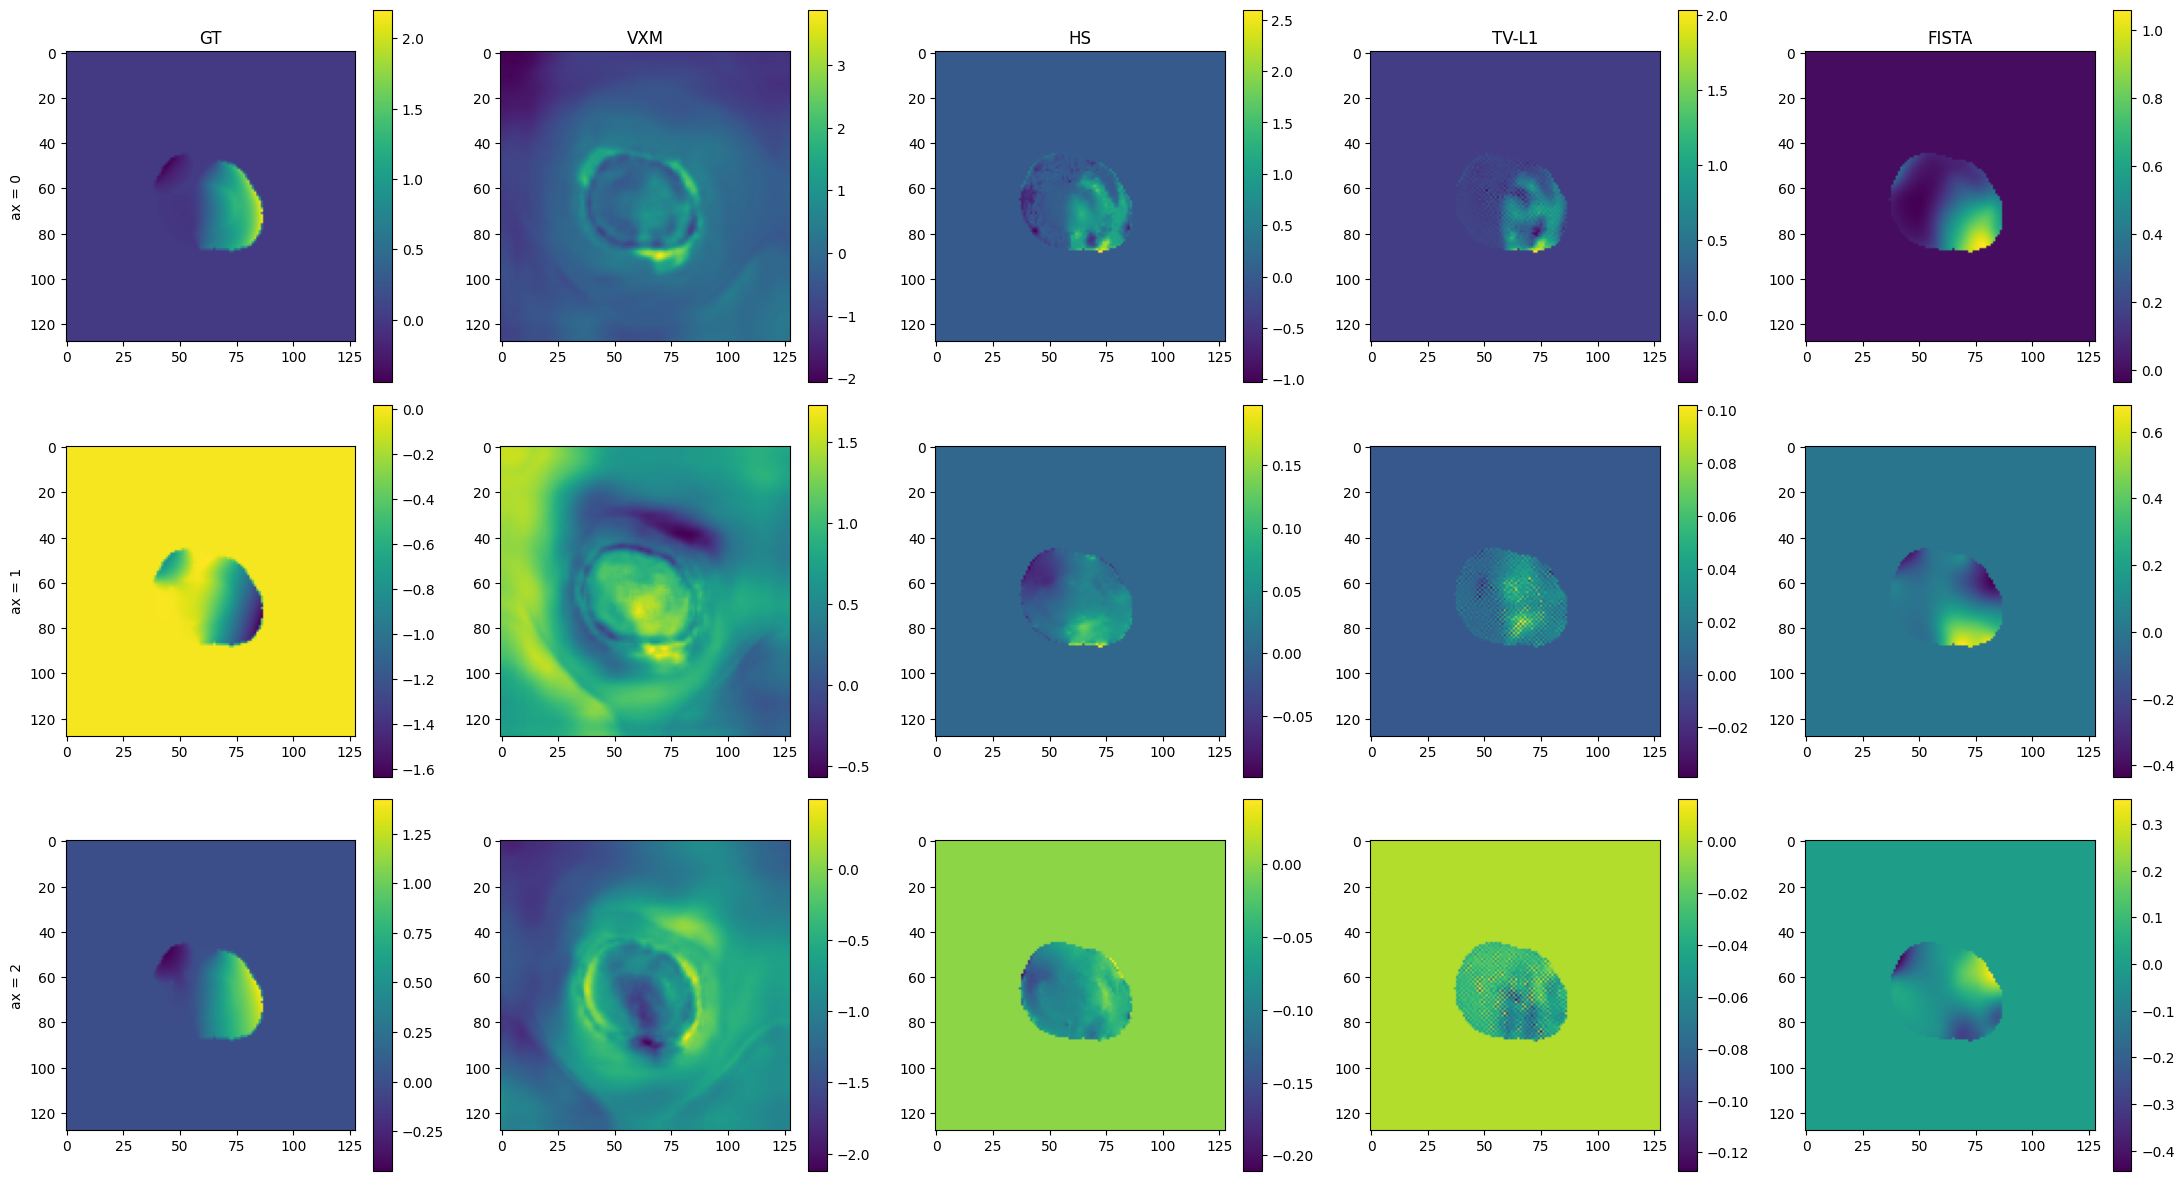

In [69]:
z = 19

fig, axes = plt.subplots(3, 5, figsize=(22, 12))

im00 = axes[0, 0].imshow(u_gt[0, z])
fig.colorbar(im00, ax=axes[0, 0])
axes[0, 0].set_title("GT")
axes[0, 0].set_ylabel("ax = 0")
im01 = axes[0, 1].imshow(dis_vxm[0, 0, z])
fig.colorbar(im01, ax=axes[0, 1])
axes[0, 1].set_title("VXM")
im02 = axes[0, 2].imshow(dis_hs[0, 0, z])
fig.colorbar(im02, ax=axes[0, 2])
axes[0, 2].set_title("HS")
im03 = axes[0, 3].imshow(dis_tvl1[0, 0, z])
fig.colorbar(im03, ax=axes[0, 3])
axes[0, 3].set_title("TV-L1")
im04 = axes[0, 4].imshow(dis_fista[0, 0, z])
fig.colorbar(im04, ax=axes[0, 4])
axes[0, 4].set_title("FISTA")

im10 = axes[1, 0].imshow(u_gt[1, z])
fig.colorbar(im10, ax=axes[1, 0])
axes[1, 0].set_ylabel("ax = 1")
im11 = axes[1, 1].imshow(dis_vxm[1, 0, z])
fig.colorbar(im11, ax=axes[1, 1])
im12 = axes[1, 2].imshow(dis_hs[1, 0, z])
fig.colorbar(im12, ax=axes[1, 2])
im13 = axes[1, 3].imshow(dis_tvl1[1, 0, z])
fig.colorbar(im13, ax=axes[1, 3])
im14 = axes[1, 4].imshow(dis_fista[1, 0, z])
fig.colorbar(im14, ax=axes[1, 4])

im20 = axes[2, 0].imshow(u_gt[2, z])
fig.colorbar(im20, ax=axes[2, 0])
axes[2, 0].set_ylabel("ax = 2")
im21 = axes[2, 1].imshow(dis_vxm[2, 0, z])
fig.colorbar(im21, ax=axes[2, 1])
im22 = axes[2, 2].imshow(dis_hs[2, 0, z])
fig.colorbar(im22, ax=axes[2, 2])
im23 = axes[2, 3].imshow(dis_tvl1[2, 0, z])
fig.colorbar(im23, ax=axes[2, 3])
im24 = axes[2, 4].imshow(dis_fista[2, 0, z])
fig.colorbar(im24, ax=axes[2, 4])

plt.tight_layout()
plt.show()

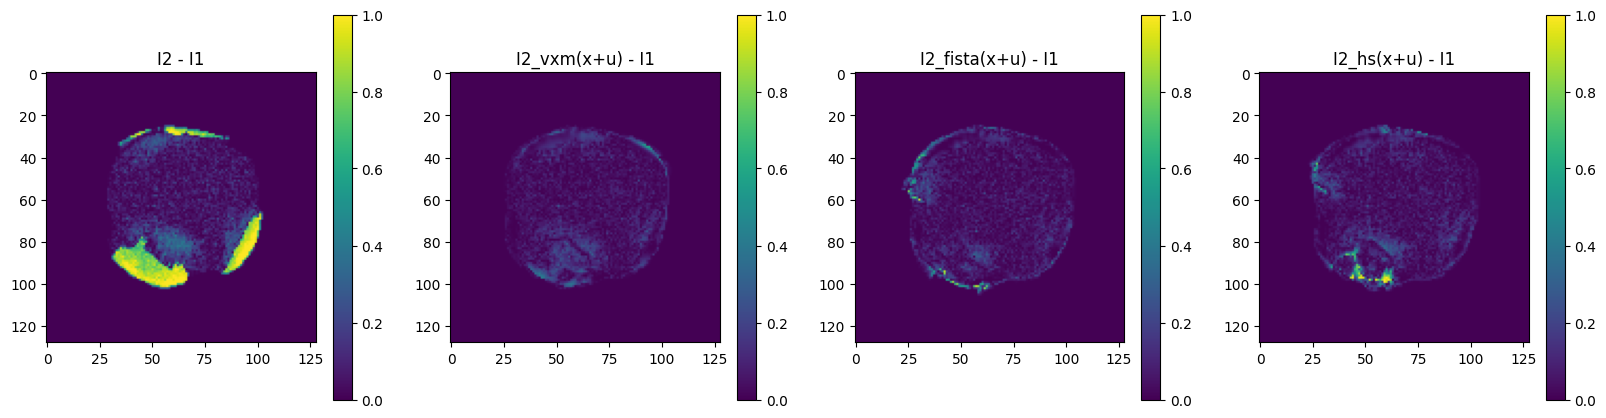

In [66]:
warped_vxm = w_synth

z_stack = 15

diff0 = np.abs(img_padded_synth[1, z_stack] - img_padded_synth[0, z_stack])
diff1 = np.abs(warped_vxm[z_stack] - img_padded_synth[0, z_stack])
diff2 = np.abs(warped_fista[z_stack] - img_padded_synth[0, z_stack])
diff3 = np.abs(warped_hs[z_stack] - img_padded_synth[0, z_stack])

vmin = min(diff0.min(), diff1.min(), diff2.min(), diff3.min())
vmax = max(diff0.max(), diff1.max(), diff2.max(), diff3.max())

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

im0 = axes[0].imshow(diff0, vmin=vmin, vmax=vmax)
fig.colorbar(im0, ax=axes[0])
axes[0].set_title('I2 - I1')

im1 = axes[1].imshow(diff1, vmin=vmin, vmax=vmax)
fig.colorbar(im1, ax=axes[1])
axes[1].set_title('I2_vxm(x+u) - I1')

im2 = axes[2].imshow(diff2, vmin=vmin, vmax=vmax)
fig.colorbar(im2, ax=axes[2])
axes[2].set_title('I2_fista(x+u) - I1')

im3 = axes[3].imshow(diff3, vmin=vmin, vmax=vmax)
fig.colorbar(im3, ax=axes[3])
axes[3].set_title('I2_hs(x+u) - I1')

plt.show()

In [28]:
diff_im = img_padded_synth[1] - img_padded_synth[0]
diff_fista = warped_fista_synth - img_padded_synth[0]
diff_hs = warped_hs_synth - img_padded_synth[0]
diff_vxm_synth = w_synth - img_padded_synth[0]

print('Norms')
print('I2 - I1:', np.linalg.norm(diff_im))
print('warped_fista - I1:', np.linalg.norm(diff_fista))
print('warped_hs - I1:', np.linalg.norm(diff_hs))
print('warped_vxm - I1:', np.linalg.norm(diff_vxm_synth))

print('RMSE')
print('I2 - I1:', rmse_(diff_im))
print('warped_fista - I1:', rmse_(diff_fista))
print('warped_hs - I1:', rmse_(diff_hs))
print('warped_vxm - I1:', rmse_(diff_vxm_synth))


Norms
I2 - I1: 81.198
warped_fista - I1: 22.131086
warped_hs - I1: 22.368484
warped_vxm - I1: 14.041929
RMSE
I2 - I1: 0.11213995516300201
warped_fista - I1: 0.030564535409212112
warped_hs - I1: 0.030892400071024895
warped_vxm - I1: 0.01939285919070244


## Microscopy

In [27]:
from optical_flow.algorithms import warp

with open("configs/optical_flow.yaml", "r") as f:
    cfg = yaml.safe_load(f)
    
fista_params = SimpleNamespace(**cfg["optical_flow"]["fista"])
hs_params = SimpleNamespace(**cfg["optical_flow"]["hs"])

In [28]:
results_folder = '/Users/josephinelahmani/helix_mount/nn_dis/results/train_11' 

crop = [(10,42), (300,750), (150,500)] # None
path_img = Path('/Users/josephinelahmani/Desktop/data/3D_img_sudheer/zstack_time_1_MMStack_Pos0.ome-1.tif') #Path('/Users/josephinelahmani/helix_mount/data/synthetic/test/E_500.0_nu_0.4_nb_zones_9_im_00_seed_08_img.npy') 
channel = 2 # None
default_spacing = None #[1.0, 0.13, 0.13]

img_padded_micro, spacing_micro, dis_vxm_micro, w_micro = register(img_path=path_img, folder_path=results_folder, model_type='aniso', nb_warps=5, channel=channel, default_spacing=default_spacing, crop=crop)

Attempted file (/Users/josephinelahmani/Desktop/data/3D_img_sudheer/zstack_time_1_MMStack_Pos0.ome-1.tif) load with reader: <class 'bioio_ome_tiff.reader.Reader'> failed with error: bioio-ome-tiff does not support the image: '/Users/josephinelahmani/Desktop/data/3D_img_sudheer/zstack_time_1_MMStack_Pos0.ome-1.tif'. Failed to parse XML for the provided file. Error: not well-formed (invalid token): line 1, column 6


In [29]:
dis_fista_micro = fista_of(img_padded_micro, fista_params, global_flow=True, spacing=spacing_micro)
dis_hs_micro = hs_of(img_padded_micro, hs_params, True)

warped_hs_micro = warp(img_padded_micro[1], dis_hs_micro[:, 1])
warped_fista_micro = warp(img_padded_micro[1], dis_fista_micro[:, 1], spacing_micro)

In [ ]:
warped_vxm = w_micro

z_stack = 20

diff0_micro = np.abs(img_padded_micro[1, z_stack] - img_padded_micro[0, z_stack])
diff1_micro = np.abs(warped_vxm[z_stack] - img_padded_micro[0, z_stack])
diff2_micro = np.abs(warped_fista_micro[z_stack] - img_padded_micro[0, z_stack])
diff3_micro = np.abs(warped_hs_micro[z_stack] - img_padded_micro[0, z_stack])

vmin = min(diff0_micro.min(), diff1_micro.min(), diff2_micro.min(), diff3_micro.min())
vmax = max(diff0_micro.max(), diff1_micro.max(), diff2_micro.max(), diff3_micro.max())

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

im0 = axes[0].imshow(diff0_micro, vmin=vmin, vmax=vmax)
fig.colorbar(im0, ax=axes[0])
axes[0].set_title('I2 - I1')

im1 = axes[1].imshow(diff1_micro, vmin=vmin, vmax=vmax)
fig.colorbar(im1, ax=axes[1])
axes[1].set_title('I2_vxm(x+u) - I1')

im2 = axes[2].imshow(diff2_micro, vmin=vmin, vmax=vmax)
fig.colorbar(im2, ax=axes[2])
axes[2].set_title('I2_fista(x+u) - I1')

im3 = axes[3].imshow(diff3_micro, vmin=vmin, vmax=vmax)
fig.colorbar(im3, ax=axes[3])
axes[3].set_title('I2_hs(x+u) - I1')

plt.show()

In [ ]:
diff_im_micro = img_padded_micro[1] - img_padded_micro[0]
diff_fista_micro = warped_fista_micro - img_padded_micro[0]
diff_hs_micro = warped_hs_micro - img_padded_micro[0]
diff_vxm_micro = w_micro - img_padded_micro[0]

print('Norms')
print('I2 - I1:', np.linalg.norm(diff_im_micro))
print('warped_fista - I1:', np.linalg.norm(diff_fista_micro))
print('warped_hs - I1:', np.linalg.norm(diff_hs_micro))
print('warped_vxm - I1:', np.linalg.norm(diff_vxm_micro))

print('RMSE')
print('I2 - I1:', rmse_(diff_im_micro))
print('warped_fista - I1:', rmse_(diff_fista_micro))
print('warped_hs - I1:', rmse_(diff_hs_micro))
print('warped_vxm - I1:', rmse_(diff_vxm_micro))

# Mechanics

In [103]:
strain_fista = strain_mask(dis_fista[:,1:], new_spacing, mask_padded[0])
strain_hs = strain_mask(dis_hs[:,1:], [1, 1, 1], mask_padded[0])
strain_vxm = strain_mask(dis_vxm, [1, 1, 1], mask_padded[0])

In [104]:
def_fista = deformation(strain_fista)
def_hs = deformation(strain_hs)
def_vxm = deformation(strain_vxm)

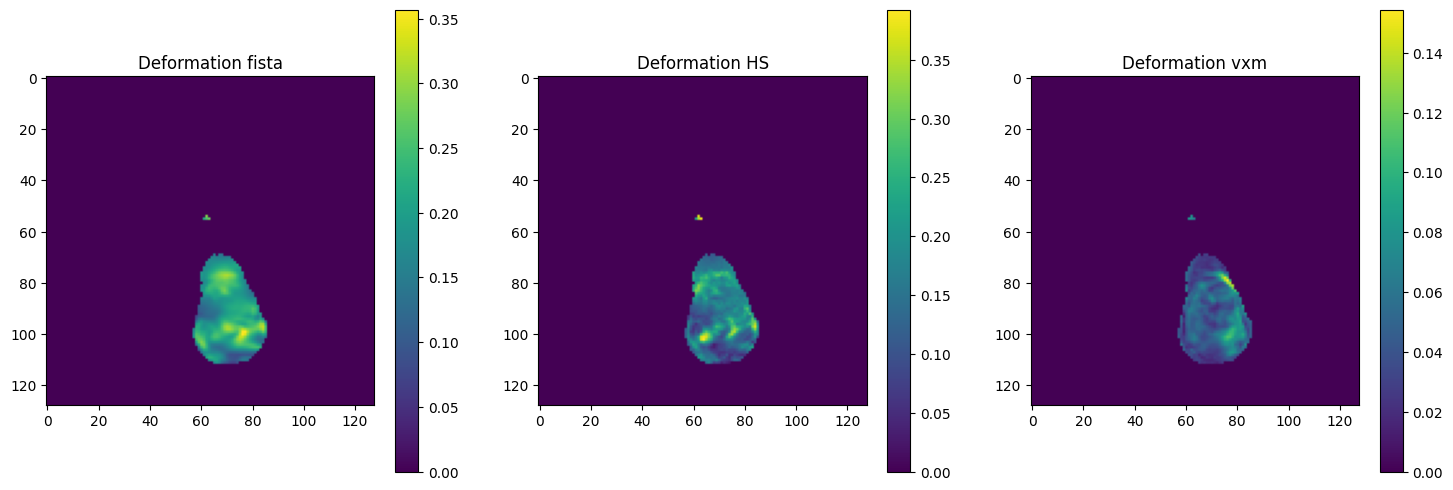

In [105]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
im0 = axes[0].imshow(def_fista[0, z_stack])
fig.colorbar(im0, ax=axes[0])
axes[0].set_title('Deformation fista')
im1 = axes[1].imshow(def_hs[0, z_stack])
fig.colorbar(im1, ax=axes[1])
axes[1].set_title('Deformation HS')
im2 = axes[2].imshow(def_vxm[0, z_stack])
fig.colorbar(im2, ax=axes[2])
axes[2].set_title('Deformation vxm')
plt.show()

In [ ]:
from optical_flow.algorithms import warp

def compute_mse_images(computed_flows_dir, images_dir, model, z_stack):
    single_computed_flow_files = list(computed_flows_dir.glob("flow_vxm*.npy"))
    
    for cf_path in single_computed_flow_files:
        cf_name = cf_path.name

        base_name = cf_name.replace('flow_vxm', '').replace('.npy', '')
        img_path = os.path.join(images_dir, base_name)
        
        img_padded, displacement, warped_source = get_img_and_results(img_path, model, default_spacing=[1.0, 0.13, 0.13])

        dis_fista = np.load(computed_flows_dir / f"flow_fista_{base_name}.npy")
        dis_hs = np.load(computed_flows_dir / f"flow_hs_{base_name}.npy")
        dis_tvl1 = np.load(computed_flows_dir / f"flow_tvl1_{base_name}.npy")
        
        warped_fista = warp(img_padded[1], dis_fista[:, 0])
        warped_hs = warp(img_padded[1], dis_hs[:, 0])       
        warped_tvl1 = warp(img_padded[1], dis_tvl1[:, 0])
        warped_vxm = warped_source.detach().numpy()[0,0]

        fig, axes = plt.subplots(1, 5, figsize=(25, 5))
        im0 = axes[0].imshow(img_padded[0, z_stack] -  img_padded[1, z_stack])
        fig.colorbar(im0, ax = axes[0])
        axes[0].set_title('Target - source')
        im1 = axes[1].imshow(img_padded[0, z_stack] -  warped_fista[z_stack])
        fig.colorbar(im1, ax = axes[1])
        axes[1].set_title('Fista warped - source')
        im2 = axes[2].imshow(img_padded[0, z_stack] -  warped_hs[z_stack])
        fig.colorbar(im2, ax = axes[2])
        axes[2].set_title('HS warped - source')
        im3 = axes[3].imshow(img_padded[0, z_stack] -  warped_tvl1[z_stack])
        fig.colorbar(im3, ax = axes[3])
        axes[3].set_title('TVL1 warped - source')
        im4 = axes[4].imshow(img_padded[0, z_stack] -  warped_vxm[z_stack])
        fig.colorbar(im4, ax = axes[4])
        axes[4].set_title('VXM warped - source')
        plt.show()

In [31]:
compute_mse_images(save_path, folder, model_aniso, 15)

TypeError: get_img_and_results() got an unexpected keyword argument 'spacing'

In [25]:
folder = Path('/Users/josephinelahmani/Desktop/nn_dis/tests/testOF')

save_path = Path('/Users/josephinelahmani/Desktop/nn_dis/tests/computed_flows')
save_path.mkdir(exist_ok=True)

save_flow_vxm(folder, model_aniso, save_path, '')

ValueError: too many values to unpack (expected 3)

In [68]:
def compute_rmse_all_methods(computed_flows_dir, gt_flow_dir):
    rmse_summary = []
    single_computed_flow_files = list(computed_flows_dir.glob("flow_vxm_*.npy"))
    
    for cf_path in single_computed_flow_files:
        cf_name = cf_path.name

        base_name = cf_name.replace('flow_vxm_', '')

        ugt_name = base_name.replace('_img.npy', '_ugt.npy')

        ugt_path = gt_flow_dir / ugt_name
        dis_gt_init = np.load(ugt_path)
        dis_gt = np.stack([reshape_img(dis_gt_init[0, 0], 32), reshape_img(dis_gt_init[1, 0], 32), reshape_img(dis_gt_init[2, 0], 32)])
        dis_fista = np.load(computed_flows_dir / f"flow_fista_{base_name}")
        dis_hs = np.load(computed_flows_dir / f"flow_hs_{base_name}")
        dis_tvl1 = np.load(computed_flows_dir / f"flow_tvl1_{base_name}")
        dis_vxm = np.load(computed_flows_dir / f"flow_vxm_{base_name}")
        
        rmse_fista = rmse(dis_fista[:,0], dis_gt)
        rmse_hs = rmse(dis_hs[:,0], dis_gt)
        rmse_tvl1 = rmse(dis_tvl1[:,0], dis_gt)
        rmse_vxm = rmse(dis_vxm[:,0], dis_gt)

        rmse_summary.append({
            "img_name": cf_name,
            "rmse_fista": float(rmse_fista),
            "rmse_hs": float(rmse_hs),
            "rmse_tvl1": float(rmse_tvl1),
            "rmse_vxm": float(rmse_vxm),
        })
    
    return rmse_summary

def compute_lame(E, nu):
    """
    Computes the Lamé parameters (μ and λ) from Young’s modulus and Poisson’s ratio.

    Args:
        E (float):
            Young’s modulus of the material.
        nu (float):
            Poisson’s ratio of the material.

    Returns:
        tuple[float, float]:
            - `mu_e` (float): Shear modulus (μ).
            - `lambda_e` (float): First Lamé parameter (λ).
    """
    lambda_e = E * nu / ((1.0 + nu) * (1.0 - 2.0 * nu))
    mu_e = E / (2.0 * (1.0 + nu))
    return mu_e, lambda_e


def compute_mec_stuff(name, computed_flows_dir, gt_flow_dir, mask, normals):

    ugt_name = name.replace('_img.npy', '_ugt.npy')

    ugt_path = gt_flow_dir / ugt_name
    
    matchE = re.search(r"E_(\d+)", name)
    if matchE is not None:
        E = float(matchE.group(1))
        
    matchnu = re.search(r"_nu_(\d+)", name)
    if matchnu is not None:
        nu = float(matchnu.group(1))
    
    mu, lambda_ = compute_lame(E, nu)
    
    displacements = {
        "gt":    np.load(ugt_path),
        "fista": np.load(computed_flows_dir / f"flow_fista_{name}"),
        "hs":    np.load(computed_flows_dir / f"flow_hs_{name}"),
        "tvl1":  np.load(computed_flows_dir / f"flow_tvl1_{name}"),
        "vxm":   np.load(computed_flows_dir / f"flow_vxm_{name}")
    }
    
    results = {}
    dis_gt_init = displacements["gt"]
    dis_gt = np.stack([reshape_img(dis_gt_init[0, 0], 32), reshape_img(dis_gt_init[1, 0], 32), reshape_img(dis_gt_init[2, 0], 32)])
    dis_gt = np.expand_dims(dis_gt, axis=1)
    strain_gt = strain_mask(dis_gt, [1, 1, 1], mask)
    def_grad_gt = deformation(strain_gt)
    stress_gt = stress_mask(strain_gt, mu, lambda_)
    traction_gt = compute_traction_3d(stress_gt[:,:,0], -normals)

    results["gt"] = {
        "displacement": dis_gt,        
        "deformation":  def_grad_gt,
        "strain":       strain_gt,
        "stress":       stress_gt,
        "normals":      normals,
        "traction":     traction_gt,
    }

    methods = ["fista", "hs", "tvl1", "vxm"]
    
    for method in methods:
        dis = displacements[method]
        
        strain = strain_mask(dis, [1, 1, 1], mask)
        def_grad = deformation(strain)
        stress = stress_mask(strain, mu, lambda_)
        traction = compute_traction_3d(stress[:,:,0], -normals)

        results[method] = {
            "displacement": dis,        
            "deformation":  def_grad,
            "strain":       strain,
            "stress":       stress,
            "normals":      normals,
            "traction":     traction,
            
            "rmse_displacement": rmse(dis, dis_gt),
            "rmse_deformation":  rmse(def_grad, def_grad_gt),
            "rmse_strain":       rmse(strain, strain_gt),
            "rmse_stress":       rmse(stress, stress_gt),
            "rmse_traction":     rmse(traction, traction_gt),
        }

    return results

In [ ]:
computed_flows_dir = Path('/Users/josephinelahmani/Desktop/nn_dis/tests/computed_flows')
gt_flow_dir = Path('/Users/josephinelahmani/helix_mount/data/synthetic/all_data')

rmse_summary = compute_rmse_all_methods(computed_flows_dir, gt_flow_dir)

methods = ['rmse_fista', 'rmse_hs', 'rmse_tvl1', 'rmse_vxm']

avg = {m: np.mean([d[m] for d in rmse_summary]) for m in methods}

for method, value in avg.items():
    print(f"{method} : {value}")

In [ ]:
img_name = 'E_500.0_nu_0.4_nb_zones_9_im_00_seed_08_img.npy' #'E_1000.0_nu_0.4_nb_zones_9_im_01_seed_01_img.npy'
folder = Path('/Users/josephinelahmani/helix_mount/data/synthetic/test')
img_raw = np.load(folder / f"{img_name}")
q1, q99 = np.quantile(img_raw, [0.01, 0.99])
img = np.clip((img_raw - q1) / (q99 - q1), 0, 1)

img_padded = np.stack([reshape_img(img[0], 32), reshape_img(img[1], 32)], axis=0)

mask = img_padded[0] > 0.1

mask_eroded = ndi.binary_erosion(mask)
inner_boundary_gt = mask_eroded & (~ndi.binary_erosion(mask_eroded))
normals = compute_normals_from_mask_3d(mask_eroded)
normals[:, ~inner_boundary_gt] = 0

results = compute_mec_stuff(img_name, computed_flows_dir, gt_flow_dir, normals) 

In [42]:
metrics = ["displacement", "deformation", "strain", "stress", "traction"]
methods = ["fista", "hs", "tvl1", 'vxm']

for metric in metrics:
    print(f"\n{metric}")
    for method in methods:
        val = results[method][f"rmse_{metric}"]
        print(f"{method:<8} : {val:.6e}")


displacement
fista    : 1.428353e-01
hs       : 1.563871e-01
tvl1     : 1.521091e-01
vxm      : 1.635397e-01

deformation
fista    : 5.114334e-02
hs       : 4.766799e-02
tvl1     : 4.865333e-02
vxm      : 4.872380e-02

strain
fista    : 2.076933e-02
hs       : 2.262412e-02
tvl1     : 2.357346e-02
vxm      : 2.443072e-02

stress
fista    : 2.076933e+01
hs       : 2.262412e+01
tvl1     : 2.357346e+01
vxm      : 2.443072e+01

traction
fista    : 2.124405e+01
hs       : 2.268356e+01
tvl1     : 2.322456e+01
vxm      : 2.411972e+01


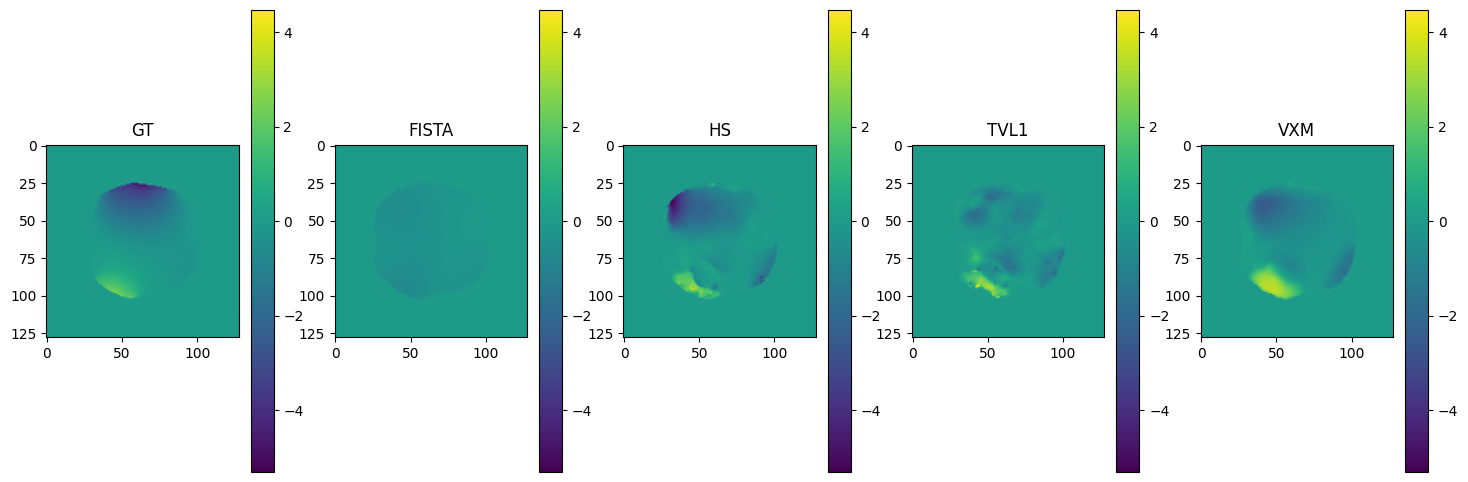

In [50]:
methods = ["gt", "fista", "hs", "tvl1", "vxm"]
method_titles = ["GT", "FISTA", "HS", "TVL1", "VXM"]
frame = 15
ax = 0

fig, axes = plt.subplots(1, len(methods), figsize=(18, 6))

all_values = np.concatenate([results[m]['displacement'][ax, 0, frame, :].ravel() for m in methods])
vmin, vmax = all_values.min(), all_values.max()

for j, m in enumerate(methods):
    im = axes[j].imshow(results[m]['displacement'][ax, 0, frame, :], vmin=vmin, vmax=vmax)
    fig.colorbar(im, ax=axes[j])

    axes[j].set_title(method_titles[j], fontsize=12)

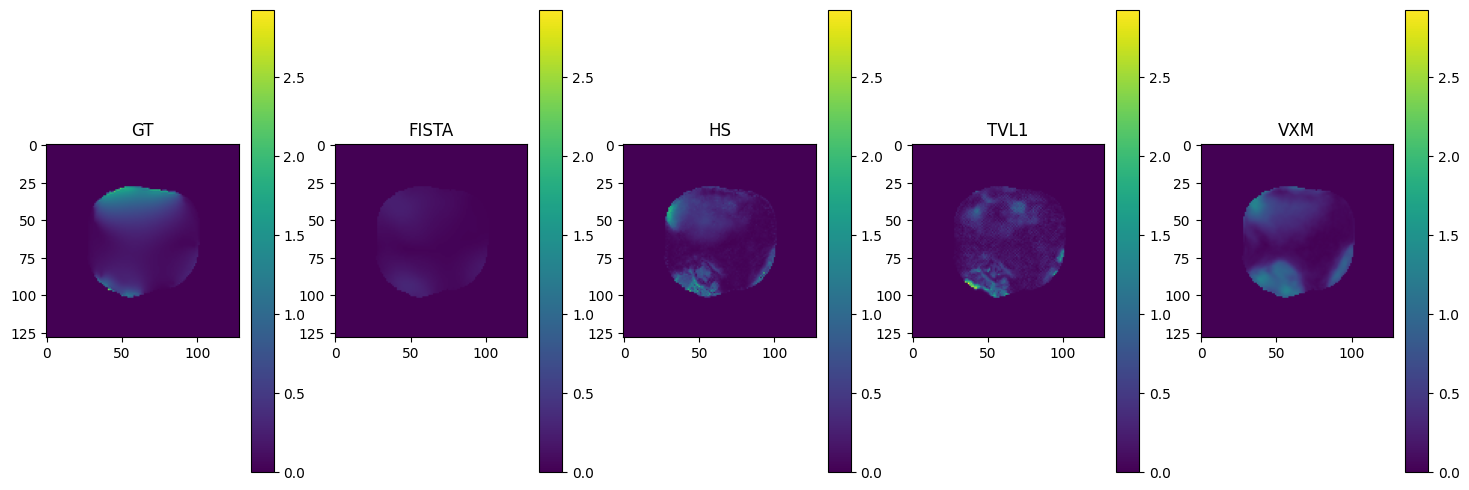

In [51]:
fig, axes = plt.subplots(1, len(methods), figsize=(18, 6))

all_values = np.concatenate([results[m]['deformation'][0, frame, :].ravel() for m in methods])
vmin, vmax = all_values.min(), all_values.max()

for j, m in enumerate(methods):
    im = axes[j].imshow(results[m]['deformation'][0, frame, :], vmin=vmin, vmax=vmax)
    fig.colorbar(im, ax=axes[j])

    axes[j].set_title(method_titles[j], fontsize=12)

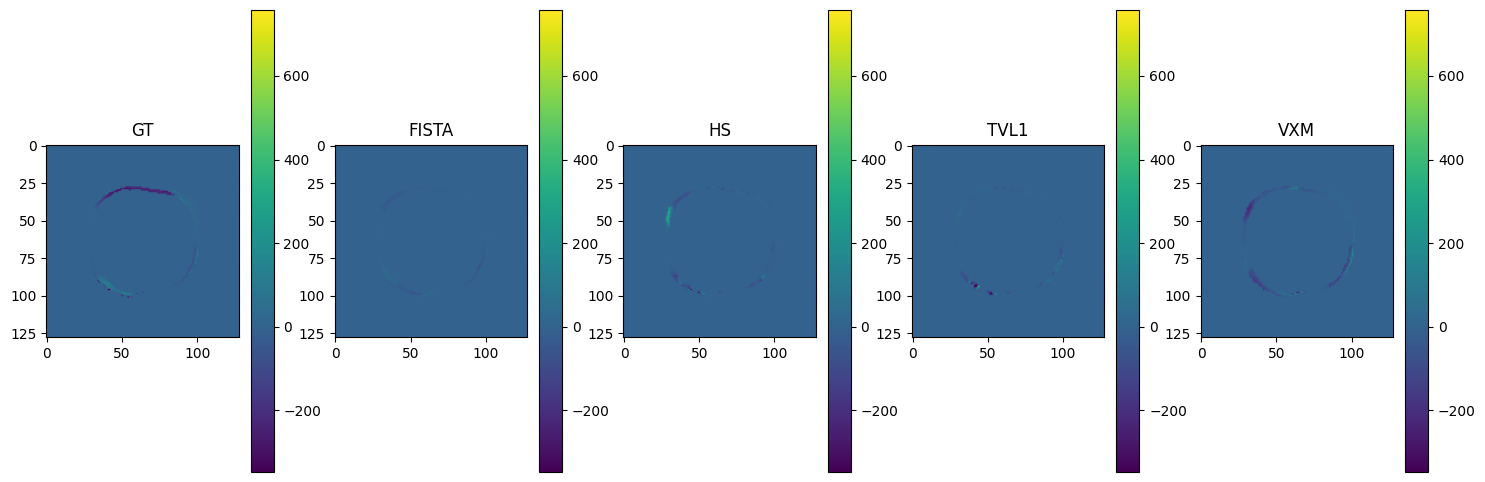

In [52]:
fig, axes = plt.subplots(1, len(methods), figsize=(18, 6))

all_values = np.concatenate([results[m]['traction'][1, frame, :].ravel() for m in methods])
vmin, vmax = all_values.min(), all_values.max()

for j, m in enumerate(methods):
    im = axes[j].imshow(results[m]['traction'][2, frame, :], vmin=vmin, vmax=vmax)
    fig.colorbar(im, ax=axes[j])

    axes[j].set_title(method_titles[j], fontsize=12)